# Rn-222 S1-Only Alpha Analysis - Pre-April 22

**Purpose:** Measure the Rn-222 alpha background rate in XENONnT SR3 commissioning data
using S1-only reconstruction. **Events before April 22nd only.**

**Data source:** Pre-loaded from `/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1only.pkl`

**Analysis steps:**
1. Load pre-saved DataFrame + apply pre-April-22 time cut
2. Exploratory visualization
3. Quality cuts: width + r2 FV only (AFT cut deferred to after corrections)
4. Correction 1: Area vs AFT (depth correction via exp_bump_model)
5. Correction 2: AFT vs r2 (polynomial fit + correction)
6. Correction 3: r2 vs Area (band selection + polynomial fit)
7. AFT + FV fiducial cuts (applied after corrections)
8. Multi-Gaussian rate fit (6 peaks)
9. Time variation plot

In [ ]:
# ═══════════════════════════════════════════════════════════════
# IMPORTS & SETUP
# ═══════════════════════════════════════════════════════════════
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import cutax
import strax
import straxen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 15)
pd.set_option('display.expand_frame_repr', False)

# ── Helper to avoid tight_layout warnings with colorbars ──
def safe_tight(fig=None):
    try:
        (fig or plt).tight_layout()
    except Exception:
        pass

print('Setup complete.')

Setup complete.


/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/xgboost/core.py:265: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc 2.28+) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s1_width.S1Width'>
  warnings.warn(f"Removing cut {cut}", UserWarning)
/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax/cut_lists/science.py:28: UserWarning: Removing cut <class 'cutax.cuts.s2_width.S2Width'>
  warnings.warn(f"Removing cu

In [ ]:
import pandas as pd
# Set the maximum column width to None to show full content
pd.set_option('display.max_colwidth', None)  # Show full content in each column

# Optionally, you can also set max rows and columns if needed
pd.set_option('display.max_rows', 300)  # Show all rows
pd.set_option('display.max_columns', 10)  # Show all columns
pd.set_option('display.expand_frame_repr', False)  # Prevent wrapping to a new line

In [ ]:
straxen.print_versions()

,module,version,path,git
0,python,3.11.8,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/bin/python,None
1,strax,2.2.1,/opt/XENONnT/anaconda/envs/XENONnT_el7.2025.07.2/lib/python3.11/site-packages/strax,None
2,straxen,3.2.8,/home/jietang/straxen/straxen,branch:daq-vanilla | ee950bb
3,cutax,2.3.1,/project2/lgrandi/xenonnt/software/cutax/v2.3.1/cutax,None


In [ ]:
# ===============================================================
# LOAD PRE-SAVED DATA + POST-APRIL-22 TIME CUT
# ===============================================================
# Data was previously loaded from peak_basics + naive_peak_positions
# and saved to this pickle. Columns include:
#   time, endtime, area, area_fraction_top, range_50p_area, type,
#   x_naive, y_naive, x, y, r, r2, run_name
# Already filtered: type==1, area [5e3, 150e3] PE, range_50p_area [40, 200] ns

from datetime import datetime, timezone

df = pd.read_pickle('/project2/lgrandi/jietang/sr3_commissioning/sr3_s1only_alpha_peaks_s1s2.pkl')

print(f'Loaded: {len(df):,} S1 alpha candidates (before time cut)')
print(f'Time range: {datetime.fromtimestamp(df["time"].min()/1e9, tz=timezone.utc).strftime("%Y-%m-%d %H:%M")} -> '
      f'{datetime.fromtimestamp(df["time"].max()/1e9, tz=timezone.utc).strftime("%Y-%m-%d %H:%M")} UTC')

# Post-April-22 time cut
CUTOFF_DATE = '2026-05-01'
cutoff_dt = datetime.strptime(CUTOFF_DATE, '%Y-%m-%d').replace(tzinfo=timezone.utc)
cutoff_ns = int(cutoff_dt.timestamp() * 1e9)

m_time = df['time'] >= cutoff_ns
df = df[m_time].copy().reset_index(drop=True)
df_peaks = df

print(f'\nAfter post-{cutoff_dt.strftime("%b %d, %Y")} time cut: {len(df):,} events')
print(f'Columns: {list(df.columns)}')
print(f'Run range: {df["run_name"].min()} - {df["run_name"].max()}')
print(f'  Number of runs: {df["run_name"].nunique()}')



Loaded: 50,454,373 S1 alpha candidates (before time cut)
Time range: 2026-03-18 11:51 -> 2026-07-06 14:29 UTC

After post-May 01, 2026 time cut: 46,793,595 events
Columns: ['time', 'endtime_x', 'area', 'area_fraction_top', 'range_50p_area', 'type', 'x_naive', 'y_naive', 'endtime_y', 'x', 'y', 'r', 'r2', 'run_name']
Run range: 079697 - 083618
  Number of runs: 574


In [ ]:
# ═══════════════════════════════════════════════════════════════
# BASIC STATISTICS
# ═══════════════════════════════════════════════════════════════
d = df_peaks

print(f'Total S1 alpha candidates: {len(d):,}')
print()
print(f'{"Column":25s} {"Min":>12s} {"Max":>12s} {"Mean":>12s} {"Median":>12s}')
print('-' * 75)

for col in ['area', 'area_fraction_top', 'range_50p_area', 'r', 'r2']:
    if col in d.columns:
        vals = d[col].dropna()
        print(f'{col:25s} {vals.min():12.1f} {vals.max():12.1f} {vals.mean():12.1f} {vals.median():12.1f}')

has_pos = d['x'].notna() if 'x' in d.columns else pd.Series(False, index=d.index)
print(f'\nEvents with position: {has_pos.sum():,} / {len(d):,} ({100*has_pos.sum()/len(d):.1f}%)')

Total S1 alpha candidates: 46,793,595

Column                             Min          Max         Mean       Median
---------------------------------------------------------------------------
area                               0.0     149980.2       1875.9          2.4
area_fraction_top             -13831.3      16188.9          0.4          0.5
range_50p_area                     0.0       1998.7         90.1         59.3
r                                  0.0         65.6         28.3         27.1
r2                                 0.0       4299.7       1022.2        735.2

Events with position: 46,793,595 / 46,793,595 (100.0%)


---
## Exploratory Visualization

6-panel overview of the data before applying cuts or corrections.

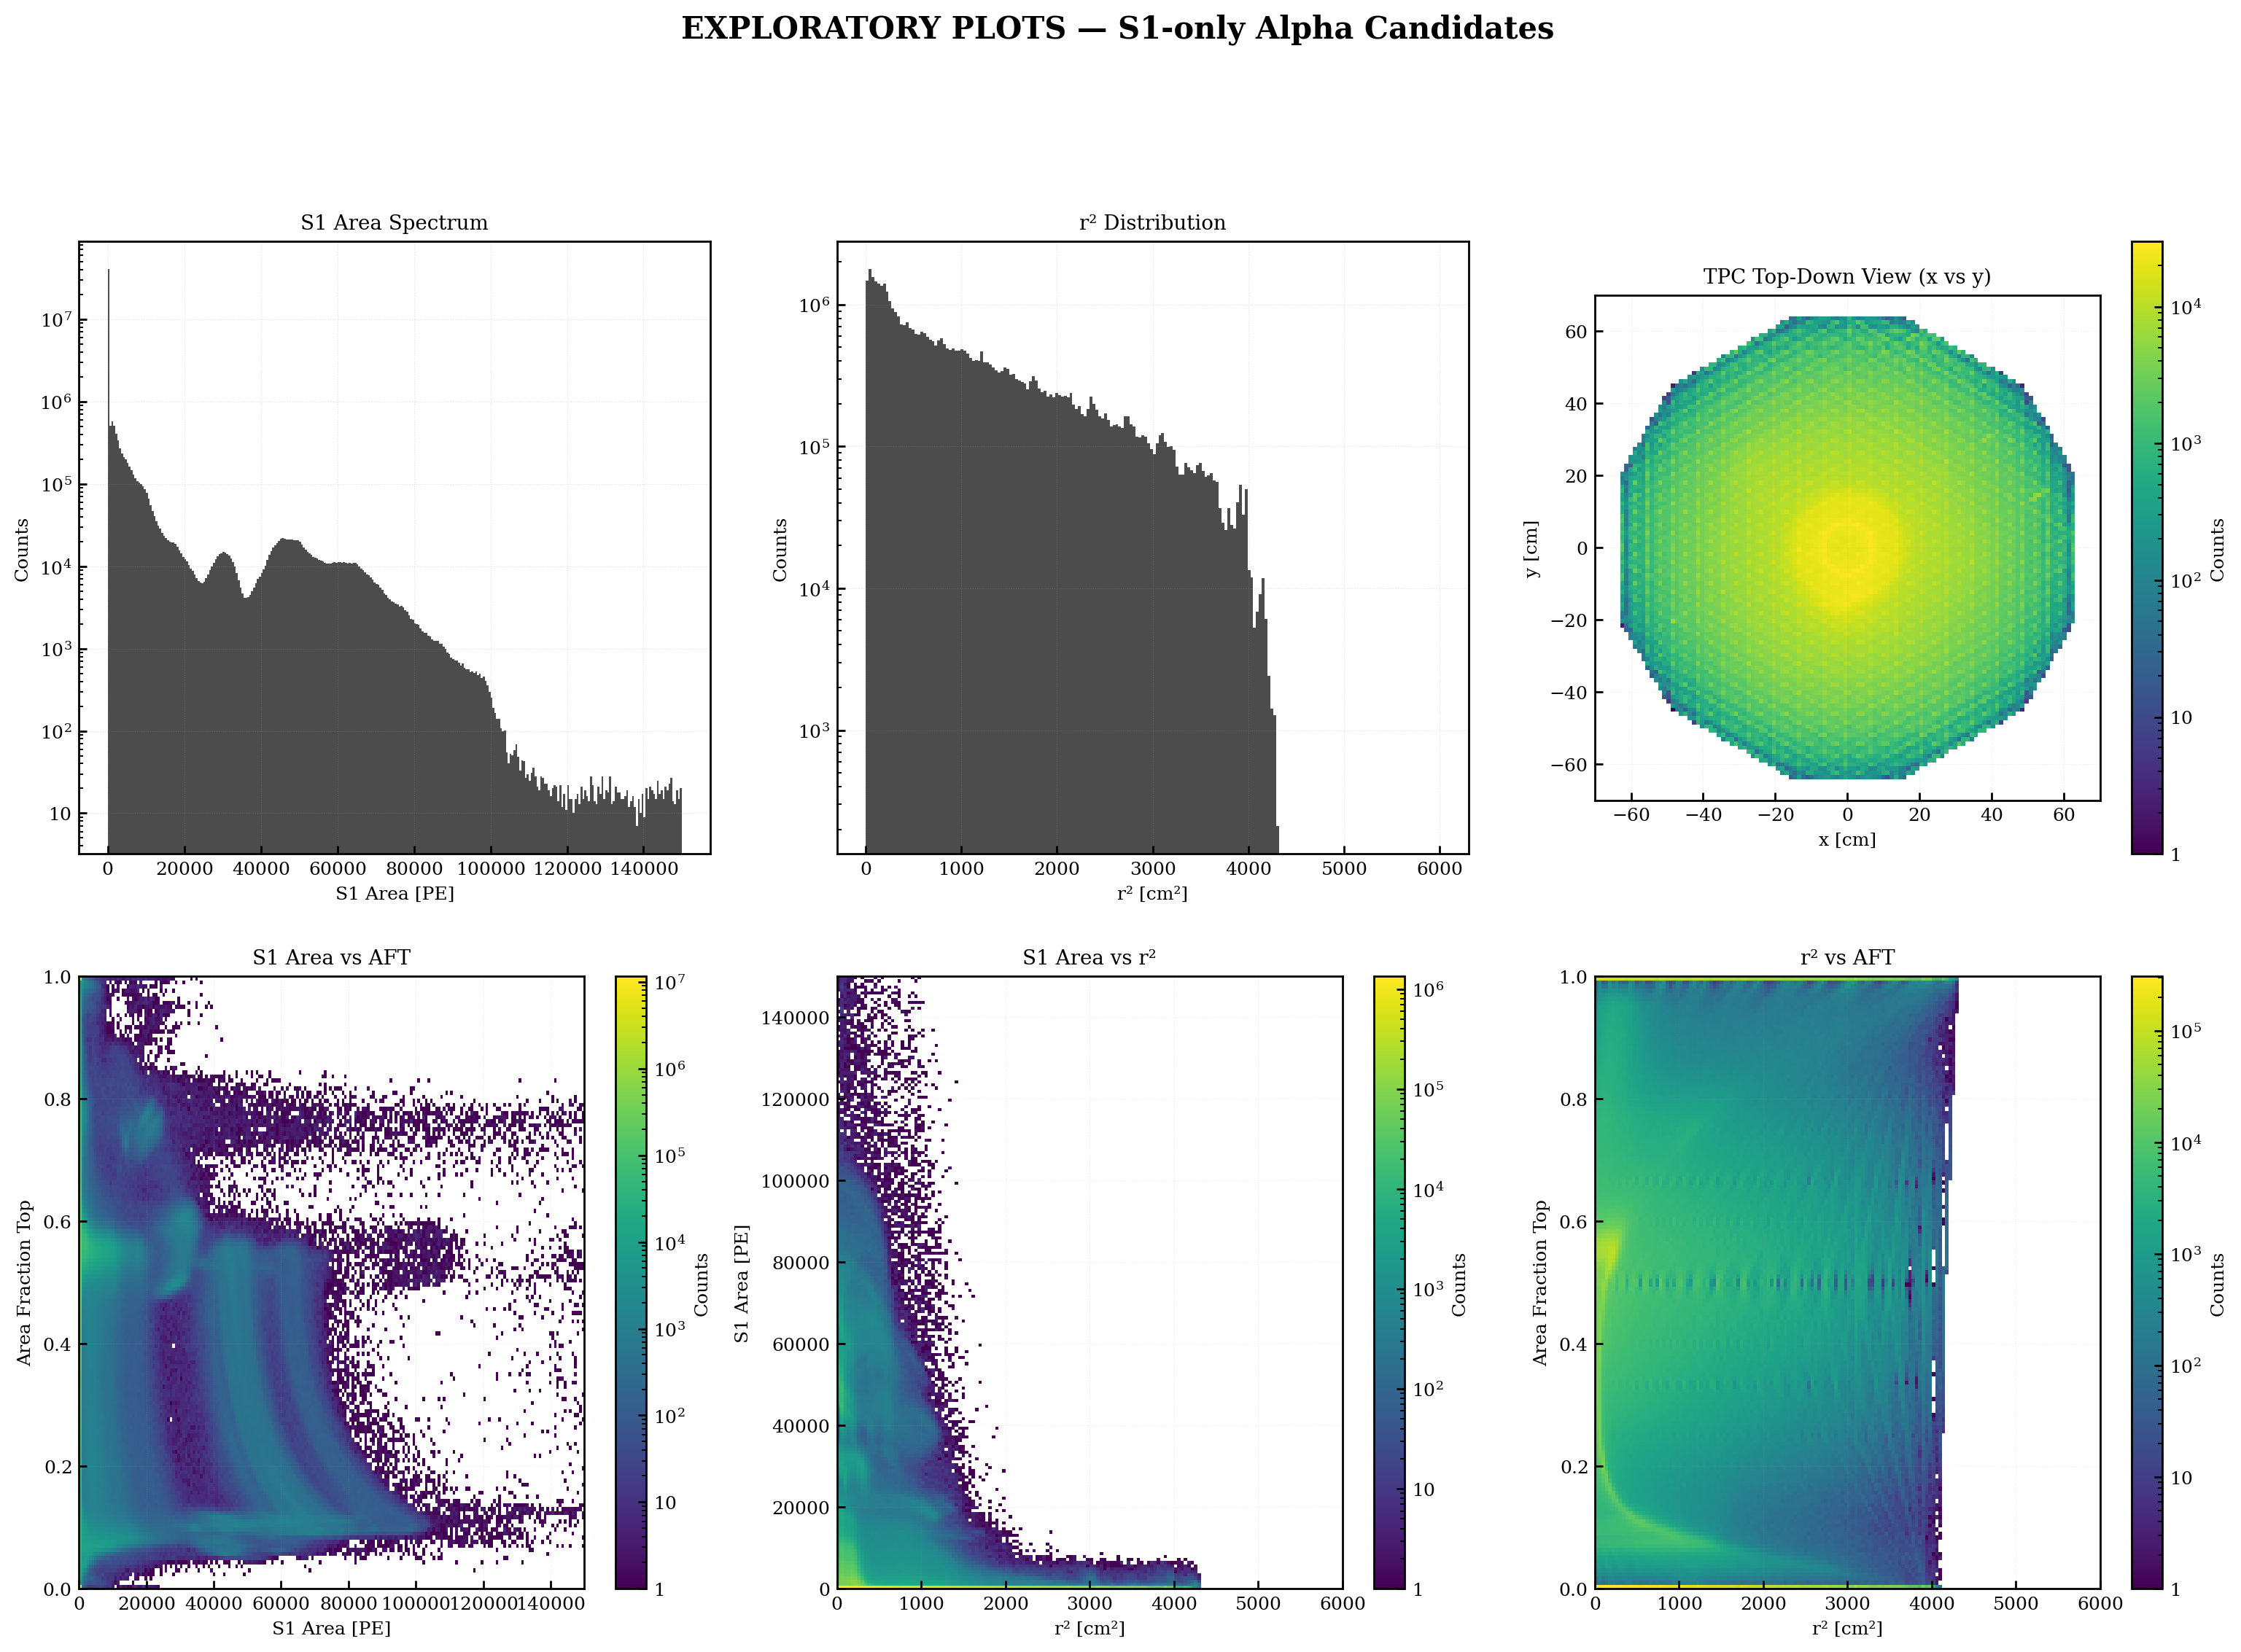

In [ ]:
# ═══════════════════════════════════════════════════════════════
# 6-PANEL EXPLORATORY PLOTS
# ═══════════════════════════════════════════════════════════════

d = df_peaks

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

# ── [0,0] S1 area 1D histogram ──
ax = axes[0, 0]
ax.hist(d['area'], bins=300, range=[0, 150e3],
        color='black', alpha=0.7)
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('S1 Area Spectrum', pad=15)ax.grid(True, alpha=0.3)

# ── [0,1] r² 1D histogram ──
ax = axes[0, 1]
if 'r2' in d.columns:
    ax.hist(d['r2'].dropna(), bins=200, range=[0, 6e3],
            color='black', alpha=0.7)
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('r² Distribution', pad=15)ax.grid(True, alpha=0.3)

# ── [0,2] x vs y (top-down view) ──
ax = axes[0, 2]
if 'x' in d.columns and 'y' in d.columns:
    mask_xy = d['x'].notna() & d['y'].notna()
    h = ax.hist2d(d.loc[mask_xy, 'x'], d.loc[mask_xy, 'y'],
                  bins=[120, 120], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('TPC Top-Down View (x vs y)', pad=15)ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

# ── [1,0] S1 Area vs AFT ──
ax = axes[1, 0]
h = ax.hist2d(d['area'], d['area_fraction_top'], bins=[200, 150],
              range=[[0, 150e3], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('S1 Area vs AFT', pad=15)ax.grid(True, alpha=0.2)

# ── [1,1] S1 Area vs r² ──
ax = axes[1, 1]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area'],
                  bins=[150, 200], range=[[0, 6e3], [0, 150e3]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('S1 Area [PE]')
ax.set_title('S1 Area vs r²', pad=15)ax.grid(True, alpha=0.2)

# ── [1,2] r² vs AFT ──
ax = axes[1, 2]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area_fraction_top'],
                  bins=[150, 150], range=[[0, 6e3], [0, 1.0]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r² vs AFT', pad=15)ax.grid(True, alpha=0.2)

plt.suptitle('EXPLORATORY PLOTS — S1-only Alpha Candidates',
             fontsize=15, fontweight='bold', y=1.01)
safe_tight(fig)
plt.show()

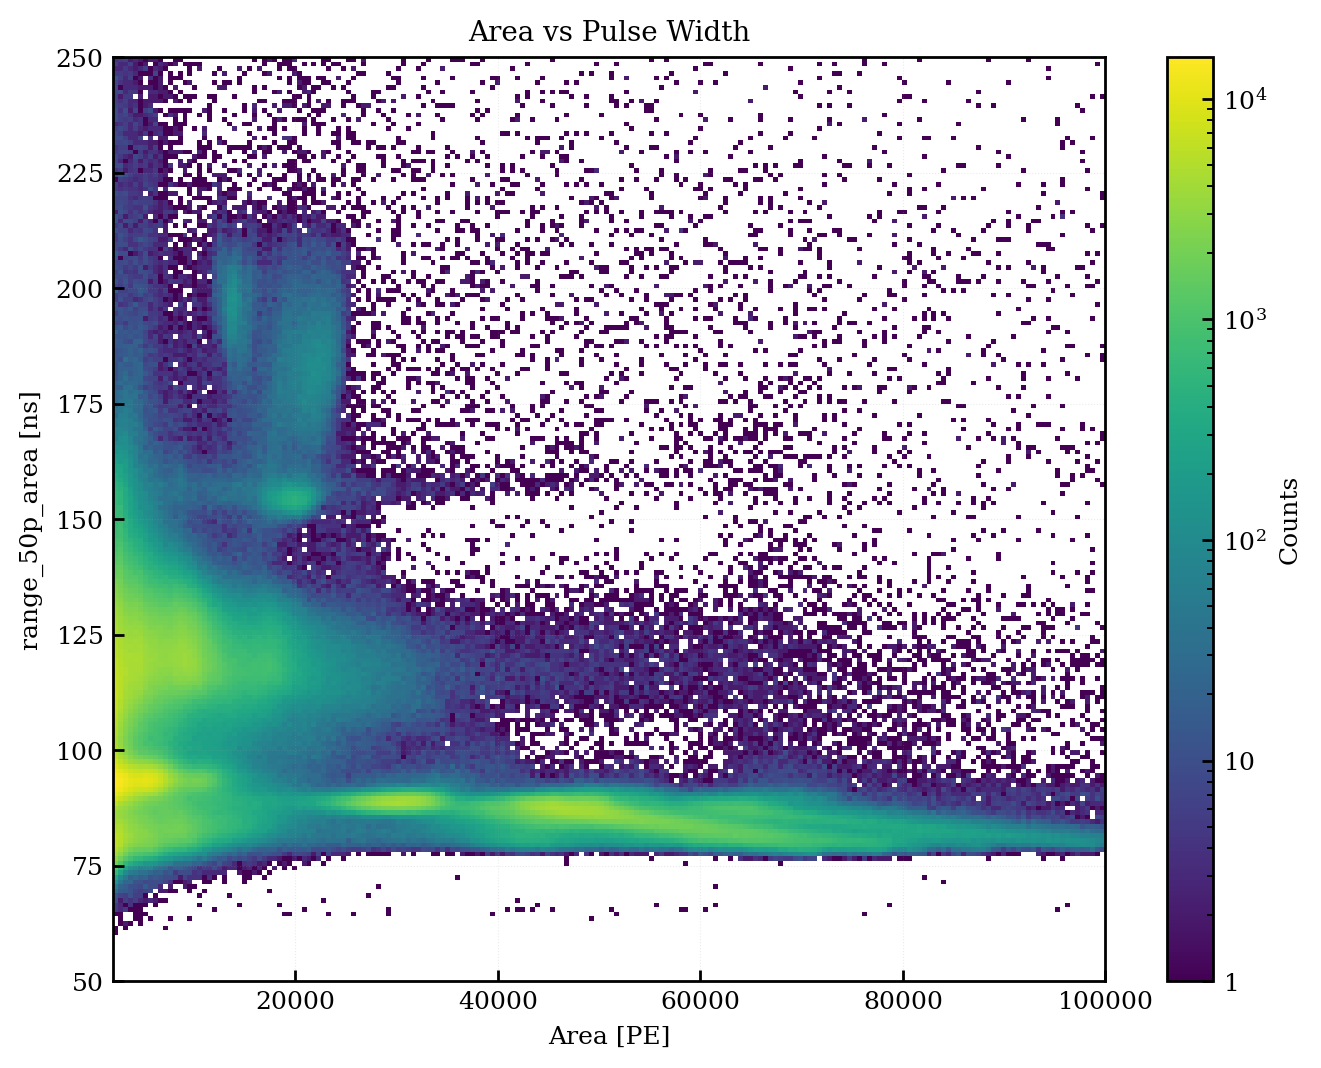

In [ ]:
# ═══════════════════════════════════════════════════════════════
# AREA vs WIDTH — verify alpha band separation
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(8, 6))
h = ax.hist2d(
    df_peaks['area'], df_peaks['range_50p_area'],
    bins=[200, 200], range=[[2e3, 100e3], [50, 250]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area [PE]')
ax.set_ylabel('range_50p_area [ns]')
ax.set_title('Area vs Pulse Width', pad=15)ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()

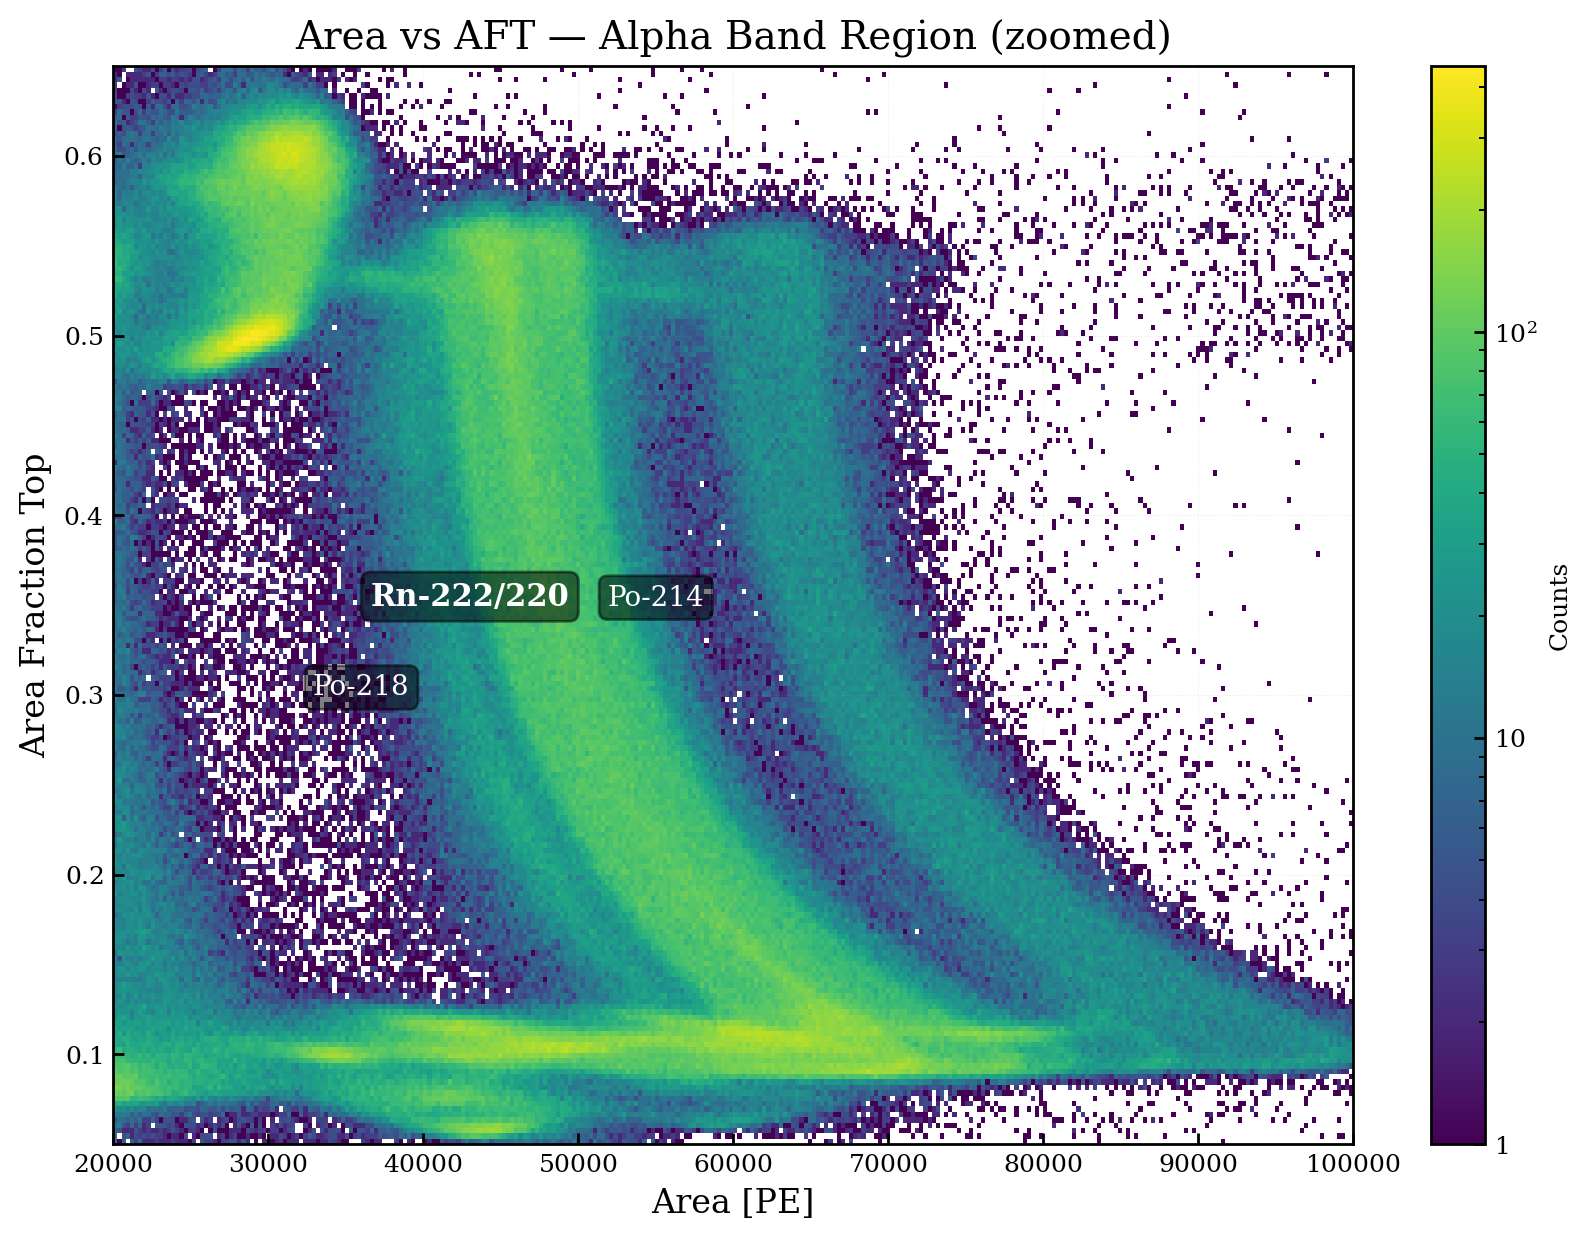

In [ ]:
# ═══════════════════════════════════════════════════════════════
# ZOOMED AREA vs AFT — alpha band region
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(10, 7))
h = ax.hist2d(
    df_peaks['area'], df_peaks['area_fraction_top'],
    bins=[300, 200], range=[[20e3, 100e3], [0.05, 0.65]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')

ax.annotate('Rn-222/220', xy=(43e3, 0.35), fontsize=11, color='white',
            fontweight='bold', ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))
ax.annotate('Po-218', xy=(36e3, 0.30), fontsize=10, color='white',
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))
ax.annotate('Po-214', xy=(55e3, 0.35), fontsize=10, color='white',
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))

ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Area vs AFT — Alpha Band Region (zoomed)', fontsize=14, pad=15)ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()

---
## Quality Cuts (Pre-Correction)

Apply cuts that don't depend on position corrections first.
**AFT fiducial cut is deferred** to after corrections so that r² vs AFT fit has the full AFT range.

| # | Cut | What it removes | Parameter |
|---|-----|-----------------|-----------|
| 1 | Width refinement | Non-alpha S1 pulses | 40 < width < 200 ns |
| 2 | r² fiducial volume | Events near TPC walls | r² < 3800 cm² |

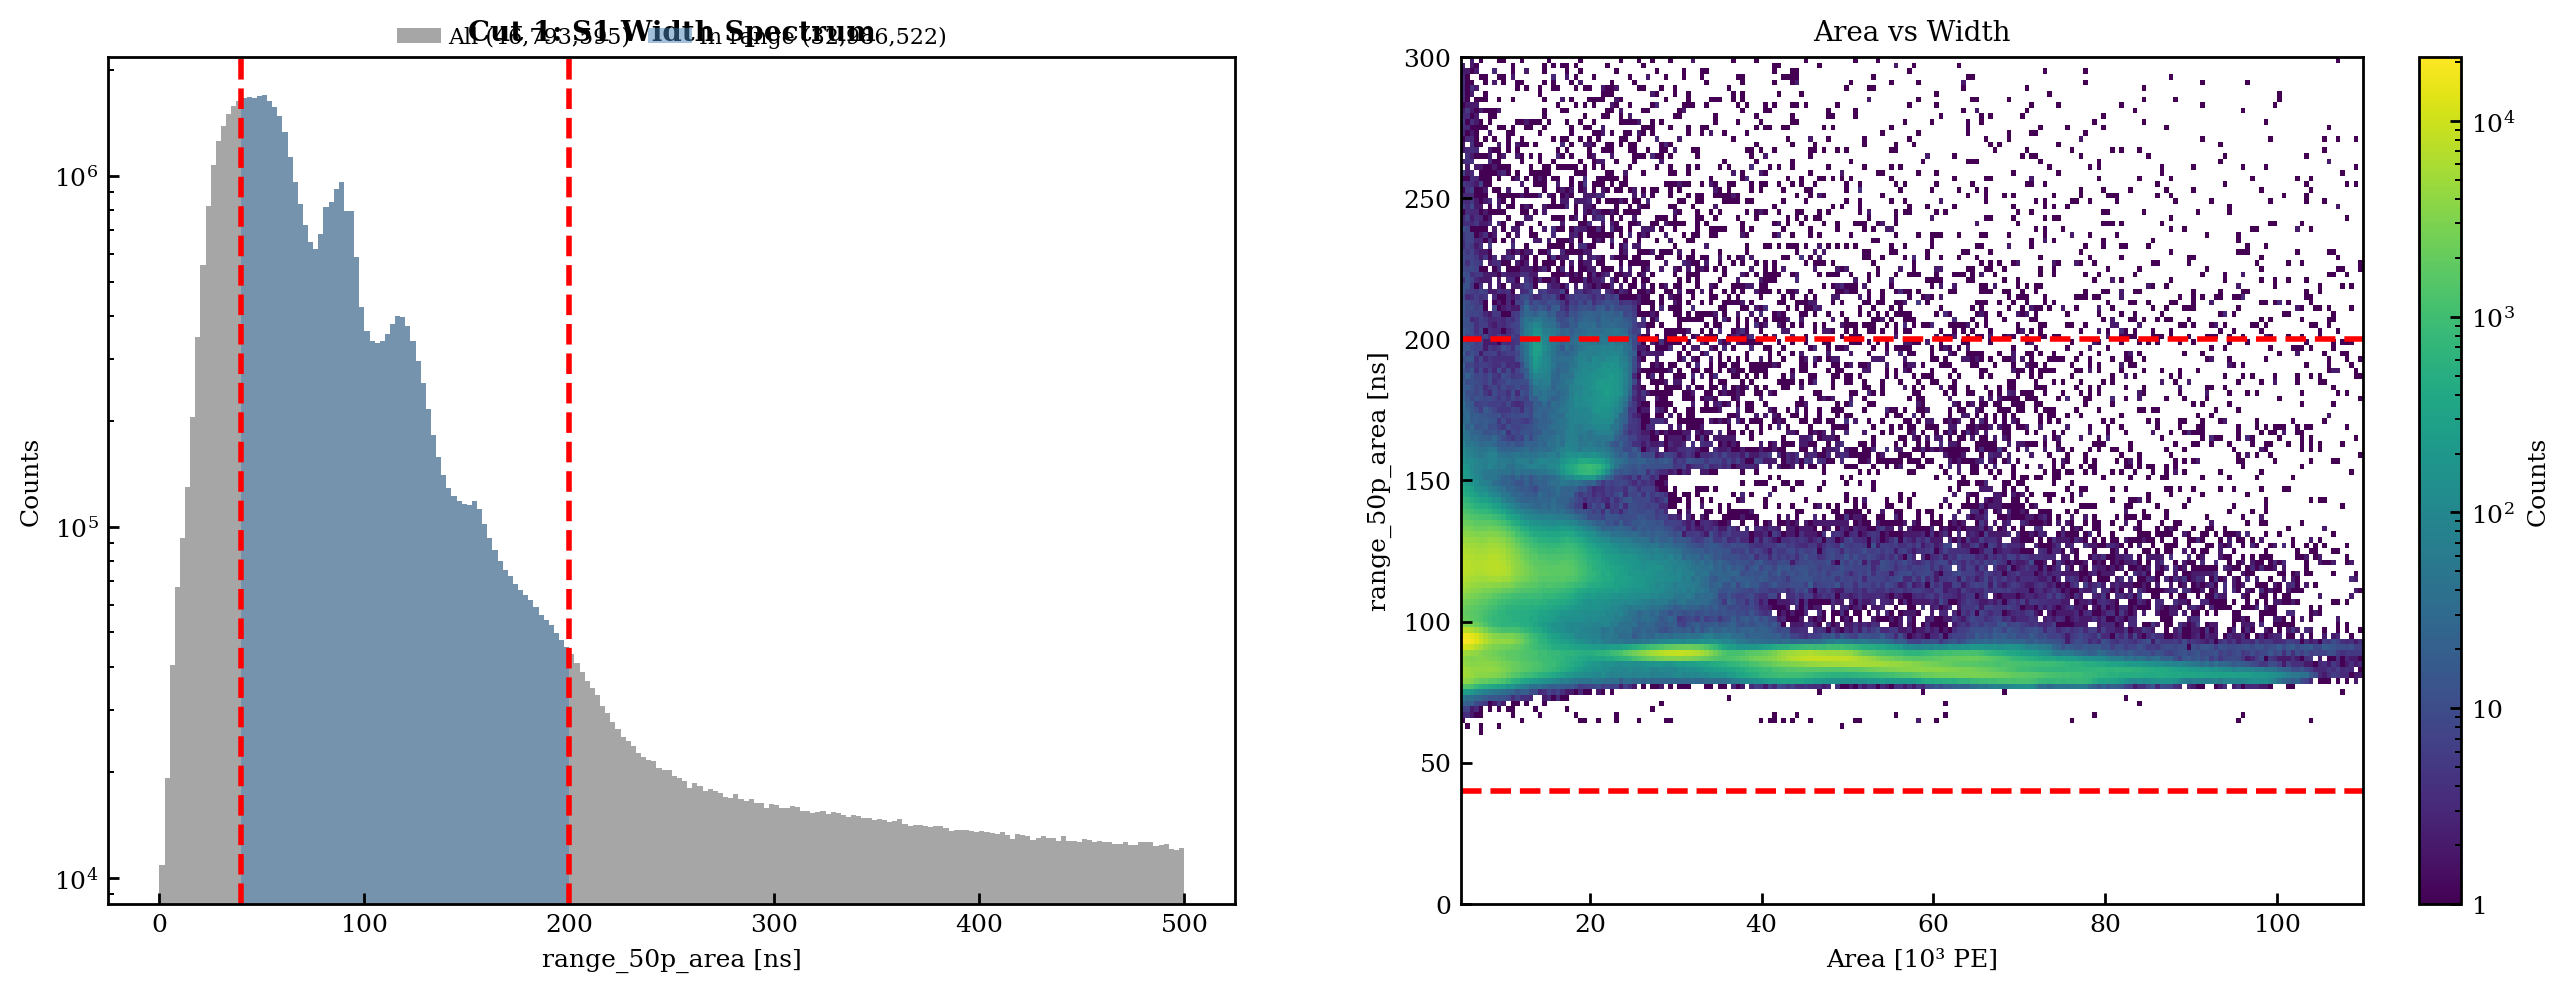

Cut 1 (Width [40, 200] ns): 32,986,522 / 46,793,595 pass (70.5%)


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CUT 1: Width Refinement — range_50p_area
# ═══════════════════════════════════════════════════════════════

WIDTH_MIN = 40   # ns
WIDTH_MAX = 200  # ns

cut_masks = {}
d = df_peaks

m_width = (d['range_50p_area'] > WIDTH_MIN) & (d['range_50p_area'] < WIDTH_MAX)
cut_masks['width'] = m_width

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

ax1.hist(d['range_50p_area'], bins=200, range=[0, 500],
         color='gray', alpha=0.7, label=f'All ({len(d):,})')
ax1.hist(d.loc[m_width, 'range_50p_area'], bins=200, range=[0, 500],
         color='steelblue', alpha=0.5,
         label=f'In range ({m_width.sum():,})')
ax1.axvline(x=WIDTH_MIN, color='red', ls='--', lw=2)
ax1.axvline(x=WIDTH_MAX, color='red', ls='--', lw=2)
ax1.set_xlabel('range_50p_area [ns]')
ax1.set_ylabel('Counts')
ax1.set_yscale('log')
ax1.set_title('Cut 1: S1 Width Spectrum', fontweight='bold', pad=15)ax1.legend(fontsize=8)

h = ax2.hist2d(d['area']/1e3, d['range_50p_area'],
               bins=[200, 150], range=[[5, 110], [0, 300]],
               cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
ax2.axhline(y=WIDTH_MIN, color='red', ls='--', lw=2)
ax2.axhline(y=WIDTH_MAX, color='red', ls='--', lw=2)
ax2.set_xlabel('Area [10³ PE]')
ax2.set_ylabel('range_50p_area [ns]')
ax2.set_title('Area vs Width', pad=15)plt.colorbar(h[3], ax=ax2, label='Counts')

safe_tight(fig)
plt.show()

n_pass = m_width.sum()
print(f'Cut 1 (Width [{WIDTH_MIN}, {WIDTH_MAX}] ns): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')

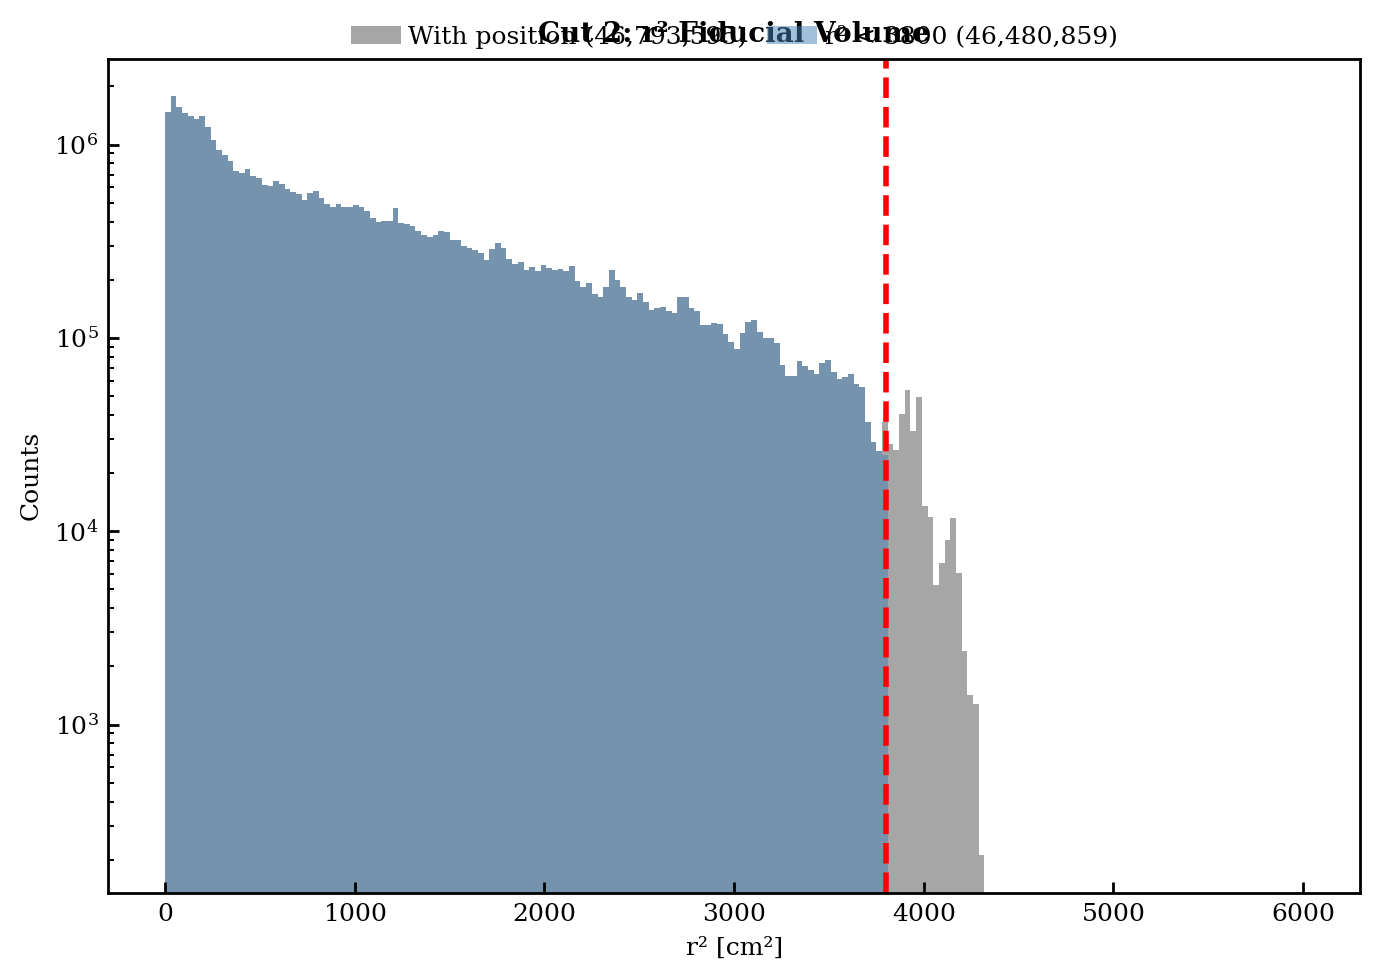

Cut 2 (r² FV < 3800 cm²): 46,480,859 / 46,793,595 pass (99.3%)


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CUT 2: r² Fiducial Volume — TPC wall rejection
# ═══════════════════════════════════════════════════════════════

R2_MAX = 3800.0  # cm²

d = df_peaks

if 'r2' in d.columns:
    has_pos = d['r2'].notna()
    m_r2 = (d['r2'] < R2_MAX).fillna(True)
    cut_masks['r2_fv'] = m_r2

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(d.loc[has_pos, 'r2'], bins=200, range=[0, 6000],
            color='gray', alpha=0.7, label=f'With position ({has_pos.sum():,})')
    ax.hist(d.loc[has_pos & m_r2, 'r2'], bins=200, range=[0, 6000],
            color='steelblue', alpha=0.5,
            label=f'r² < {R2_MAX:.0f} ({(has_pos & m_r2).sum():,})')
    ax.axvline(x=R2_MAX, color='red', ls='--', lw=2)
    ax.set_xlabel('r² [cm²]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('Cut 2: r² Fiducial Volume', fontweight='bold', pad=15)    ax.legend(fontsize=9)
    safe_tight(fig)
    plt.show()

    n_pass = m_r2.sum()
    print(f'Cut 2 (r² FV < {R2_MAX:.0f} cm²): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')
else:
    print('Cut 2 (r² FV): SKIPPED — no r² column available')
    cut_masks['r2_fv'] = pd.Series(True, index=d.index)

In [ ]:
# ═══════════════════════════════════════════════════════════════
# APPLY CUTS — combine masks → df_cut  (NO AFT cut yet)
# ═══════════════════════════════════════════════════════════════

d = df_peaks
mask_combined = pd.Series(True, index=d.index)
for name, m in cut_masks.items():
    if m is not None:
        mask_combined &= m

df_cut = d[mask_combined].copy().reset_index(drop=True)

print()
print('=' * 70)
print('  PRE-CORRECTION CUT FLOW  (AFT cut deferred to after corrections)')
print('=' * 70)

n_before = len(d)
cum_mask = pd.Series(True, index=d.index)

cut_order = [
    ('width',  '1. Width [40, 200] ns'),
    ('r2_fv',  '2. r² FV < 3800 cm²'),
]

for key, label in cut_order:
    m = cut_masks.get(key)
    if m is not None:
        cum_mask &= m
    n_rem = cum_mask.sum()
    print(f'  {label:35s}  {n_rem:>10,} passing  ({100*n_rem/n_before:5.1f}%)')

print('-' * 70)
print(f'  {"Before cuts:":35s}  {n_before:>10,}')
print(f'  {"After cuts:":35s}  {len(df_cut):>10,}')
print(f'  {"Efficiency:":35s}  {100*len(df_cut)/n_before:>9.1f}%')
print('=' * 70)
print(f'\ndf_cut has {len(df_cut):,} events — full AFT range preserved for corrections.')


  PRE-CORRECTION CUT FLOW  (AFT cut deferred to after corrections)
  1. Width [40, 200] ns                32,986,522 passing  ( 70.5%)
  2. r² FV < 3800 cm²                  32,780,402 passing  ( 70.1%)
----------------------------------------------------------------------
  Before cuts:                         46,793,595
  After cuts:                          32,780,402
  Efficiency:                               70.1%

df_cut has 32,780,402 events — full AFT range preserved for corrections.


---
## Correction Pipeline

**Correction order** (each step removes a source of position-dependent light collection variation):

1. **Area vs AFT** — fit Rn band centerline with `exp_bump_model`, correct area → `area_aft_corrected`
2. **AFT vs r²** — fit r²(AFT) with polynomial (Rn-band only), correct r² → `r2_aft_corrected`
3. **r² vs Area** — band selection + degree-10 polynomial fit in r2_aft_corrected vs area_aft_corrected space, correct area → `area_2_corrected`

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION FUNCTIONS
# ═══════════════════════════════════════════════════════════════

def exp_bump_model(x, a, b, c, d, e):
    """
    Florian's empirical model for the alpha band: area vs AFT.
    x = AFT (area_fraction_top)
    Returns the expected area for a given AFT value.
    """
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

def linear_func(x, a, b):
    """Linear function: a*x + b."""
    return a * x + b

def polynomial(x, *coeffs):
    """Polynomial: coeffs[0] + coeffs[1]*x + coeffs[2]*x² + ..."""
    return sum(c * x**i for i, c in enumerate(coeffs))

print('Correction functions defined.')
print('  exp_bump_model(x, a,b,c,d,e) — Area vs AFT  (Correction 1)')
print('  polynomial(x, *coeffs)       — r² vs AFT    (Correction 2)')
print('  polynomial(x, *coeffs)       — r² vs Area   (Correction 3)')
print('  linear_func(x, a, b)         — linear band boundaries')

Correction functions defined.
  exp_bump_model(x, a,b,c,d,e) — Area vs AFT  (Correction 1)
  polynomial(x, *coeffs)       — r² vs AFT    (Correction 2)
  polynomial(x, *coeffs)       — r² vs Area   (Correction 3)
  linear_func(x, a, b)         — linear band boundaries


### Correction 1: Area vs AFT

Fit the Rn-222/220 band centerline using `exp_bump_model`, then normalize all areas to AFT = 0.30.
The fit uses AFT ∈ [0.12, 0.55] to avoid edge effects, but the correction is applied to the full dataset.

Events in fit AFT range [0.12, 0.55]: 11,711,279
Events in Rn band (manual boundaries): 92,510
Initial fit done.  a=104112  b=-0.0227  c=-0.0987  d=-0.0847  e=62248

Initial Rn band in corrected space: μ = 68357 PE, σ = 2655 PE
Vertical band (±1.0σ): [65702, 71011] PE
Events in Rn band (vertical ±1.0σ): 58,810
AFT bins with Rn data (refined): 50

=== Rn-222/220 BAND FIT (REFINED) ===
  a = 4.550170e+05 ± 1.609192e+06
  b = -7.835308e-03 ± 1.000623e-02
  c = -7.897860e-02 ± 2.122340e-02
  d = -4.141695e-01 ± 1.479187e+00
  e = 6.260876e+04 ± 8.346499e+01


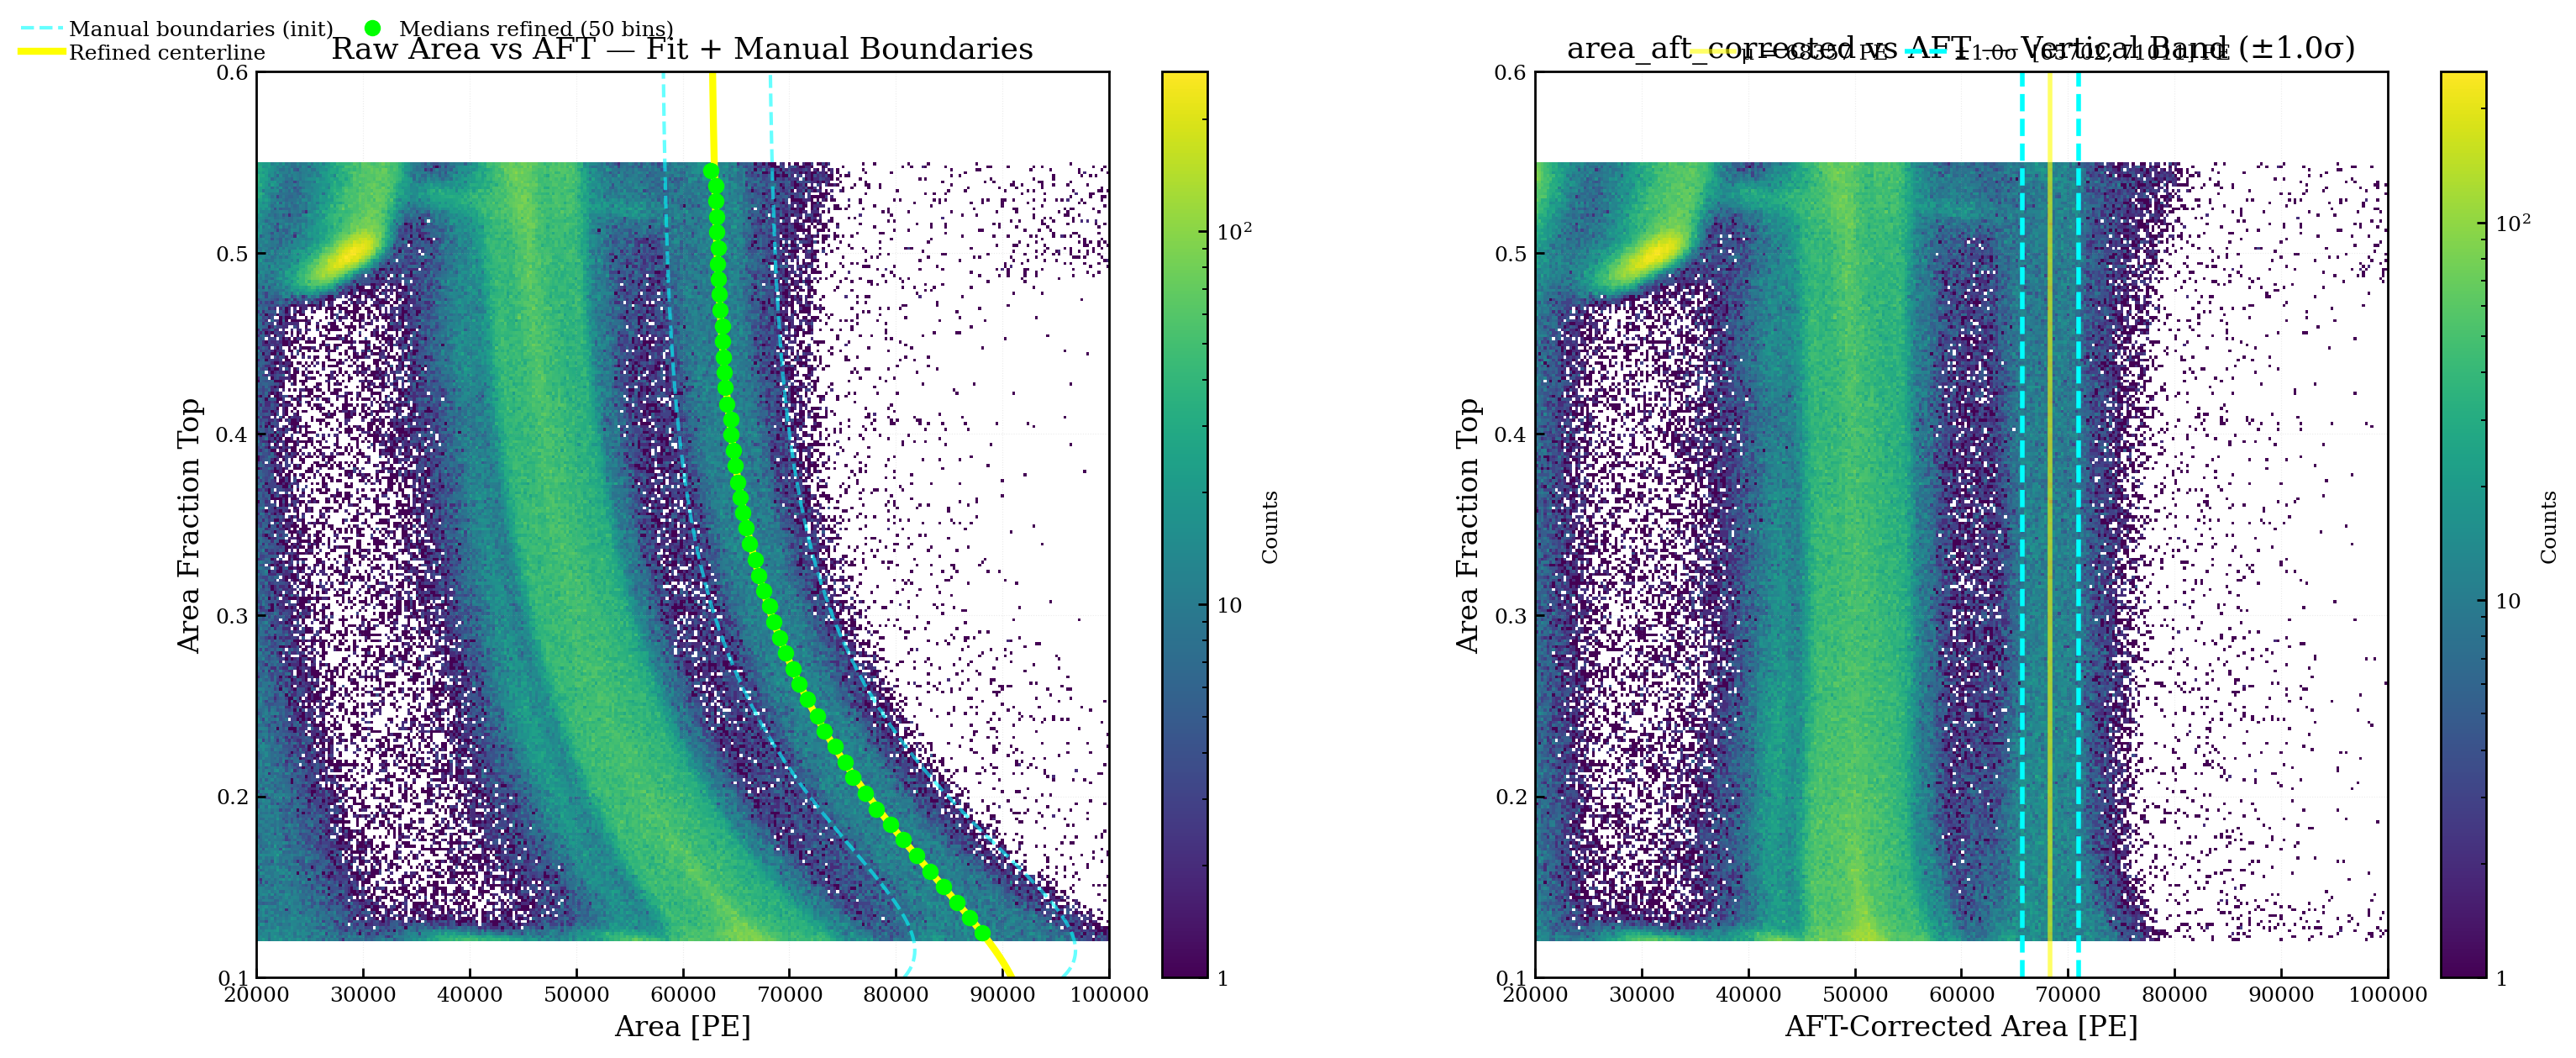


Rn band (vertical, ±1.0σ): [65702, 71011] PE
Reference AFT: 0.3


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 1a: Rn-222 Band Fitting in Area vs AFT
# ═══════════════════════════════════════════════════════════════
# Two-step process:
#   1. Initial fit using manual exp_bump_model boundaries
#   2. Refine: select Rn band as VERTICAL cut (±1σ) in area_aft_corrected,
#      re-fit exp_bump_model to the improved selection.
# Correction is applied to the FULL d_cor afterwards (in 1b).

d_cor = df_cut.copy()

# ── Fit region: restrict AFT to avoid edges ──
aft_fit_min, aft_fit_max = 0.12, 0.55
mask_fit_region = (
    (d_cor['area_fraction_top'] >= aft_fit_min) &
    (d_cor['area_fraction_top'] <= aft_fit_max)
)
d_fit = d_cor.loc[mask_fit_region].copy()
print(f'Events in fit AFT range [{aft_fit_min}, {aft_fit_max}]: {len(d_fit):,}')

# ═══════════════════════════════════════════════════════════════
# STEP 1: Initial fit with manual exp_bump_model boundaries
# ═══════════════════════════════════════════════════════════════

rn_upper_pars = [8.86e+04, -0.0600, -0.0900, -0.0600, 68000]
rn_lower_pars = [7.30e+04, -0.0600, -0.0900, -0.0600, 58000]

d_fit['in_rn_band_manual'] = (
    (d_fit['area'] < exp_bump_model(d_fit['area_fraction_top'], *rn_upper_pars)) &
    (d_fit['area'] > exp_bump_model(d_fit['area_fraction_top'], *rn_lower_pars))
)
print(f'Events in Rn band (manual boundaries): {d_fit["in_rn_band_manual"].sum():,}')

# ── Bin & fit (initial pass) ──
n_aft_bins = 50
aft_edges = np.linspace(aft_fit_min, aft_fit_max, n_aft_bins + 1)
d_fit['aft_bin'] = pd.cut(d_fit['area_fraction_top'], bins=aft_edges)

medians_rn_init = (
    d_fit[d_fit['in_rn_band_manual']]
    .groupby('aft_bin', observed=True)['area']
    .median()
)
aft_c_init = medians_rn_init.index.map(lambda iv: iv.mid).astype(float).values
m_vals_init = medians_rn_init.values
good_init = ~np.isnan(m_vals_init)
aft_c_init, m_vals_init = aft_c_init[good_init], m_vals_init[good_init]

p0_rn = [3.70e4, -8.97e-2, -0.1, -0.05, 35e3]
p_opt_init, _ = curve_fit(
    exp_bump_model, aft_c_init, m_vals_init,
    p0=p0_rn,
    bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]),
    maxfev=10000
)
print(f'Initial fit done.  a={p_opt_init[0]:.0f}  b={p_opt_init[1]:.4f}  '
      f'c={p_opt_init[2]:.4f}  d={p_opt_init[3]:.4f}  e={p_opt_init[4]:.0f}')

# ═══════════════════════════════════════════════════════════════
# STEP 2: Refine — vertical band in area_aft_corrected (±1σ)
# ═══════════════════════════════════════════════════════════════

aft_ref = 0.30
N_SIGMA = 1.0

# Compute initial area_aft_corrected for band definition
area_ref_init = exp_bump_model(aft_ref, *p_opt_init)
d_fit['area_aft_corrected_temp'] = (
    d_fit['area'] * area_ref_init
    / exp_bump_model(d_fit['area_fraction_top'], *p_opt_init)
)

# Find μ, σ of corrected area for initial Rn-band events
rn_init = d_fit[d_fit['in_rn_band_manual']]
mu_rn = rn_init['area_aft_corrected_temp'].mean()
sig_rn = rn_init['area_aft_corrected_temp'].std()

print(f'\nInitial Rn band in corrected space: μ = {mu_rn:.0f} PE, σ = {sig_rn:.0f} PE')
print(f'Vertical band (±{N_SIGMA}σ): [{mu_rn - N_SIGMA*sig_rn:.0f}, {mu_rn + N_SIGMA*sig_rn:.0f}] PE')

# Redefine Rn band as VERTICAL cut in area_aft_corrected
d_fit['in_rn_band'] = (
    abs(d_fit['area_aft_corrected_temp'] - mu_rn) < N_SIGMA * sig_rn
)
print(f'Events in Rn band (vertical ±{N_SIGMA}σ): {d_fit["in_rn_band"].sum():,}')

# ── Re-bin & re-fit with improved selection ──
medians_rn = (
    d_fit[d_fit['in_rn_band']]
    .groupby('aft_bin', observed=True)['area']
    .median()
)
aft_centers = medians_rn.index.map(lambda iv: iv.mid).astype(float).values
median_values = medians_rn.values
good_rn = ~np.isnan(median_values)
aft_c_rn, m_vals_rn = aft_centers[good_rn], median_values[good_rn]

print(f'AFT bins with Rn data (refined): {len(aft_c_rn)}')

# Fit exp_bump_model to refined medians
p_opt_rn, p_cov_rn = curve_fit(
    exp_bump_model, aft_c_rn, m_vals_rn,
    p0=p_opt_init,
    bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]),
    maxfev=10000
)
p_err_rn = np.sqrt(np.diag(p_cov_rn))

print(f'\n=== Rn-222/220 BAND FIT (REFINED) ===')
for name, val, err in zip(['a','b','c','d','e'], p_opt_rn, p_err_rn):
    print(f'  {name} = {val:.6e} ± {err:.6e}')

# ── Store vertical band bounds for downstream use ──
rn_band_lo = mu_rn - N_SIGMA * sig_rn
rn_band_hi = mu_rn + N_SIGMA * sig_rn

# ═══════════════════════════════════════════════════════════════
# PLOT: 2-panel — (left) Raw Area vs AFT + fit  (right) area_aft_corrected vs AFT + vertical band
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
aft_fine = np.linspace(0.10, 0.60, 500)

# Left: Raw Area vs AFT with initial & refined fits
ax = axes[0]
h = ax.hist2d(
    d_fit['area'], d_fit['area_fraction_top'],
    bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')
ax.plot(exp_bump_model(aft_fine, *rn_upper_pars), aft_fine,
        '--', color='cyan', lw=1.5, alpha=0.6, label='Manual boundaries (init)')
ax.plot(exp_bump_model(aft_fine, *rn_lower_pars), aft_fine,
        '--', color='cyan', lw=1.5, alpha=0.6)
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=3, label='Refined centerline')
ax.plot(m_vals_rn, aft_c_rn, 'o', color='lime', markersize=6,
        label=f'Medians refined ({len(aft_c_rn)} bins)', zorder=5)
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Raw Area vs AFT — Fit + Manual Boundaries', pad=15, fontsize=13)
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.2)

# Right: AFT-corrected Area vs AFT with vertical band boundaries
ax = axes[1]
h = ax.hist2d(
    d_fit['area_aft_corrected_temp'], d_fit['area_fraction_top'],
    bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=mu_rn, color='yellow', lw=2, alpha=0.6, label=f'μ = {mu_rn:.0f} PE')
ax.axvline(x=rn_band_lo, color='cyan', ls='--', lw=2,
           label=f'±{N_SIGMA}σ  [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE')
ax.axvline(x=rn_band_hi, color='cyan', ls='--', lw=2)
ax.set_xlabel('AFT-Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title(f'area_aft_corrected vs AFT — Vertical Band (±{N_SIGMA}σ)', pad=15, fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

print(f'\nRn band (vertical, ±{N_SIGMA}σ): [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE')
print(f'Reference AFT: {aft_ref}')

Reference AFT: 0.3
Reference area (Rn centerline at AFT=0.3): 68306 PE
AFT correction applied to 32,780,402 events (full dataset)


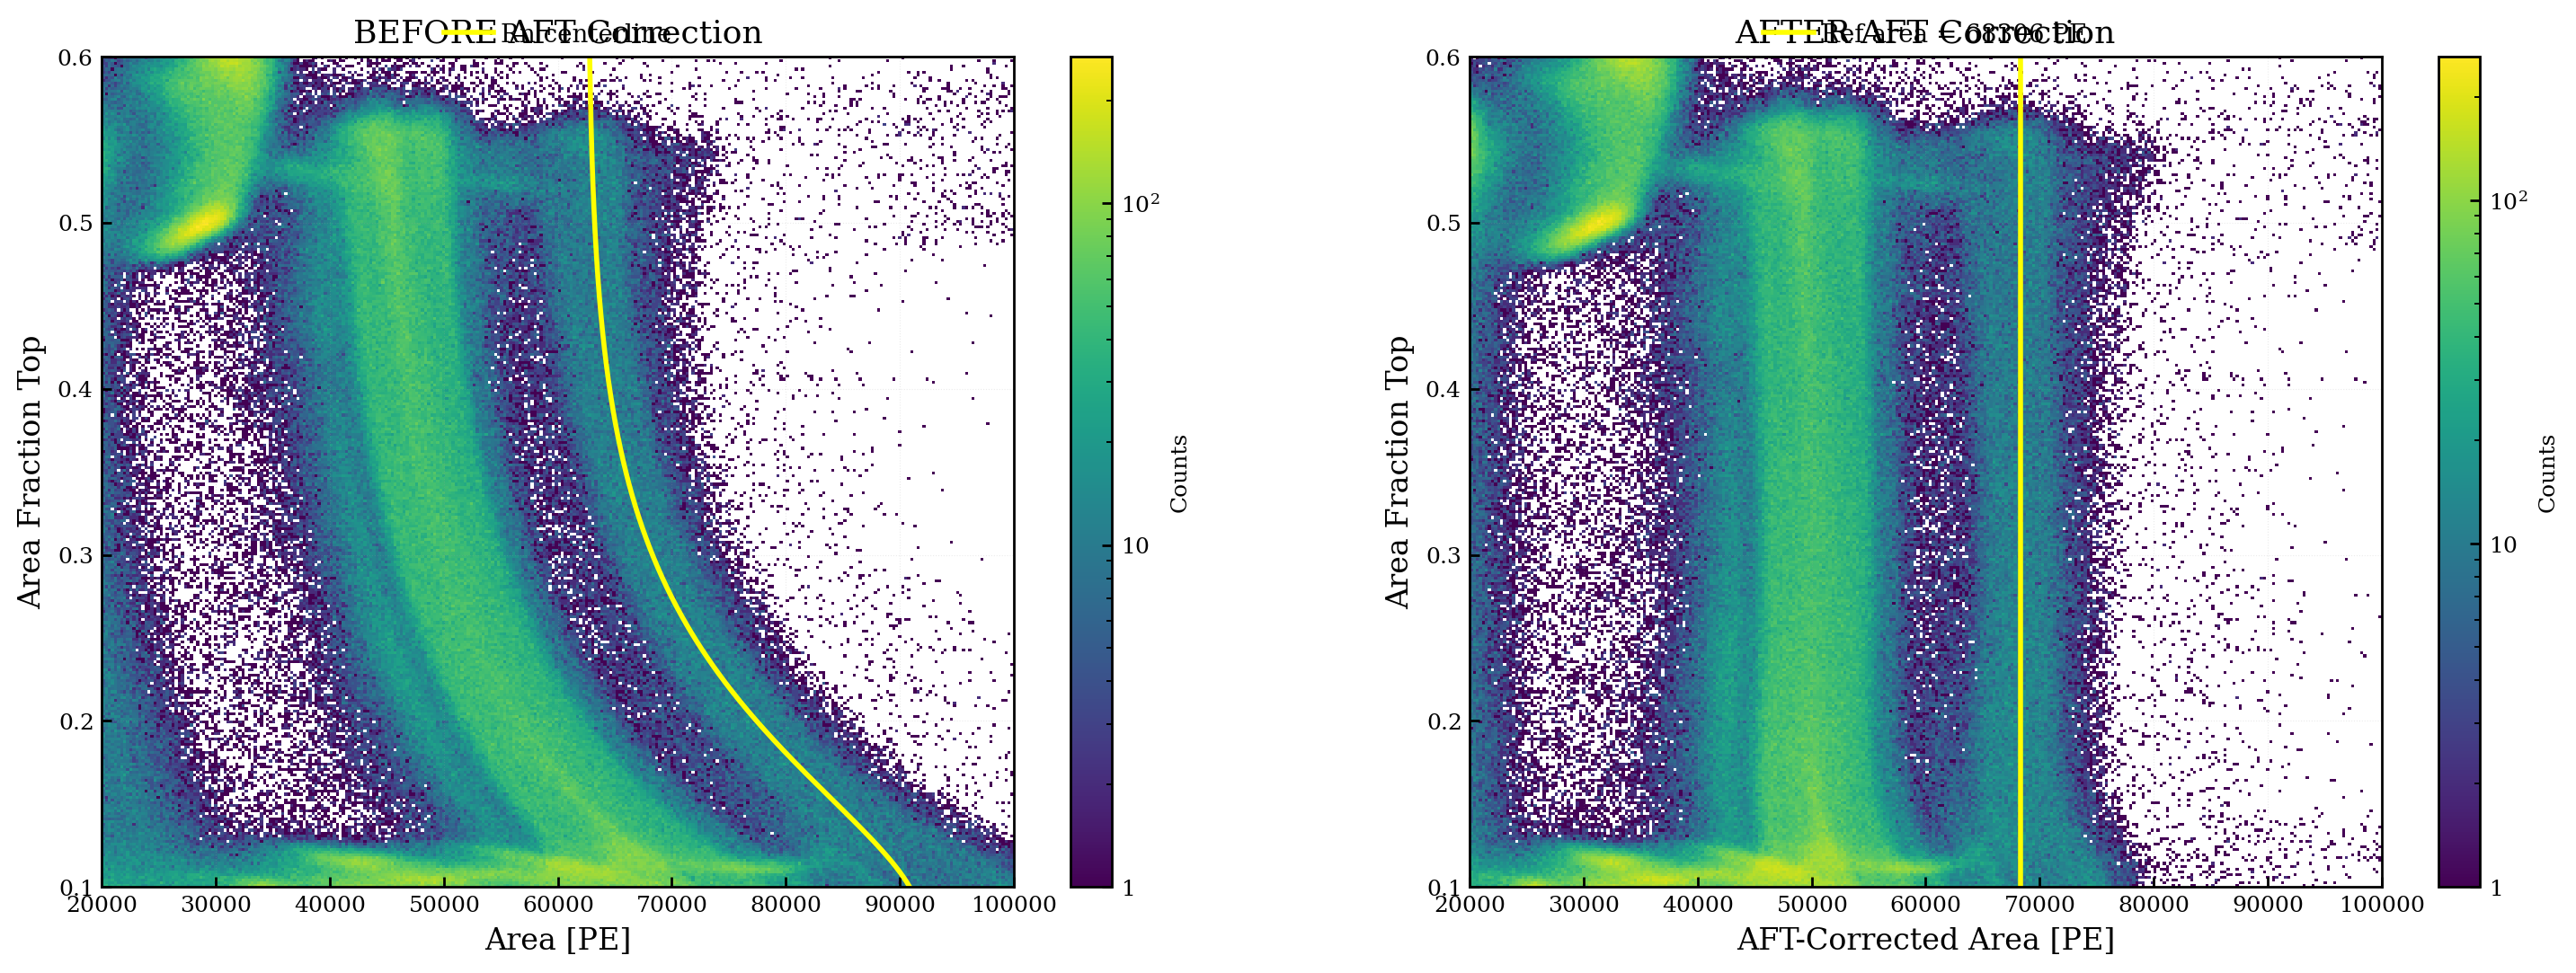

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 1b: Apply AFT Correction to FULL dataset
# ═══════════════════════════════════════════════════════════════
# Uses the REFINED centerline from Correction 1a.
# Applied to ALL of d_cor (not just the fit region).

area_ref = exp_bump_model(aft_ref, *p_opt_rn)

print(f'Reference AFT: {aft_ref}')
print(f'Reference area (Rn centerline at AFT={aft_ref}): {area_ref:.0f} PE')

# Apply correction to full d_cor
d_cor['area_aft_corrected'] = (
    d_cor['area']
    * area_ref
    / exp_bump_model(d_cor['area_fraction_top'], *p_opt_rn)
)

print(f'AFT correction applied to {len(d_cor):,} events (full dataset)')

# ── Before/After plot (shown in fit region for visibility) ──
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

mask_plot = (
    (d_cor['area_fraction_top'] >= 0.10) & (d_cor['area_fraction_top'] <= 0.60)
)
d_plot = d_cor.loc[mask_plot]

ax = axes[0]
h = ax.hist2d(d_plot['area'], d_plot['area_fraction_top'],
              bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=2, label='Rn centerline')
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('BEFORE AFT Correction', pad=15, fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

ax = axes[1]
h = ax.hist2d(d_plot['area_aft_corrected'], d_plot['area_fraction_top'],
              bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=area_ref, color='yellow', lw=2, ls='-',
           label=f'Ref area = {area_ref:.0f} PE')
ax.set_xlabel('AFT-Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('AFTER AFT Correction', pad=15, fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

### Correction 2: AFT vs r²

Quantify the correlation between AFT (depth proxy) and r² (radial position).
Use **Rn-222 band events** (tagged `in_rn_band` in Correction 1) and fit in **AFT (x) vs r² (y)** space.
Fit `r²(AFT) =` degree-N polynomial, then correct **r²** to the reference AFT → `r2_aft_corrected`.

Fit range: AFT ∈ [0.11, 0.55], r² ∈ [0, 700] cm².

Correction 2 Rn-band: area_aft_corrected ∈ [40000, 45000] PE
Events in Correction 2 Rn-band: 107,882


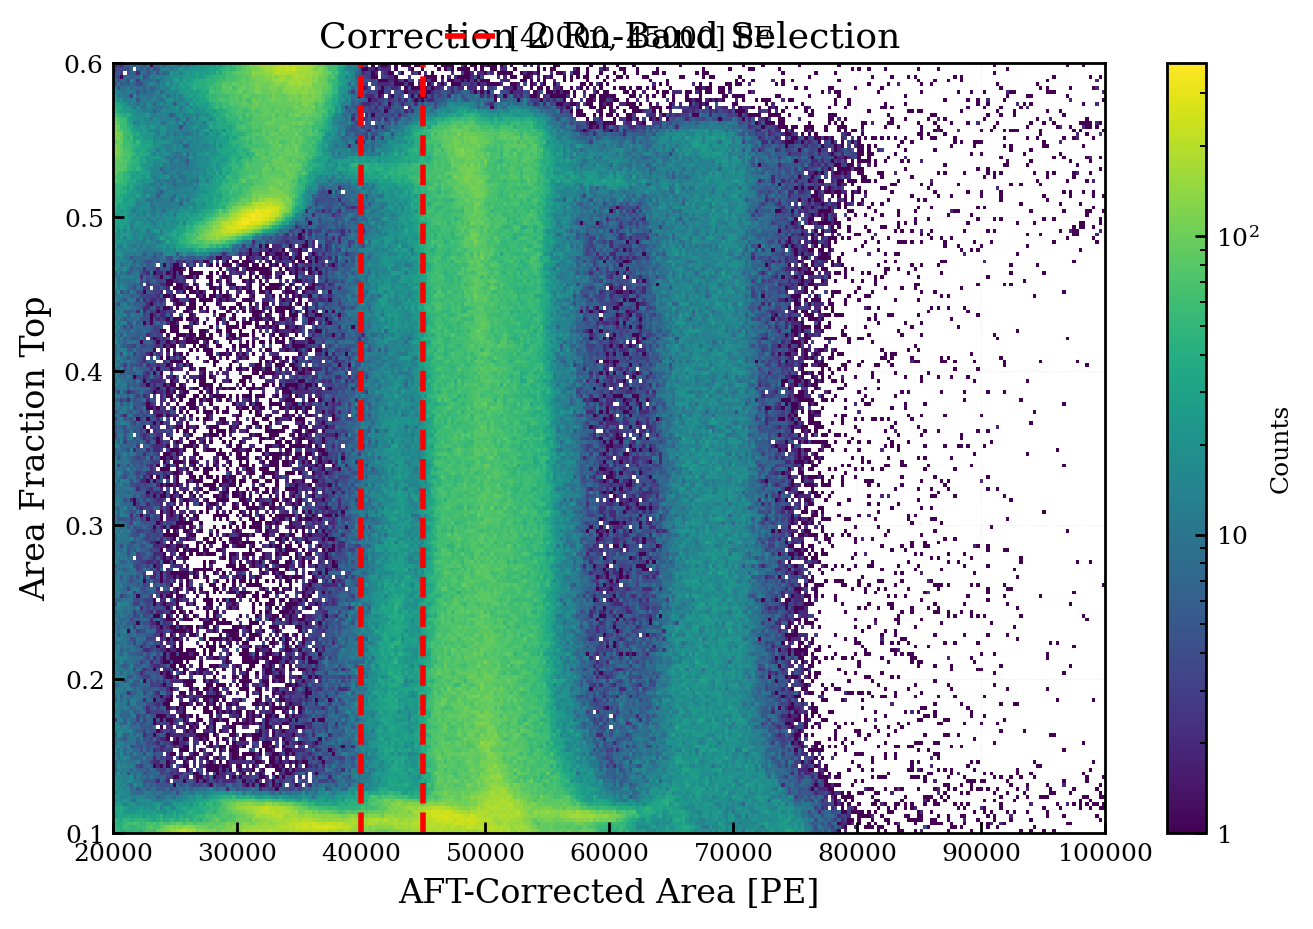

In [ ]:
# ── Rn-band re-selection for Correction 2 ──
# Use a VERTICAL band in area_aft_corrected (different from Correction 1).
CORR2_AREA_LO = 40000
CORR2_AREA_HI = 45000

mask_corr2_rn = (
    (d_cor['area_aft_corrected'] >= CORR2_AREA_LO) &
    (d_cor['area_aft_corrected'] <= CORR2_AREA_HI)
)
print(f'Correction 2 Rn-band: area_aft_corrected ∈ [{CORR2_AREA_LO}, {CORR2_AREA_HI}] PE')
print(f'Events in Correction 2 Rn-band: {mask_corr2_rn.sum():,}')

# Quick visual check: where is this band?
fig, ax = plt.subplots(figsize=(8, 5))
h = ax.hist2d(d_cor['area_aft_corrected'], d_cor['area_fraction_top'],
              bins=[300, 200], range=[[20e3, 100e3], [0.1, 0.6]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=CORR2_AREA_LO, color='red', ls='--', lw=2, label=f'[{CORR2_AREA_LO}, {CORR2_AREA_HI}] PE')
ax.axvline(x=CORR2_AREA_HI, color='red', ls='--', lw=2)
ax.set_xlabel('AFT-Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Correction 2 Rn-Band Selection', pad=15, fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()


Rn-band events in fit region: 70,423
  AFT range: [0.120, 0.550]
  r² range:  [0.3, 733.8]
AFT bins with ≥20 events: 40
Median r² range: [46.5, 395.8] cm²

Degree-10 polynomial fit: r²(AFT)
  c₀ = 20646.65 ± 2750.75
  c1 = -6.2298e+05 ± 1.0303e+05
  c2 = 8.5653e+06 ± 1.6854e+06
  c3 = -6.9276e+07 ± 1.5869e+07
  c4 = 3.6177e+08 ± 9.5331e+07
  c5 = -1.2688e+09 ± 3.8226e+08
  ... (total 11 coefficients)


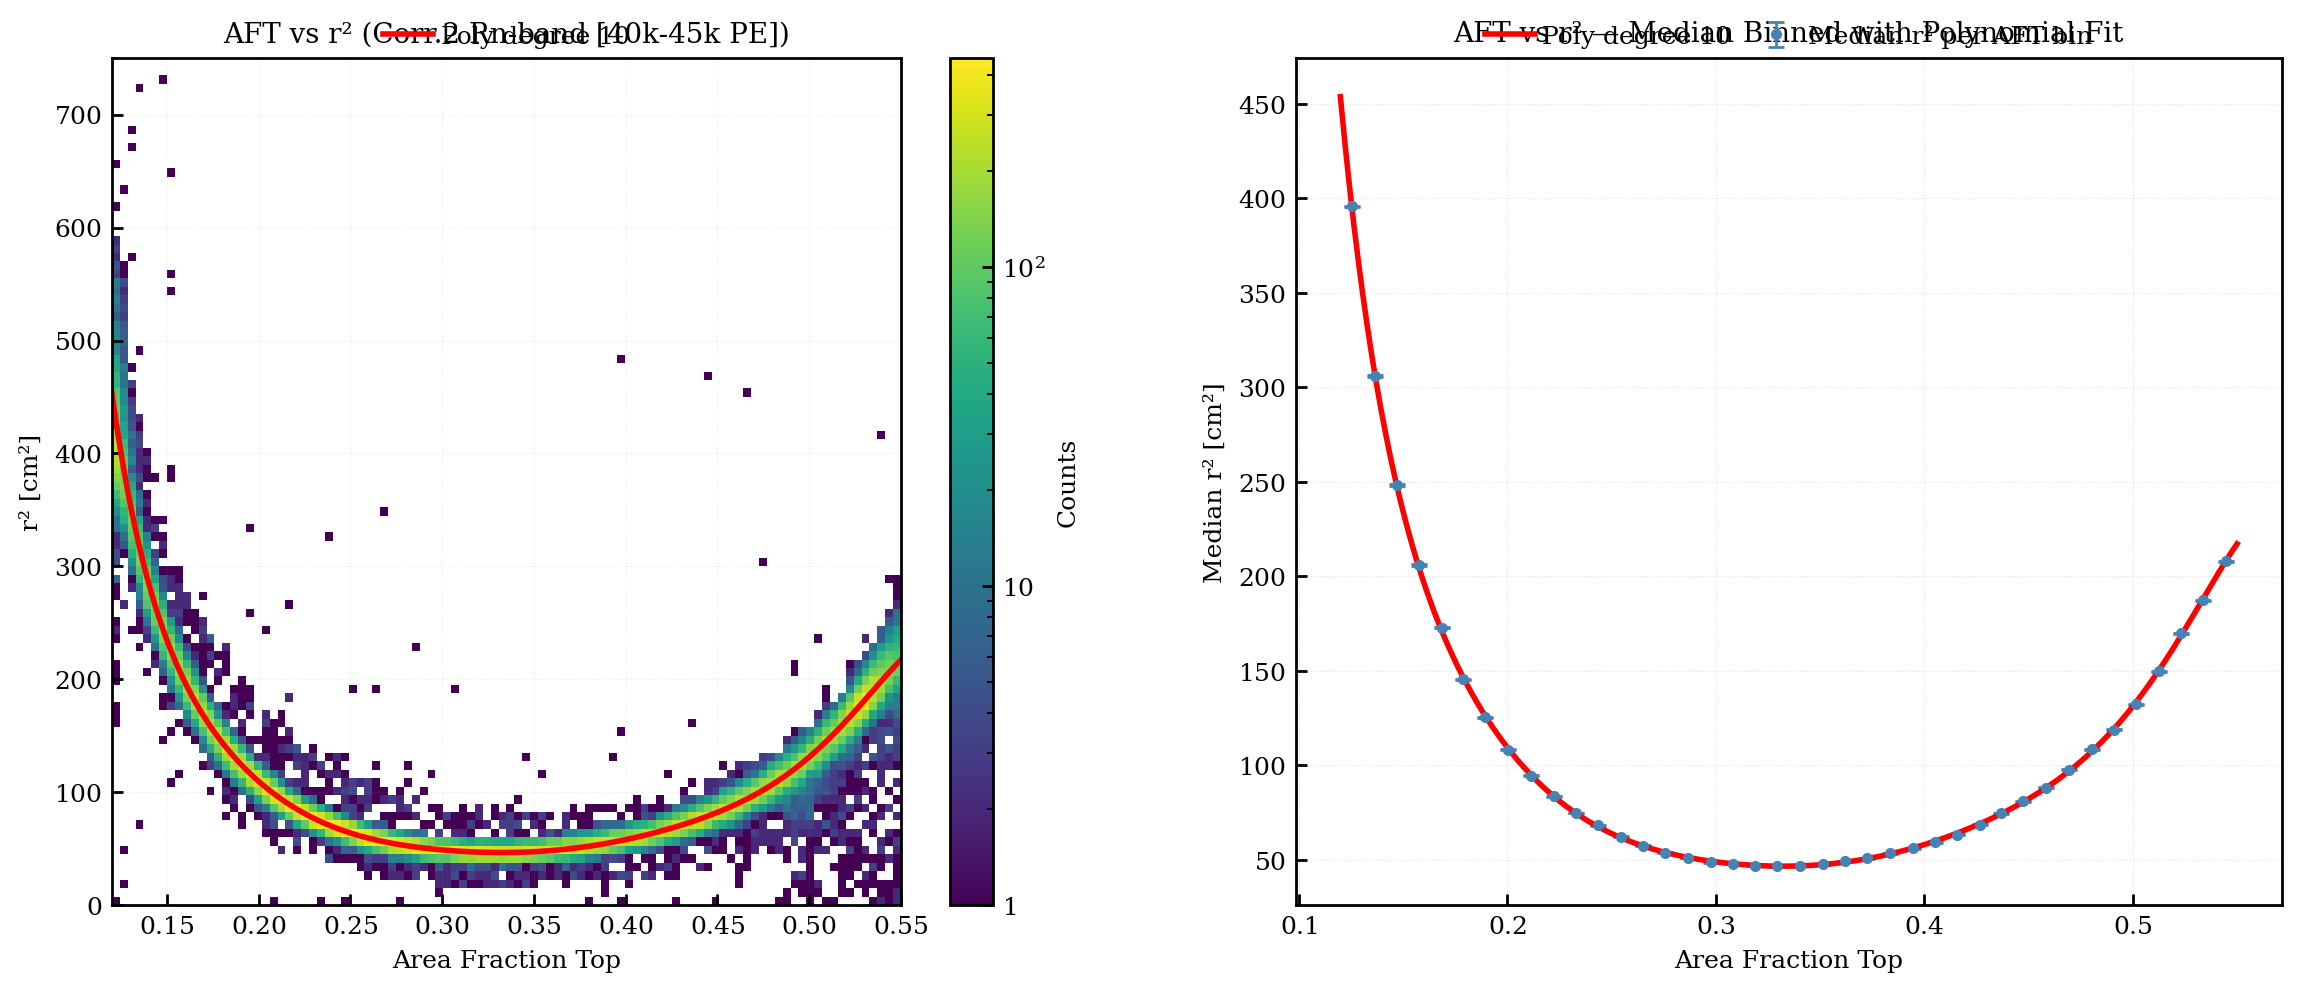


Reference AFT: 0.3
Expected r² at AFT=0.3: 48.9 cm²
Correction 2 factor range: [-119157.3551, 18480.1587]
Correction 2 applied to all 32,780,402 events — new column: r2_aft_corrected


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 2: AFT vs r² — polynomial fit + correction
# ═══════════════════════════════════════════════════════════════
# Plot and fit in AFT (x) vs r² (y) space.
# Use only events in the Correction 2 Rn-band (vertical cut in area_aft_corrected).
# Fit: r²(AFT) = degree-N polynomial, then correct r² using the
# fitted function (just like Correction 1 but for r² instead of area).

aft_min, aft_max = 0.12, 0.55
r2_min_aft, r2_max_aft = 0, 750
POLY_DEG = 10

# ── Select Rn-band events only ──
mask_r2aft = (
    (d_cor['r2'] >= r2_min_aft) & (d_cor['r2'] <= r2_max_aft) &
    (d_cor['area_fraction_top'] >= aft_min) & (d_cor['area_fraction_top'] <= aft_max) &
    (mask_corr2_rn)
)
d_r2aft = d_cor.loc[mask_r2aft].copy()
print(f'Rn-band events in fit region: {len(d_r2aft):,}')
print(f'  AFT range: [{d_r2aft["area_fraction_top"].min():.3f}, {d_r2aft["area_fraction_top"].max():.3f}]')
print(f'  r² range:  [{d_r2aft["r2"].min():.1f}, {d_r2aft["r2"].max():.1f}]')

# ── Bin in AFT (x-axis), get median r² (y-axis) ──
n_aft_bins = 40
aft_edges = np.linspace(aft_min, aft_max, n_aft_bins + 1)
d_r2aft['aft_bin'] = pd.cut(d_r2aft['area_fraction_top'], bins=aft_edges)

medians_r2 = d_r2aft.groupby('aft_bin', observed=True)['r2'].median()
counts_r2  = d_r2aft.groupby('aft_bin', observed=True)['r2'].count()

aft_c = medians_r2.index.map(lambda iv: iv.mid).astype(float).values
r2_medians = medians_r2.values
good_bins = counts_r2.values >= 20

aft_fit_pts = aft_c[good_bins]
r2_fit_pts  = r2_medians[good_bins]
n_fit        = counts_r2.values[good_bins]

print(f'AFT bins with ≥20 events: {len(aft_fit_pts)}')
print(f'Median r² range: [{r2_fit_pts.min():.1f}, {r2_fit_pts.max():.1f}] cm²')

# ── Fit: r²(AFT) = degree-N polynomial ──
p0_poly = [np.median(r2_fit_pts)] + [0.0] * POLY_DEG
popt_r2, pcov_r2 = curve_fit(polynomial, aft_fit_pts, r2_fit_pts, p0=p0_poly, maxfev=50000)
perr_r2 = np.sqrt(np.diag(pcov_r2))

print(f'\nDegree-{POLY_DEG} polynomial fit: r²(AFT)')
print(f'  c₀ = {popt_r2[0]:.2f} ± {perr_r2[0]:.2f}')
for i in range(1, min(6, POLY_DEG + 1)):
    print(f'  c{i} = {popt_r2[i]:.4e} ± {perr_r2[i]:.4e}')
print(f'  ... (total {POLY_DEG + 1} coefficients)')

# ── Plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: 2D histogram — AFT (x) vs r² (y), Rn-band only
ax = axes[0]
h = ax.hist2d(d_r2aft['area_fraction_top'], d_r2aft['r2'],
              bins=[100, 100],
              range=[[aft_min, aft_max], [r2_min_aft, r2_max_aft]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
aft_fine = np.linspace(aft_min, aft_max, 200)
ax.plot(aft_fine, polynomial(aft_fine, *popt_r2), 'r-', lw=2, label=f'Poly degree {POLY_DEG}')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r² [cm²]')
ax.set_title('AFT vs r² (Corr.2 Rn-band [40k-45k PE])', pad=15)ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Right: Median r² vs AFT with fit
ax = axes[1]
ax.errorbar(aft_fit_pts, r2_fit_pts,
            yerr=np.sqrt(np.maximum(r2_fit_pts, 1))/np.sqrt(n_fit),
            fmt='o', capsize=3, color='steelblue', label='Median r² per AFT bin')
ax.plot(aft_fine, polynomial(aft_fine, *popt_r2), 'r-', lw=2, label=f'Poly degree {POLY_DEG}')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Median r² [cm²]')
ax.set_title('AFT vs r² — Median Binned with Polynomial Fit', pad=15)ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

safe_tight(fig)
plt.show()

# ═══════════════════════════════════════════════════════════════
# APPLY CORRECTION 2: correct r² against AFT (ALL events)
# ═══════════════════════════════════════════════════════════════
# Normalize r² to the reference AFT using the fitted polynomial.
# No clipping — the polynomial is well-behaved and the large
# correction factors at AFT edges are physically expected.
#
#   r2_aft_corrected = r² * r2_at_ref / poly(AFT)

r2_at_ref_aft = polynomial(aft_ref, *popt_r2)   # expected r² at reference AFT
print(f'\nReference AFT: {aft_ref}')
print(f'Expected r² at AFT={aft_ref}: {r2_at_ref_aft:.1f} cm²')

cf_r2aft = r2_at_ref_aft / polynomial(d_cor['area_fraction_top'].values, *popt_r2)

d_cor['r2_aft_corrected'] = d_cor['r2'] * cf_r2aft
d_cor['corr2_factor'] = cf_r2aft

print(f'Correction 2 factor range: [{cf_r2aft.min():.4f}, {cf_r2aft.max():.4f}]')
print(f'Correction 2 applied to all {len(d_cor):,} events — new column: r2_aft_corrected')

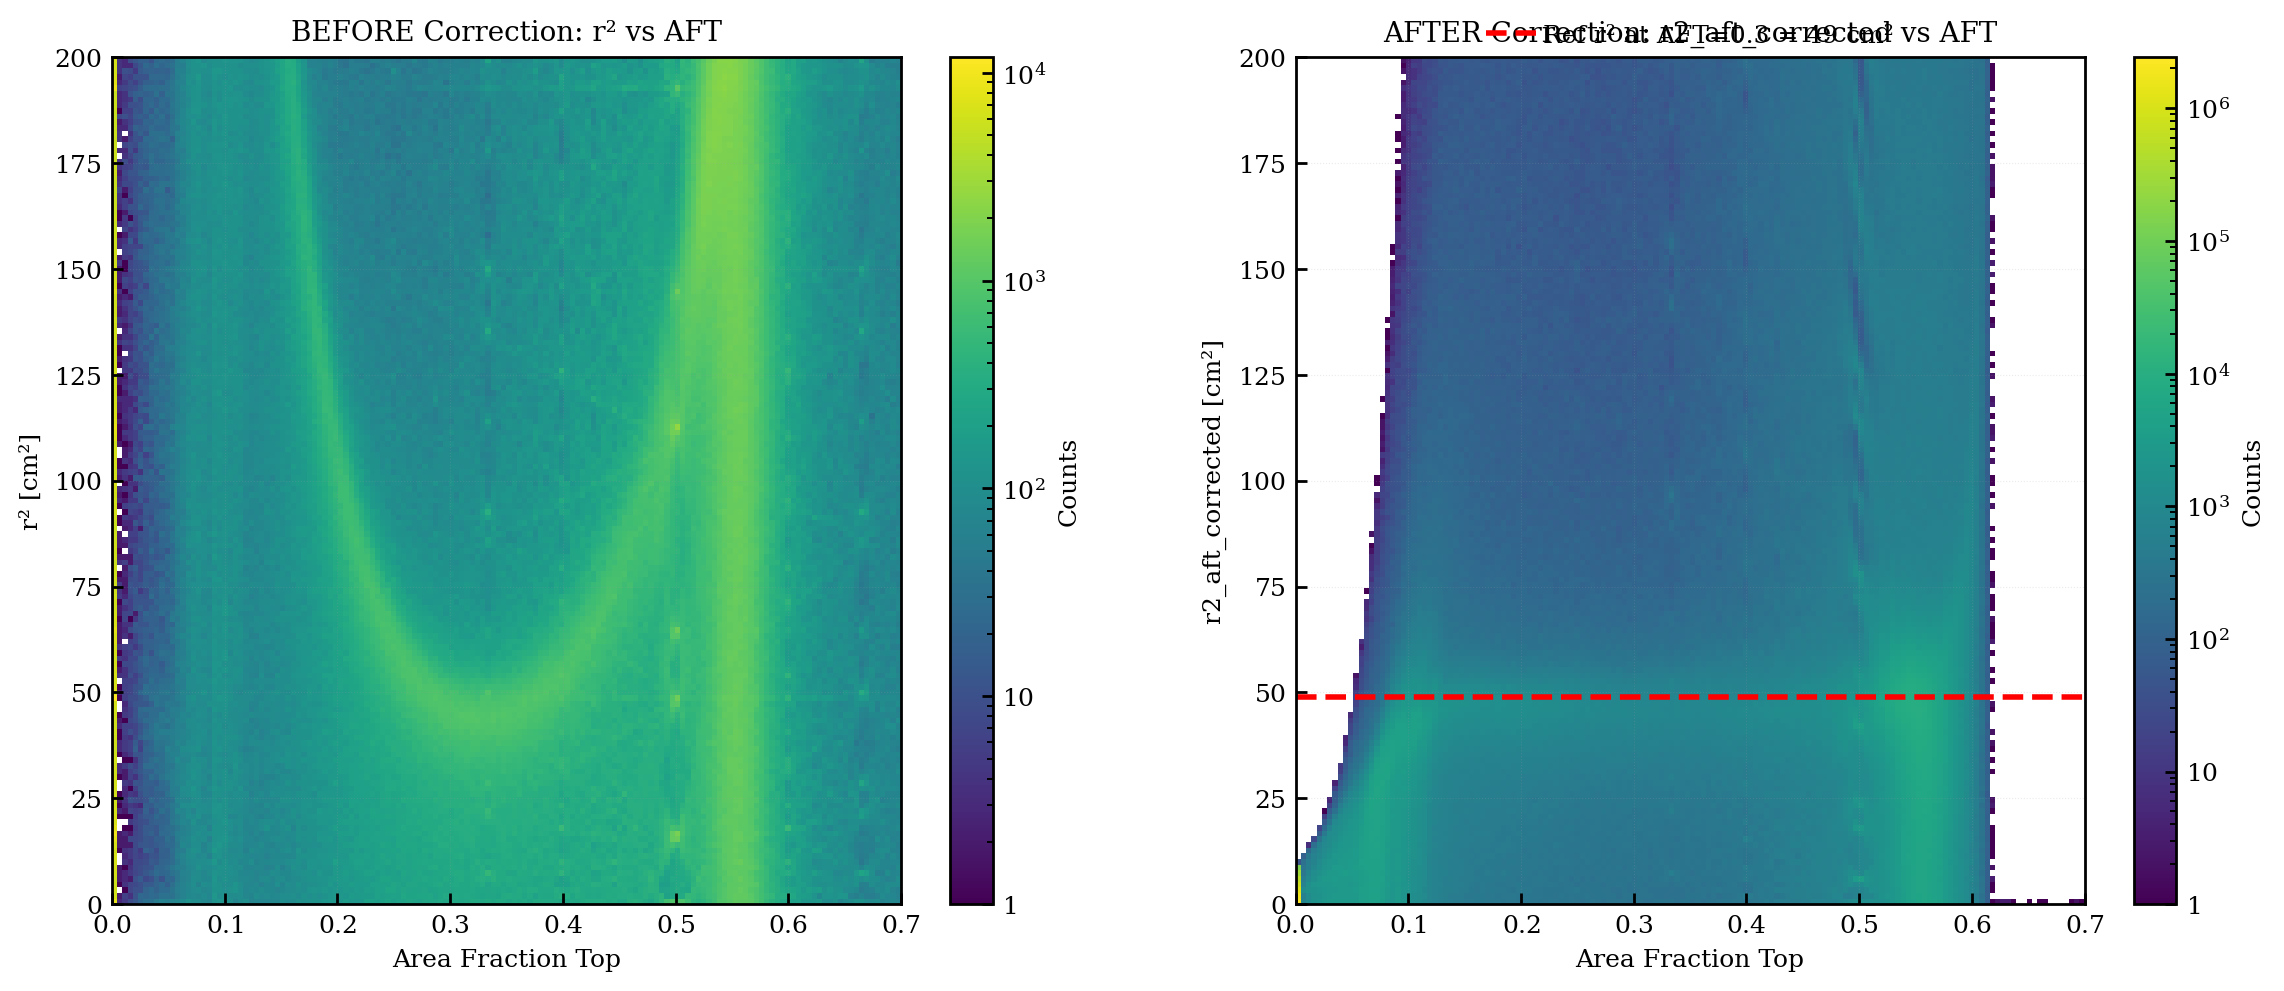

Correction 2 diagnostic:
  Raw r² mean: 933.2 cm²
  r2_aft_corrected mean: 169.8 cm²
  Reference r² at AFT=0.3: 49 cm²


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 2 DIAGNOSTIC: r2_aft_corrected vs AFT
# ═══════════════════════════════════════════════════════════════
# Verify that the r² correction removes AFT dependence.

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: BEFORE — raw r² vs AFT
ax = axes[0]
h = ax.hist2d(d_cor['area_fraction_top'], d_cor['r2'],
              bins=[150, 150],
              range=[[0, 0.7], [0, 200]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r² [cm²]')
ax.set_title('BEFORE Correction: r² vs AFT', pad=15)ax.grid(True, alpha=0.2)

# Right: AFTER — r2_aft_corrected vs AFT
ax = axes[1]
h = ax.hist2d(d_cor['area_fraction_top'], d_cor['r2_aft_corrected'],
              bins=[150, 150],
              range=[[0, 0.7], [0, 200]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axhline(y=r2_at_ref_aft, color='red', ls='--', lw=2,
           label=f'Ref r² at AFT={aft_ref} = {r2_at_ref_aft:.0f} cm²')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r2_aft_corrected [cm²]')
ax.set_title('AFTER Correction: r2_aft_corrected vs AFT', pad=15)ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

print(f'Correction 2 diagnostic:')
print(f'  Raw r² mean: {d_cor["r2"].mean():.1f} cm²')
print(f'  r2_aft_corrected mean: {d_cor["r2_aft_corrected"].mean():.1f} cm²')
print(f'  Reference r² at AFT={aft_ref}: {r2_at_ref_aft:.0f} cm²')

### Correction 3: r² vs Area

Fit `area_aft_corrected` vs `r2_aft_corrected`. Select a band with **linear boundaries**
(area = k·r² + intercept, k = -0.2), fit degree-10 polynomial to the band centerline,
then correct area against r² → `area_2_corrected`.

X-axis: `r2_aft_corrected` (from Correction 2), Y-axis: `area_aft_corrected` (from Correction 1).

Fit range: r2_aft_corrected ∈ [0, 100] cm², area ∈ [0, 1e5] PE.

Events in fit range: 20,968,951
Events in linear band (k=-110): 97,069
r² bins with ≥10 band events & r² < 55: 16
Median area range: 65200 – 71588 PE

Degree-6 polynomial fit: area(r2_aft_corrected)  [r² < 55]
  c₀ = 71829 ± 71 PE
  c1 = -1.5983e+02 ± 3.6993e+01
  c2 = 1.3530e+01 ± 5.9331e+00
  c3 = -1.0402e+00 ± 4.1295e-01
  c4 = 3.8191e-02 ± 1.4000e-02
  c5 = -7.0419e-04 ± 2.2747e-04
  ... (total 7 coefficients)
  Reference area (r2_aft_corrected=0) = 71829 PE
Correction 3 factor range: [0.5000, 1.1019]
  Clipped 9980816 values to [0.5, 2.0]
Correction 3 applied — new column: area_2_corrected


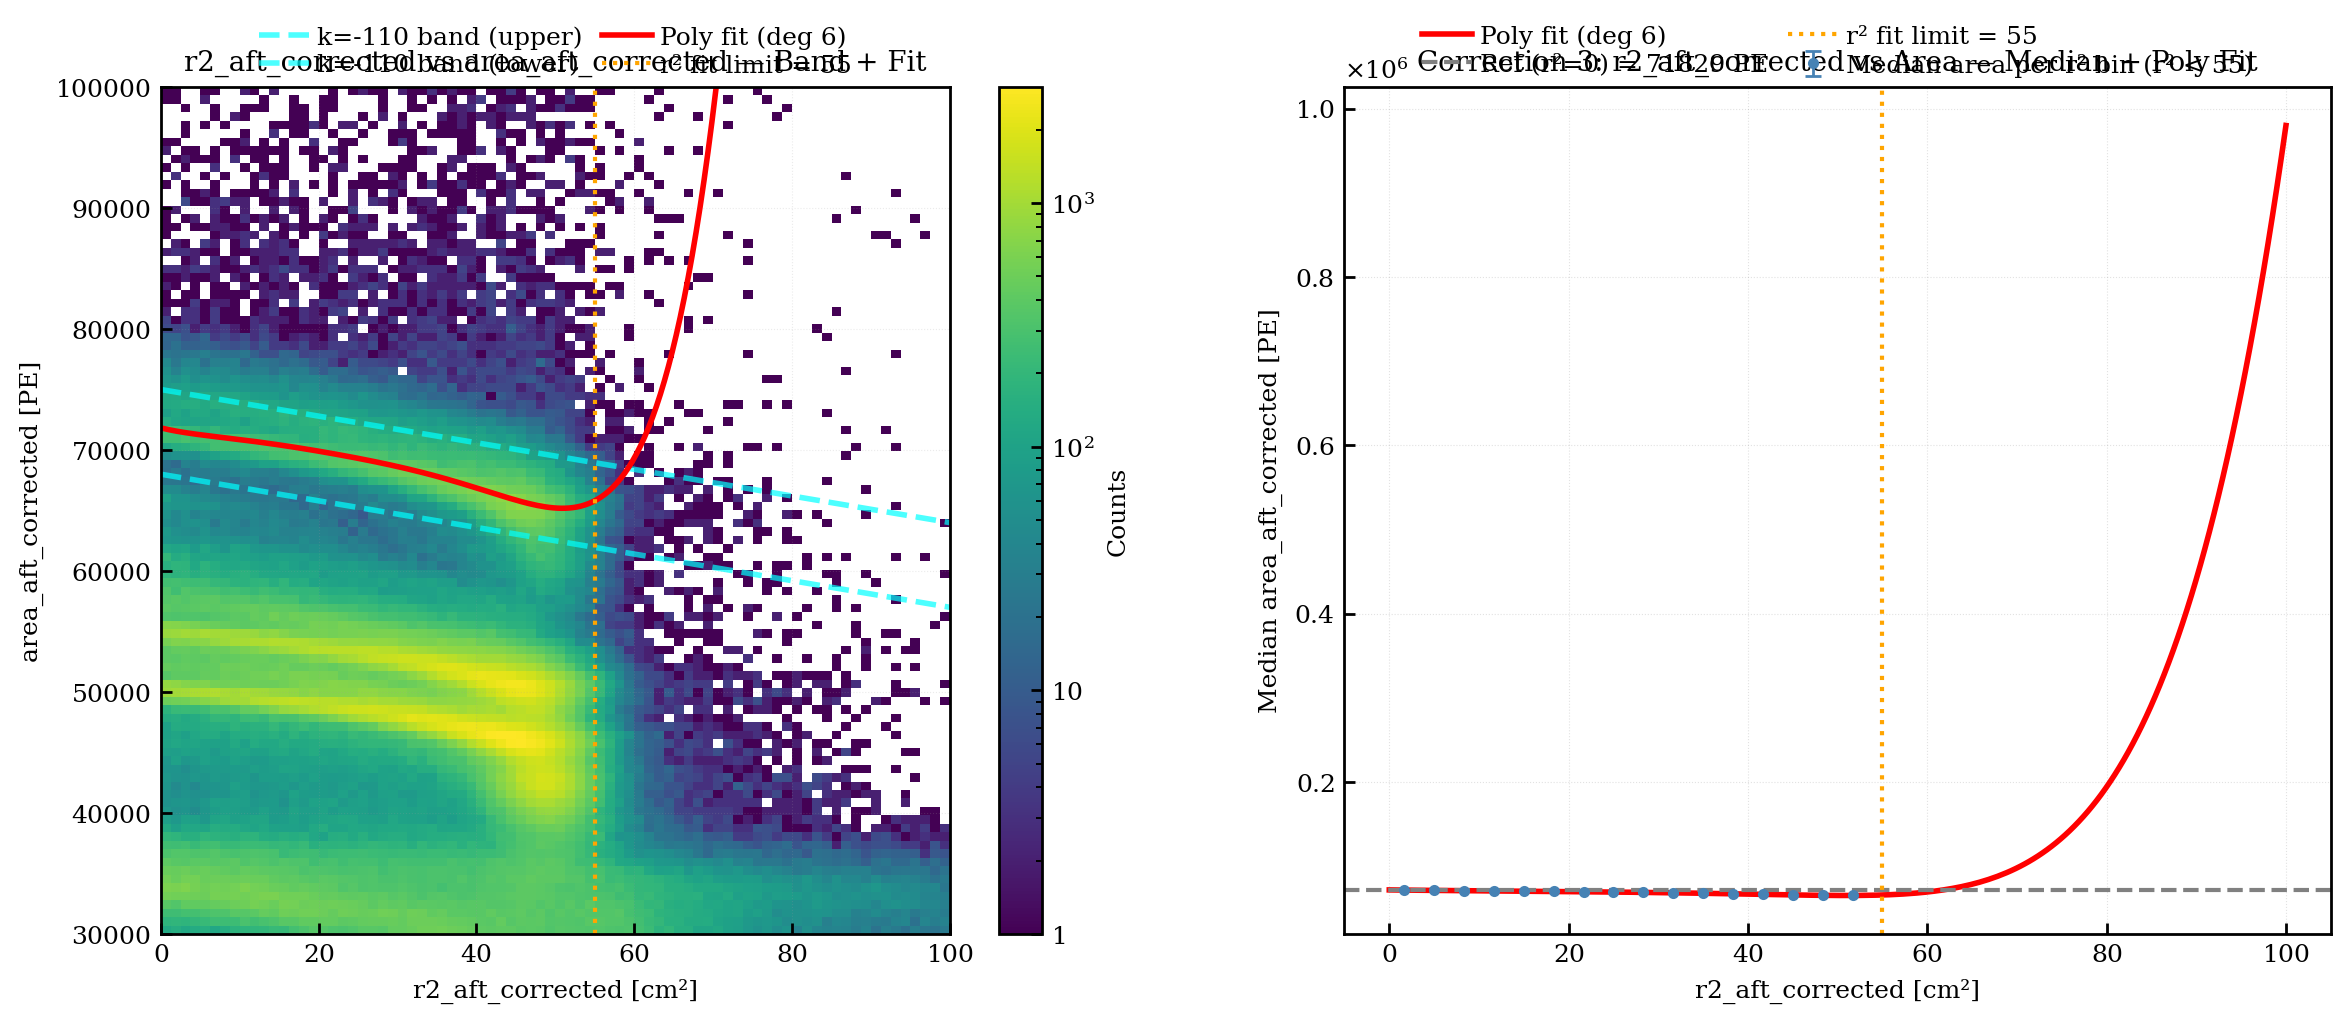

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 3a: r² vs Area — band selection + polynomial fit
# ═══════════════════════════════════════════════════════════════
# Fit AFT-corrected area vs AFT-corrected r².
# Select band with LINEAR boundaries, fit degree-5 polynomial
# to the band centerline using ONLY r² < 60.
#
# X-axis: r2_aft_corrected  (from Correction 2)
# Y-axis: area_aft_corrected (from Correction 1)
# Output: area_2_corrected   (AFT + r² corrected)
#
# Fit range: r2_aft_corrected ∈ [0, 100], area ∈ [0, 1e5]

r2_min_area, r2_max_area = 0, 100
R2_FIT_MAX = 55          # only fit using r² < 60 within the band
POLY_DEG_R2 = 6

# ── Linear band boundaries in r2_aft_corrected vs area_aft_corrected ──
# area = k * r2_aft_corrected + intercept
BAND_K = -110
BAND_INTERCEPT_UPPER = 75000
BAND_INTERCEPT_LOWER = 68000

# Select events in the fit range
mask_r2area = (
    (d_cor['r2_aft_corrected'] >= r2_min_area) & (d_cor['r2_aft_corrected'] <= r2_max_area) &
    (d_cor['area_aft_corrected'] >= 0) & (d_cor['area_aft_corrected'] <= 1e5)
)
d_r2area = d_cor.loc[mask_r2area].copy()

# Tag events inside the linear band
d_r2area['in_r2_band'] = (
    (d_r2area['area_aft_corrected'] < BAND_K * d_r2area['r2_aft_corrected'] + BAND_INTERCEPT_UPPER) &
    (d_r2area['area_aft_corrected'] > BAND_K * d_r2area['r2_aft_corrected'] + BAND_INTERCEPT_LOWER)
)

print(f'Events in fit range: {len(d_r2area):,}')
print(f'Events in linear band (k={BAND_K}): {d_r2area["in_r2_band"].sum():,}')

# ── Bin band events in r2_aft_corrected, get median area_aft_corrected ──
n_r2_bins_area = 30
r2_edges_area = np.linspace(r2_min_area, r2_max_area, n_r2_bins_area + 1)
d_r2area['r2_bin'] = pd.cut(d_r2area['r2_aft_corrected'], bins=r2_edges_area)

medians_area = (
    d_r2area[d_r2area['in_r2_band']]
    .groupby('r2_bin', observed=True)['area_aft_corrected']
    .median()
)
counts_area = (
    d_r2area[d_r2area['in_r2_band']]
    .groupby('r2_bin', observed=True)['area_aft_corrected']
    .count()
)

r2_c_area = medians_area.index.map(lambda iv: iv.mid).astype(float).values
area_meds = medians_area.values

# ── Select bins for fitting: ≥10 events AND r² < R2_FIT_MAX ──
good_area = (counts_area.values >= 10) & (r2_c_area < R2_FIT_MAX)

r2_fit_area = r2_c_area[good_area]
a_fit = area_meds[good_area]
n_fit_area = counts_area.values[good_area]

print(f'r² bins with ≥10 band events & r² < {R2_FIT_MAX}: {len(r2_fit_area)}')
print(f'Median area range: {a_fit.min():.0f} – {a_fit.max():.0f} PE')

# ── Fit degree-N polynomial: area = poly(r2_aft_corrected) ──
p0_r2area = [np.median(a_fit)] + [0.0] * POLY_DEG_R2
popt_r2area, pcov_r2area = curve_fit(polynomial, r2_fit_area, a_fit,
                                      p0=p0_r2area, maxfev=50000)
perr_r2area = np.sqrt(np.diag(pcov_r2area))

print(f'\nDegree-{POLY_DEG_R2} polynomial fit: area(r2_aft_corrected)  [r² < {R2_FIT_MAX}]')
print(f'  c₀ = {popt_r2area[0]:.0f} ± {perr_r2area[0]:.0f} PE')
for i in range(1, min(6, POLY_DEG_R2 + 1)):
    print(f'  c{i} = {popt_r2area[i]:.4e} ± {perr_r2area[i]:.4e}')
print(f'  ... (total {POLY_DEG_R2 + 1} coefficients)')

area_ref_r2 = polynomial(0, *popt_r2area)
print(f'  Reference area (r2_aft_corrected=0) = {area_ref_r2:.0f} PE')

# ── Apply correction: normalize area to r2_aft_corrected=0 ──
cf_r2_raw = area_ref_r2 / polynomial(d_cor['r2_aft_corrected'].values, *popt_r2area)
cf_r2 = np.clip(cf_r2_raw, 0.5, 2.0)

d_cor['area_2_corrected'] = d_cor['area_aft_corrected'] * cf_r2
d_cor['corr3_factor'] = cf_r2

n_clipped_r2 = (cf_r2_raw != cf_r2).sum()
print(f'Correction 3 factor range: [{cf_r2.min():.4f}, {cf_r2.max():.4f}]')
if n_clipped_r2 > 0:
    print(f'  Clipped {n_clipped_r2} values to [0.5, 2.0]')
print(f'Correction 3 applied — new column: area_2_corrected')

# ── Plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: 2D histogram with band boundaries and fit
ax = axes[0]
h = ax.hist2d(d_r2area['r2_aft_corrected'], d_r2area['area_aft_corrected'],
              bins=[80, 100],
              range=[[r2_min_area, r2_max_area], [30e3, 100e3]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')

r2_fine_area = np.linspace(r2_min_area, r2_max_area, 200)
ax.plot(r2_fine_area, BAND_K * r2_fine_area + BAND_INTERCEPT_UPPER,
        '--', color='cyan', lw=2, alpha=0.7, label=f'k={BAND_K} band (upper)')
ax.plot(r2_fine_area, BAND_K * r2_fine_area + BAND_INTERCEPT_LOWER,
        '--', color='cyan', lw=2, alpha=0.7, label=f'k={BAND_K} band (lower)')
ax.plot(r2_fine_area, polynomial(r2_fine_area, *popt_r2area),
        'r-', lw=2, label=f'Poly fit (deg {POLY_DEG_R2})')
ax.axvline(x=R2_FIT_MAX, color='orange', ls=':', lw=1.5,
           label=f'r² fit limit = {R2_FIT_MAX}')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('area_aft_corrected [PE]')
ax.set_title('r2_aft_corrected vs area_aft_corrected — Band + Fit', pad=15)ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Right: Median binned with fit
ax = axes[1]
ax.errorbar(r2_fit_area, a_fit,
            yerr=np.sqrt(np.maximum(a_fit, 1))/np.sqrt(n_fit_area),
            fmt='o', capsize=3, color='steelblue',
            label=f'Median area per r² bin (r² < {R2_FIT_MAX})')
ax.plot(r2_fine_area, polynomial(r2_fine_area, *popt_r2area),
        'r-', lw=2, label=f'Poly fit (deg {POLY_DEG_R2})')
ax.axhline(area_ref_r2, color='gray', ls='--', lw=1.5,
           label=f'Ref (r²=0) = {area_ref_r2:.0f} PE')
ax.axvline(x=R2_FIT_MAX, color='orange', ls=':', lw=1.5,
           label=f'r² fit limit = {R2_FIT_MAX}')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Median area_aft_corrected [PE]')
ax.set_title('Correction 3: r2_aft_corrected vs Area — Median + Poly Fit', pad=15)ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

safe_tight(fig)
plt.show()

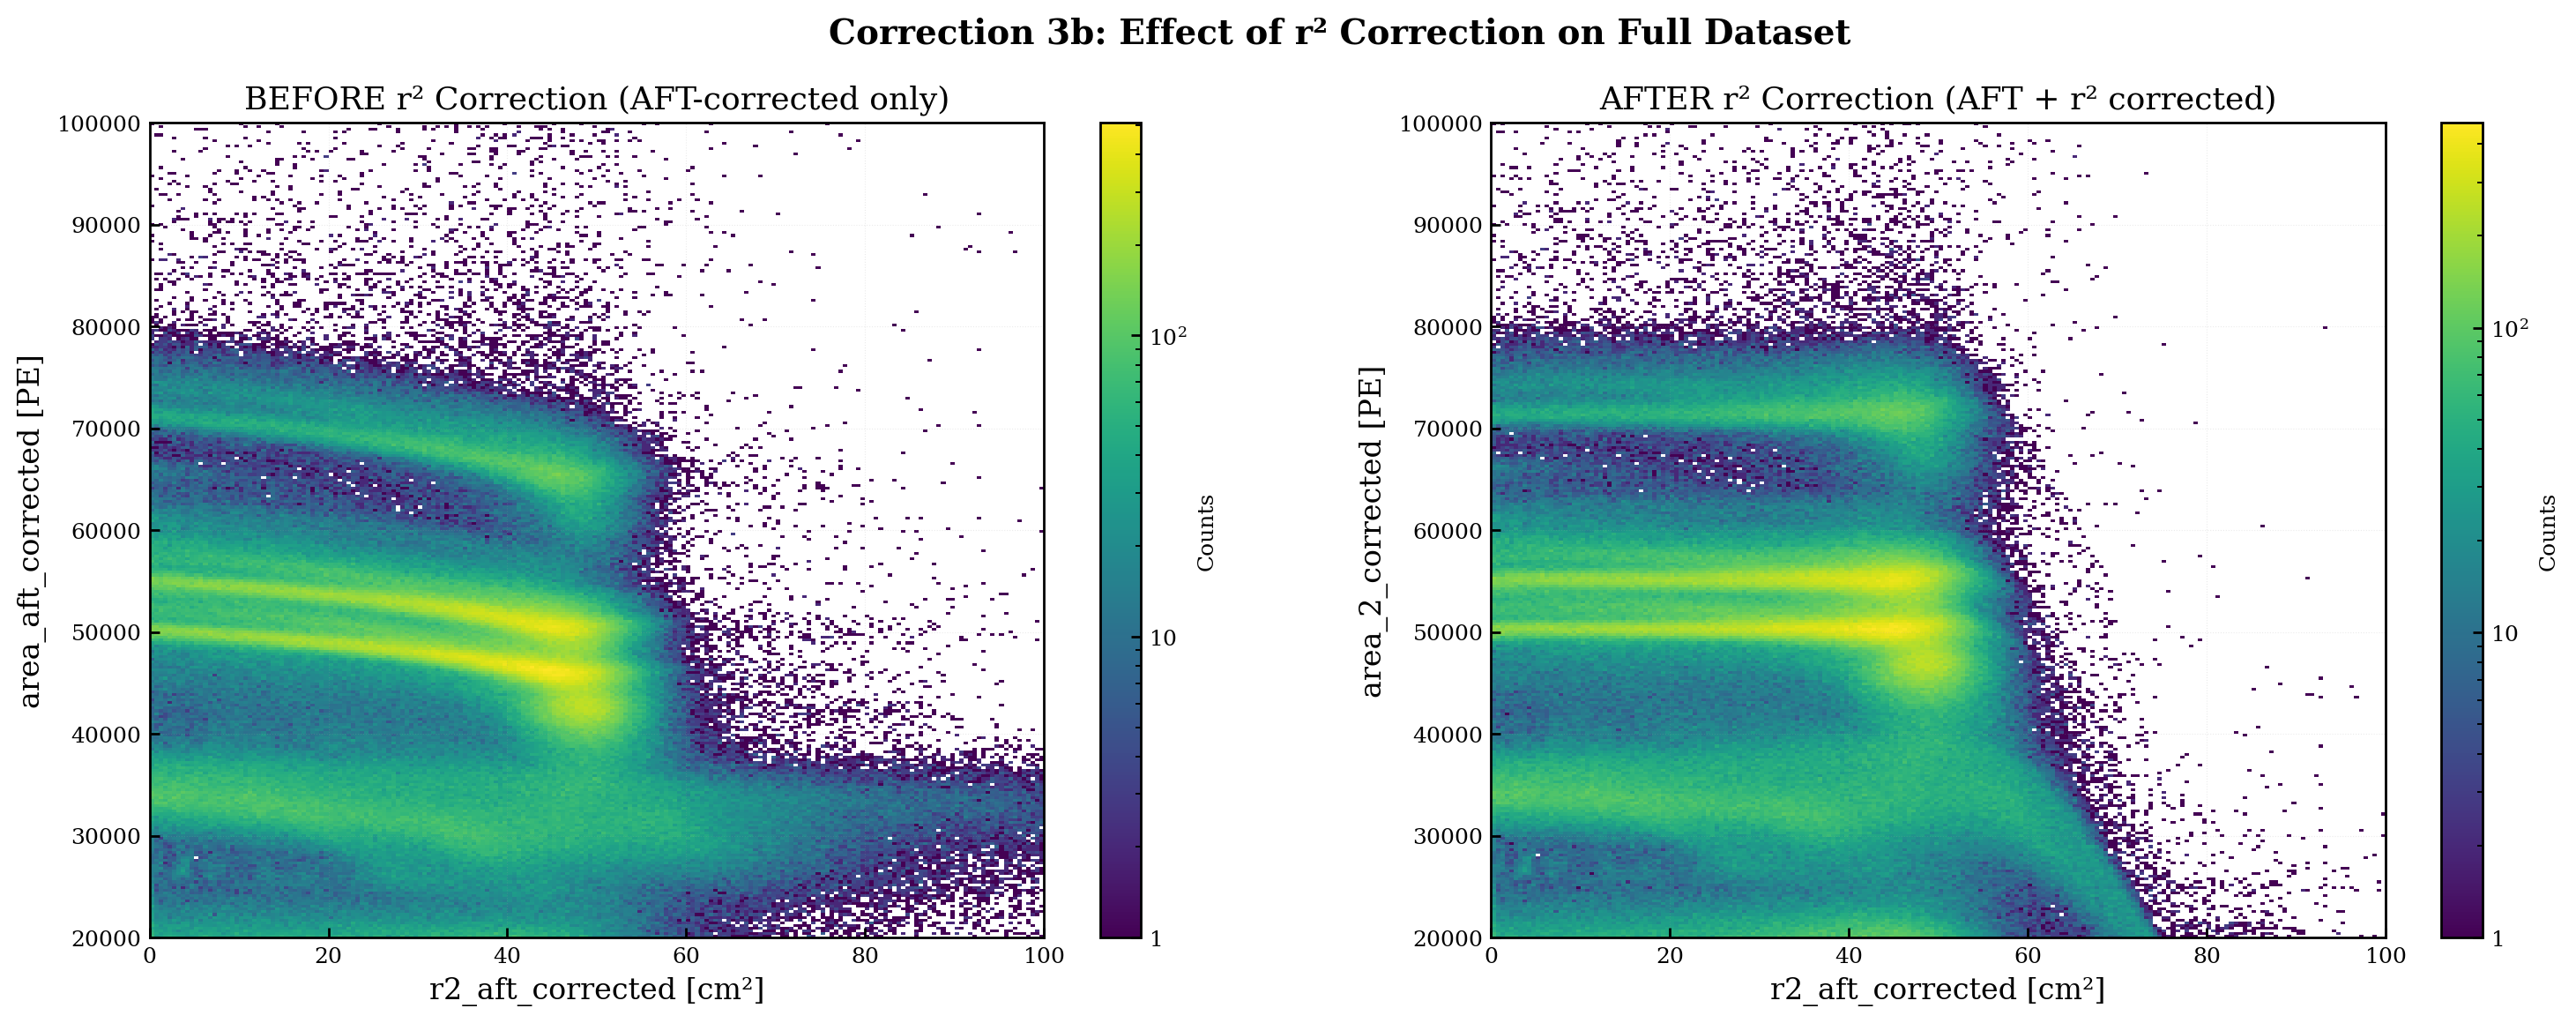

Correction 3b summary:
  area_aft_corrected  μ=2503  σ=9251 PE
  area_2_corrected    μ=2602  σ=9692 PE
  Correction applied to all 32,780,402 events


In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 3b: Before/After — area_aft_corrected vs r2_aft_corrected
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: BEFORE r² correction — area_aft_corrected vs r2_aft_corrected
ax = axes[0]
h = ax.hist2d(d_cor['r2_aft_corrected'], d_cor['area_aft_corrected'],
              bins=[200, 300], range=[[0, 100], [20e3, 100e3]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r2_aft_corrected [cm²]', fontsize=12)
ax.set_ylabel('area_aft_corrected [PE]', fontsize=12)
ax.set_title('BEFORE r² Correction (AFT-corrected only)', pad=15, fontsize=13)
ax.grid(True, alpha=0.2)

# Right: AFTER r² correction — area_2_corrected vs r2_aft_corrected
ax = axes[1]
h = ax.hist2d(d_cor['r2_aft_corrected'], d_cor['area_2_corrected'],
              bins=[200, 300], range=[[0, 100], [20e3, 100e3]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r2_aft_corrected [cm²]', fontsize=12)
ax.set_ylabel('area_2_corrected [PE]', fontsize=12)
ax.set_title('AFTER r² Correction (AFT + r² corrected)', pad=15, fontsize=13)
ax.grid(True, alpha=0.2)

fig.suptitle('Correction 3b: Effect of r² Correction on Full Dataset',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

print(f'Correction 3b summary:')
print(f'  area_aft_corrected  μ={d_cor["area_aft_corrected"].mean():.0f}  σ={d_cor["area_aft_corrected"].std():.0f} PE')
print(f'  area_2_corrected    μ={d_cor["area_2_corrected"].mean():.0f}  σ={d_cor["area_2_corrected"].std():.0f} PE')
print(f'  Correction applied to all {len(d_cor):,} events')

---
## AFT + FV Fiducial Cuts (Post-Correction)

Now apply fiducial cuts that were deferred to after corrections:
1. **AFT cut** [0.12, 0.55] — BiPo + gas band rejection
2. **FV cut** in corrected r² vs AFT space: AFT [0.17, 0.43], r² [0, 40]

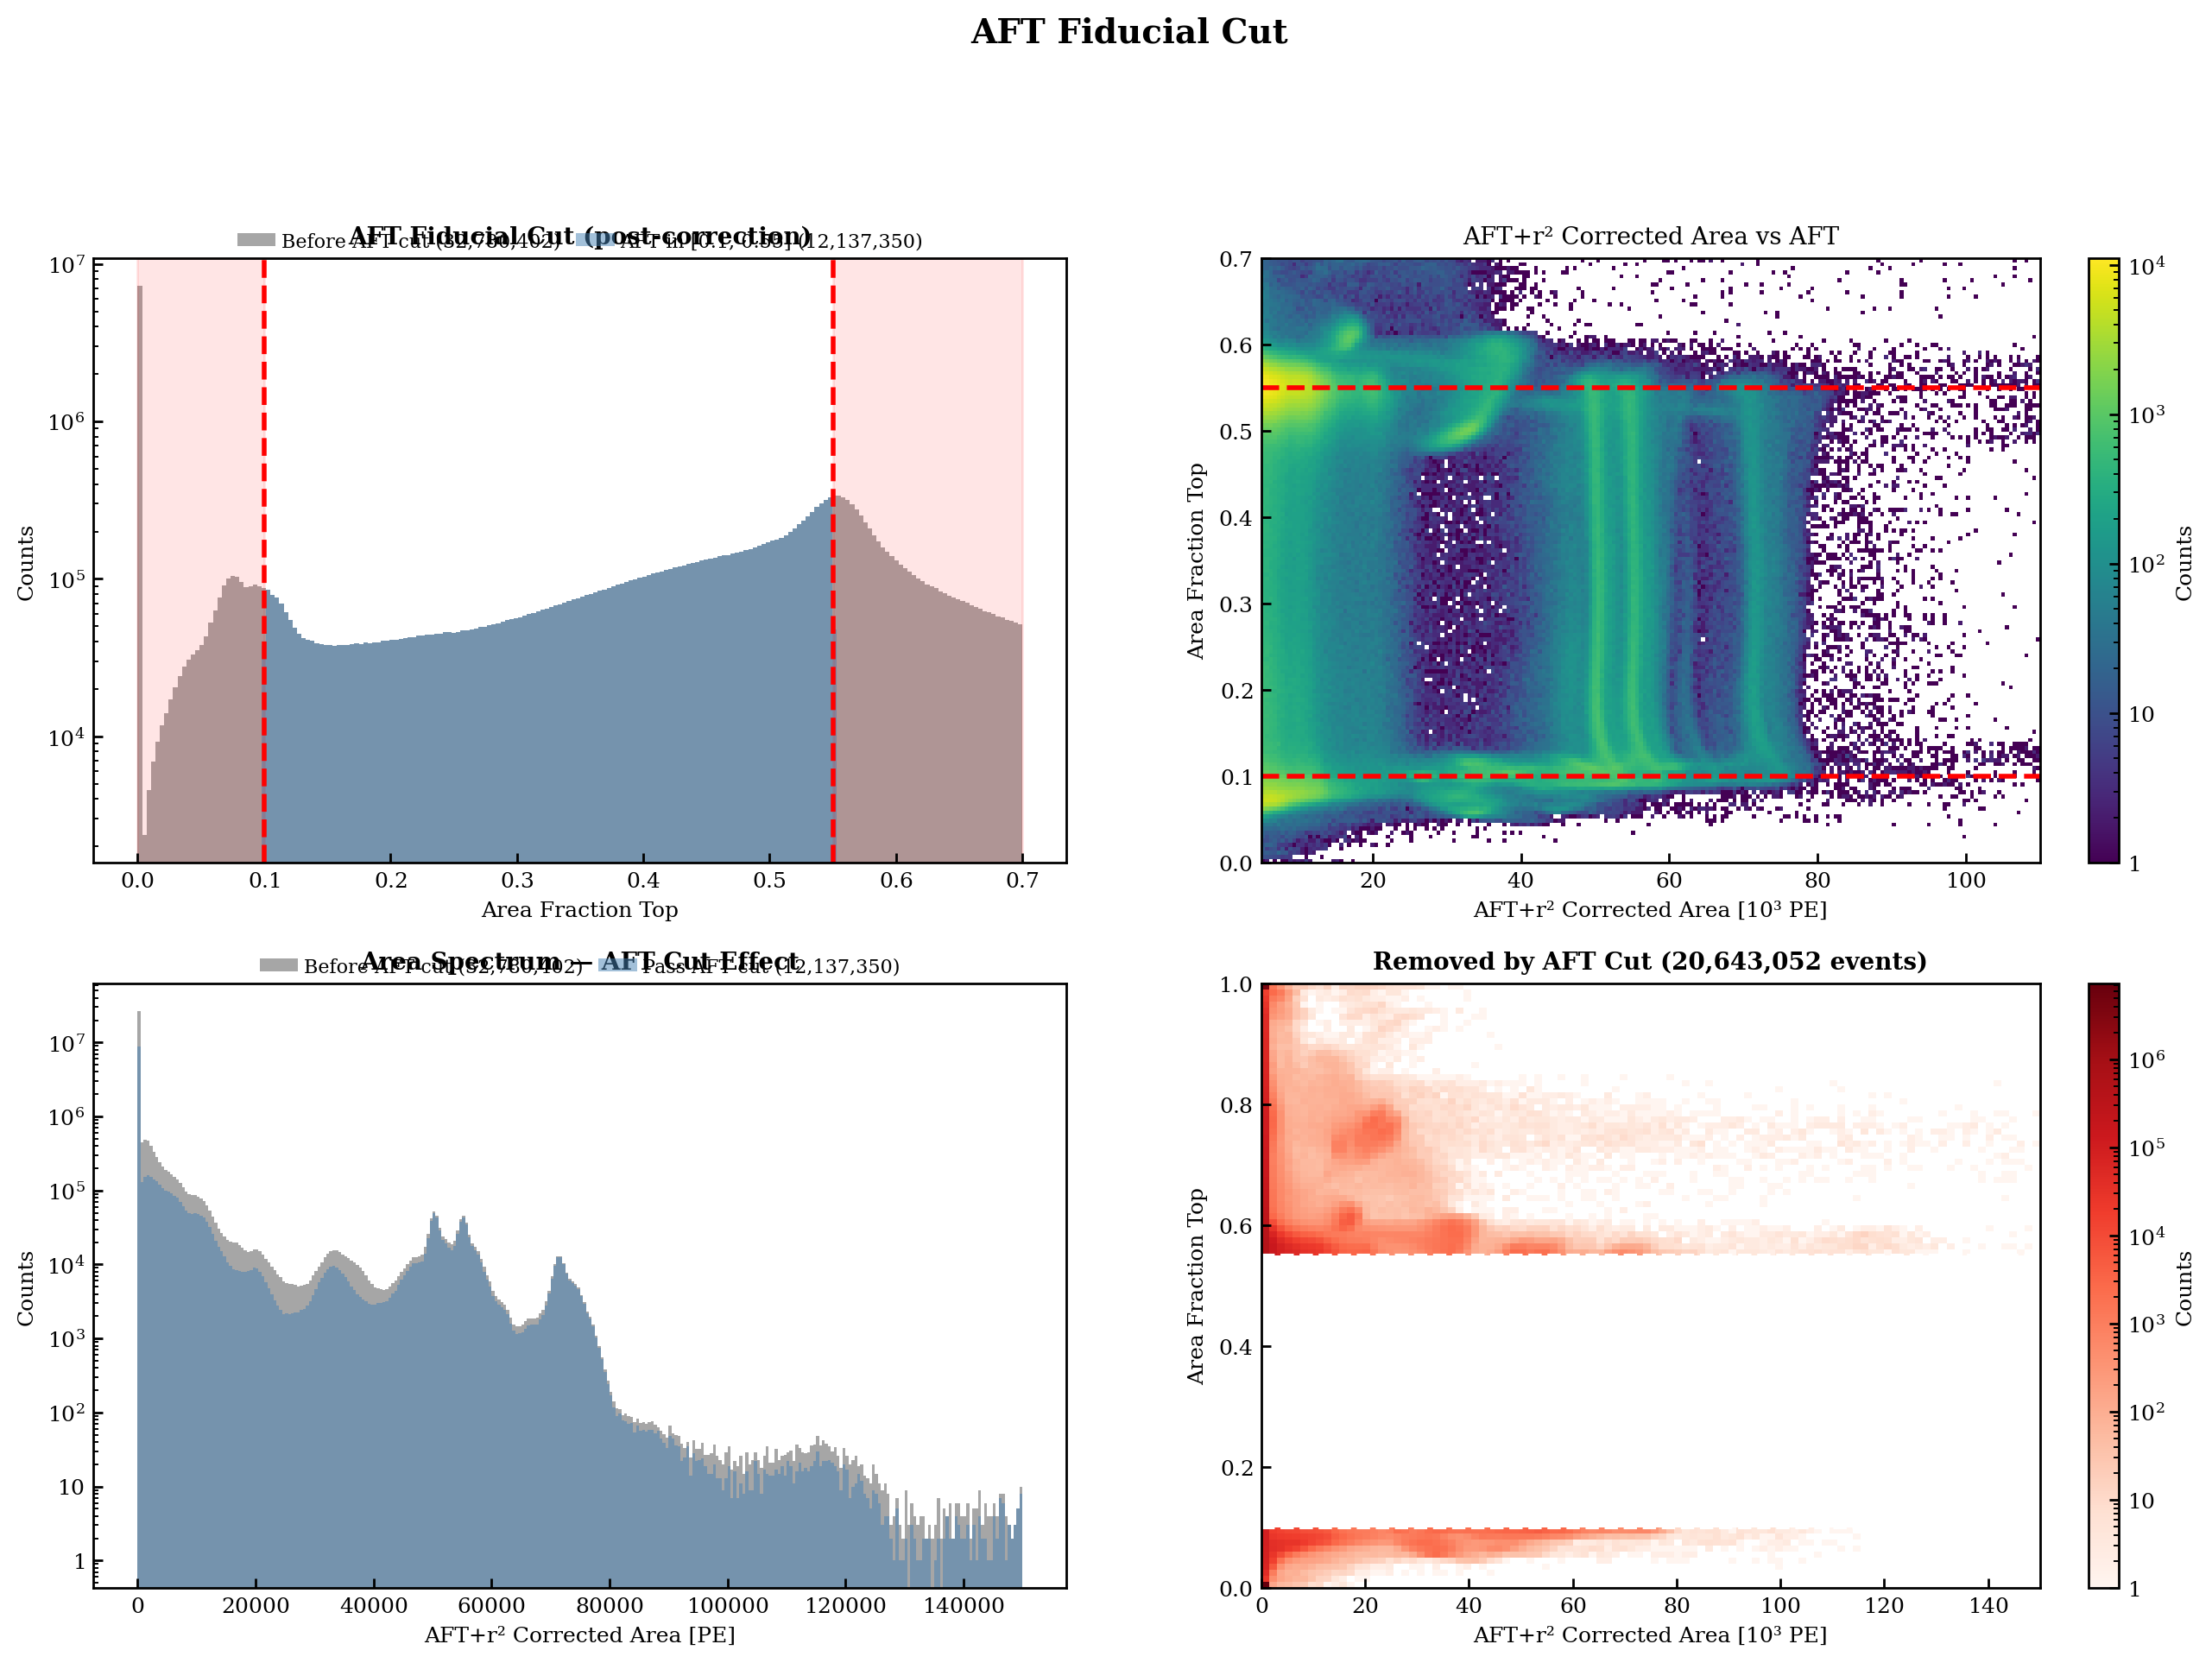

Post-correction AFT cut [0.1, 0.55]:
  Before: 32,780,402
  After:  12,137,350
  Removed: 20,643,052 (63.0%)

FV cut [AFT 0.15-0.455, r2_aft_corrected < 75]:
  Before: 12,137,350
  After:  1,509,672
  Removed: 10,627,678 (87.6%)


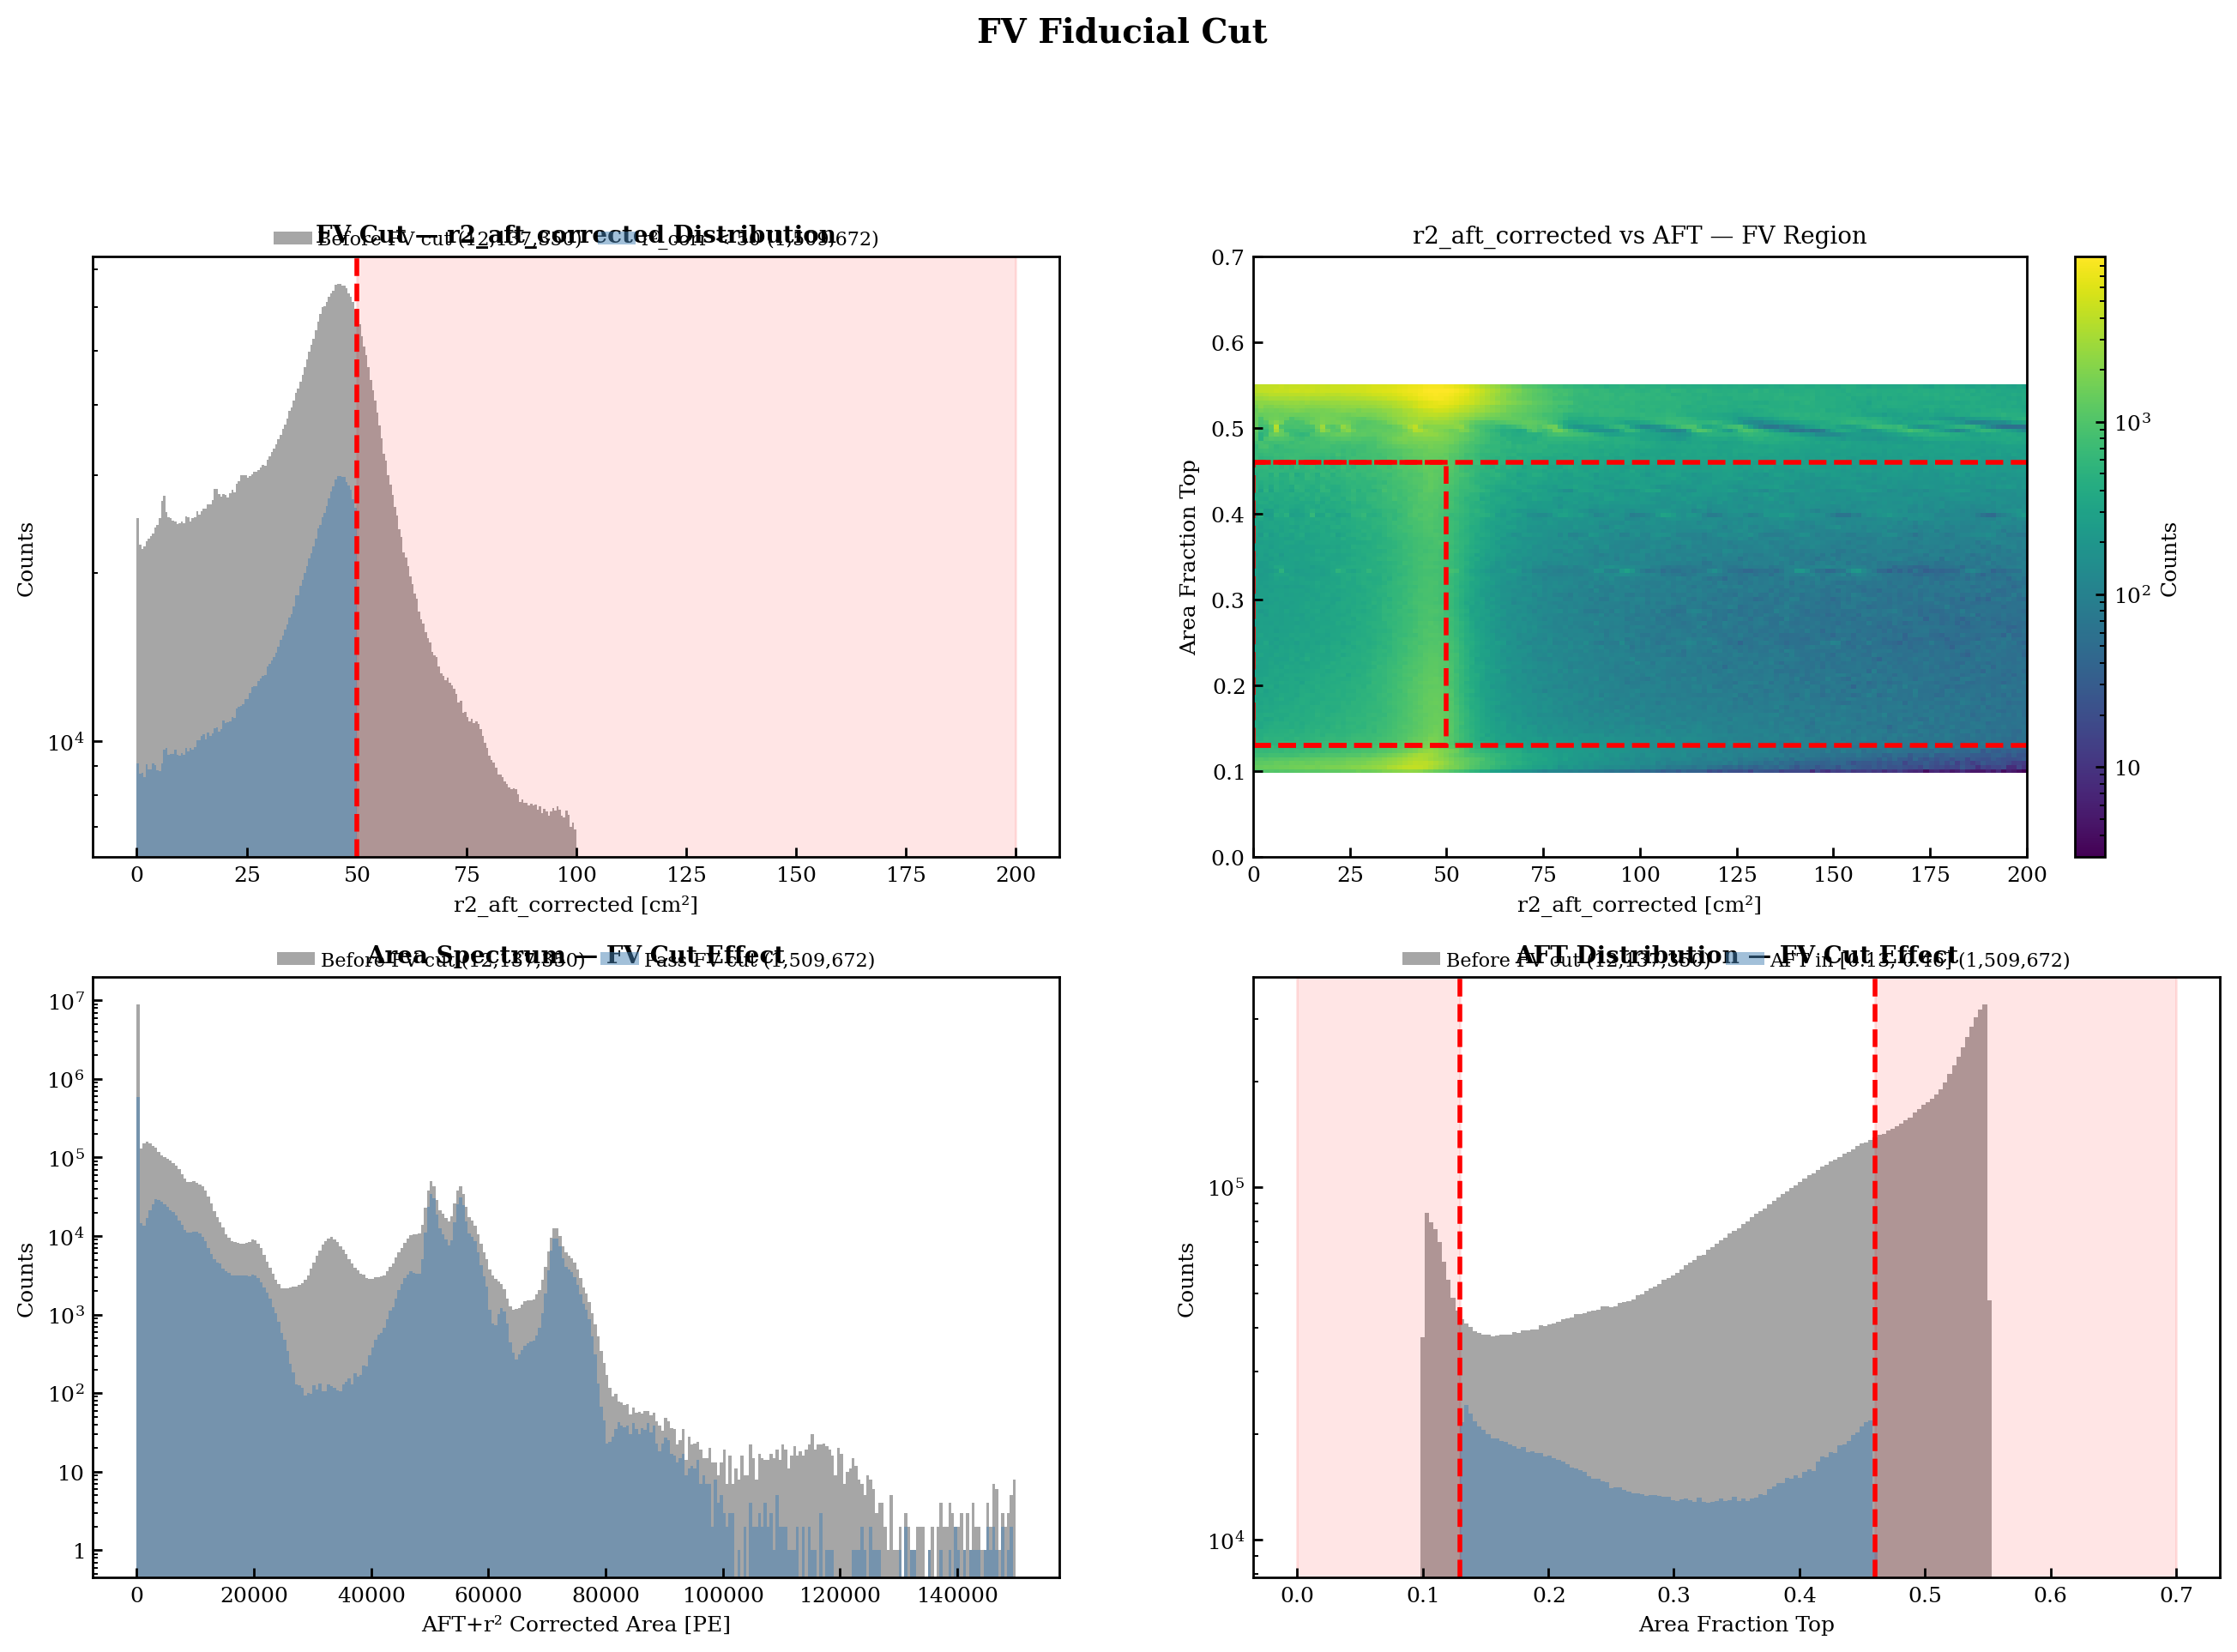


d_cor_aft has 1,509,672 events — ready for rate calculation.


In [ ]:
# ═══════════════════════════════════════════════════════════════
# AFT FIDUCIAL CUT — applied after corrections
# ═══════════════════════════════════════════════════════════════

AFT_MIN = 0.1
AFT_MAX = 0.55

m_aft = (d_cor['area_fraction_top'] > AFT_MIN) & (d_cor['area_fraction_top'] < AFT_MAX)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Top-left: AFT 1D
ax = axes[0, 0]
ax.hist(d_cor['area_fraction_top'], bins=200, range=[0, 0.7],
        color='gray', alpha=0.7, label=f'Before AFT cut ({len(d_cor):,})')
ax.hist(d_cor.loc[m_aft, 'area_fraction_top'], bins=200, range=[0, 0.7],
        color='steelblue', alpha=0.5,
        label=f'AFT in [{AFT_MIN}, {AFT_MAX}] ({m_aft.sum():,})')
ax.axvline(x=AFT_MIN, color='red', ls='--', lw=2)
ax.axvline(x=AFT_MAX, color='red', ls='--', lw=2)
ax.axvspan(0, AFT_MIN, alpha=0.1, color='red')
ax.axvspan(AFT_MAX, 0.7, alpha=0.1, color='red')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('AFT Fiducial Cut (post-correction)', fontweight='bold', pad=15)ax.legend(fontsize=8)

# Top-right: AFT+r² Corrected Area vs AFT
ax = axes[0, 1]
h = ax.hist2d(d_cor['area_2_corrected']/1e3, d_cor['area_fraction_top'],
              bins=[200, 150], range=[[5, 110], [0, 0.7]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
ax.axhline(y=AFT_MIN, color='red', ls='--', lw=2)
ax.axhline(y=AFT_MAX, color='red', ls='--', lw=2)
ax.set_xlabel('AFT+r² Corrected Area [10³ PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('AFT+r² Corrected Area vs AFT', pad=15)plt.colorbar(h[3], ax=ax, label='Counts')

# Bottom-left: Area 1D before/after
ax = axes[1, 0]
ax.hist(d_cor['area_2_corrected'], bins=300, range=[0, 150e3],
        color='gray', alpha=0.7, label=f'Before AFT cut ({len(d_cor):,})')
ax.hist(d_cor.loc[m_aft, 'area_2_corrected'], bins=300, range=[0, 150e3],
        color='steelblue', alpha=0.5,
        label=f'Pass AFT cut ({m_aft.sum():,})')
ax.set_xlabel('AFT+r² Corrected Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('Area Spectrum — AFT Cut Effect', fontweight='bold', pad=15)ax.legend(fontsize=8)

# Bottom-right: Removed events
ax = axes[1, 1]
removed = ~m_aft
h = ax.hist2d(d_cor.loc[removed, 'area_2_corrected']/1e3,
              d_cor.loc[removed, 'area_fraction_top'],
              bins=[100, 100], range=[[0, 150], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='Reds')
ax.axhline(y=AFT_MIN, color='white', ls='--', lw=1.5)
ax.axhline(y=AFT_MAX, color='white', ls='--', lw=1.5)
ax.set_xlabel('AFT+r² Corrected Area [10³ PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title(f'Removed by AFT Cut ({removed.sum():,} events)', fontweight='bold', pad=15)plt.colorbar(h[3], ax=ax, label='Counts')

fig.suptitle('AFT Fiducial Cut', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

# ── Apply AFT cut ──
d_cor_aft = d_cor[m_aft].copy().reset_index(drop=True)

print(f'Post-correction AFT cut [{AFT_MIN}, {AFT_MAX}]:')
print(f'  Before: {len(d_cor):,}')
print(f'  After:  {len(d_cor_aft):,}')
print(f'  Removed: {(~m_aft).sum():,} ({100*(~m_aft).sum()/len(d_cor):.1f}%)')

# ═══════════════════════════════════════════════════════════════
# FV CUT — in corrected r² vs AFT space (r2_aft_corrected)
# ═══════════════════════════════════════════════════════════════

AFT_FV_MIN, AFT_FV_MAX = 0.15, 0.455
R2_FV_MAX = 75

m_fv = (
    (d_cor_aft['area_fraction_top'] >= AFT_FV_MIN) &
    (d_cor_aft['area_fraction_top'] <= AFT_FV_MAX) &
    (d_cor_aft['r2_aft_corrected'] >= 0) &
    (d_cor_aft['r2_aft_corrected'] <= R2_FV_MAX)
)

print(f'\nFV cut [AFT {AFT_FV_MIN}-{AFT_FV_MAX}, r2_aft_corrected < {R2_FV_MAX}]:')
print(f'  Before: {len(d_cor_aft):,}')
print(f'  After:  {m_fv.sum():,}')
print(f'  Removed: {(~m_fv).sum():,} ({100*(~m_fv).sum()/len(d_cor_aft):.1f}%)')

# ── FV Cut diagnostic plots ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Top-left: r2_aft_corrected 1D before/after
ax = axes[0, 0]
ax.hist(d_cor_aft['r2_aft_corrected'], bins=200, range=[0, 100],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'r2_aft_corrected'], bins=200, range=[0, 100],
        color='steelblue', alpha=0.5,
        label=f'r²_corr < {R2_FV_MAX} ({m_fv.sum():,})')
ax.axvline(x=R2_FV_MAX, color='red', ls='--', lw=2)
ax.axvspan(R2_FV_MAX, 200, alpha=0.1, color='red')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('FV Cut — r2_aft_corrected Distribution', fontweight='bold', pad=15)ax.legend(fontsize=8)

# Top-right: r2_aft_corrected vs AFT with FV box
ax = axes[0, 1]
h = ax.hist2d(d_cor_aft['r2_aft_corrected'], d_cor_aft['area_fraction_top'],
              bins=[150, 150], range=[[0, 200], [0, 0.7]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
from matplotlib.patches import Rectangle
rect = Rectangle((0, AFT_FV_MIN), R2_FV_MAX, AFT_FV_MAX - AFT_FV_MIN,
                 linewidth=2, edgecolor='red', facecolor='none', ls='--')
ax.add_patch(rect)
ax.axhline(y=AFT_FV_MIN, color='red', ls='--', lw=2)
ax.axhline(y=AFT_FV_MAX, color='red', ls='--', lw=2)
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r2_aft_corrected vs AFT — FV Region', pad=15)plt.colorbar(h[3], ax=ax, label='Counts')

# Bottom-left: AFT+r² Corrected Area 1D before/after
ax = axes[1, 0]
ax.hist(d_cor_aft['area_2_corrected'], bins=300, range=[0, 150e3],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'area_2_corrected'], bins=300, range=[0, 150e3],
        color='steelblue', alpha=0.5,
        label=f'Pass FV cut ({m_fv.sum():,})')
ax.set_xlabel('AFT+r² Corrected Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('Area Spectrum — FV Cut Effect', fontweight='bold', pad=15)ax.legend(fontsize=8)

# Bottom-right: AFT 1D before/after
ax = axes[1, 1]
ax.hist(d_cor_aft['area_fraction_top'], bins=200, range=[0, 0.7],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'area_fraction_top'], bins=200, range=[0, 0.7],
        color='steelblue', alpha=0.5,
        label=f'AFT in [{AFT_FV_MIN}, {AFT_FV_MAX}] ({m_fv.sum():,})')
ax.axvline(x=AFT_FV_MIN, color='red', ls='--', lw=2)
ax.axvline(x=AFT_FV_MAX, color='red', ls='--', lw=2)
ax.axvspan(0, AFT_FV_MIN, alpha=0.1, color='red')
ax.axvspan(AFT_FV_MAX, 0.7, alpha=0.1, color='red')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('AFT Distribution — FV Cut Effect', fontweight='bold', pad=15)ax.legend(fontsize=8)

fig.suptitle('FV Fiducial Cut', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

# ── Apply FV cut ──
d_cor_aft = d_cor_aft[m_fv].copy().reset_index(drop=True)

print(f'\nd_cor_aft has {len(d_cor_aft):,} events — ready for rate calculation.')

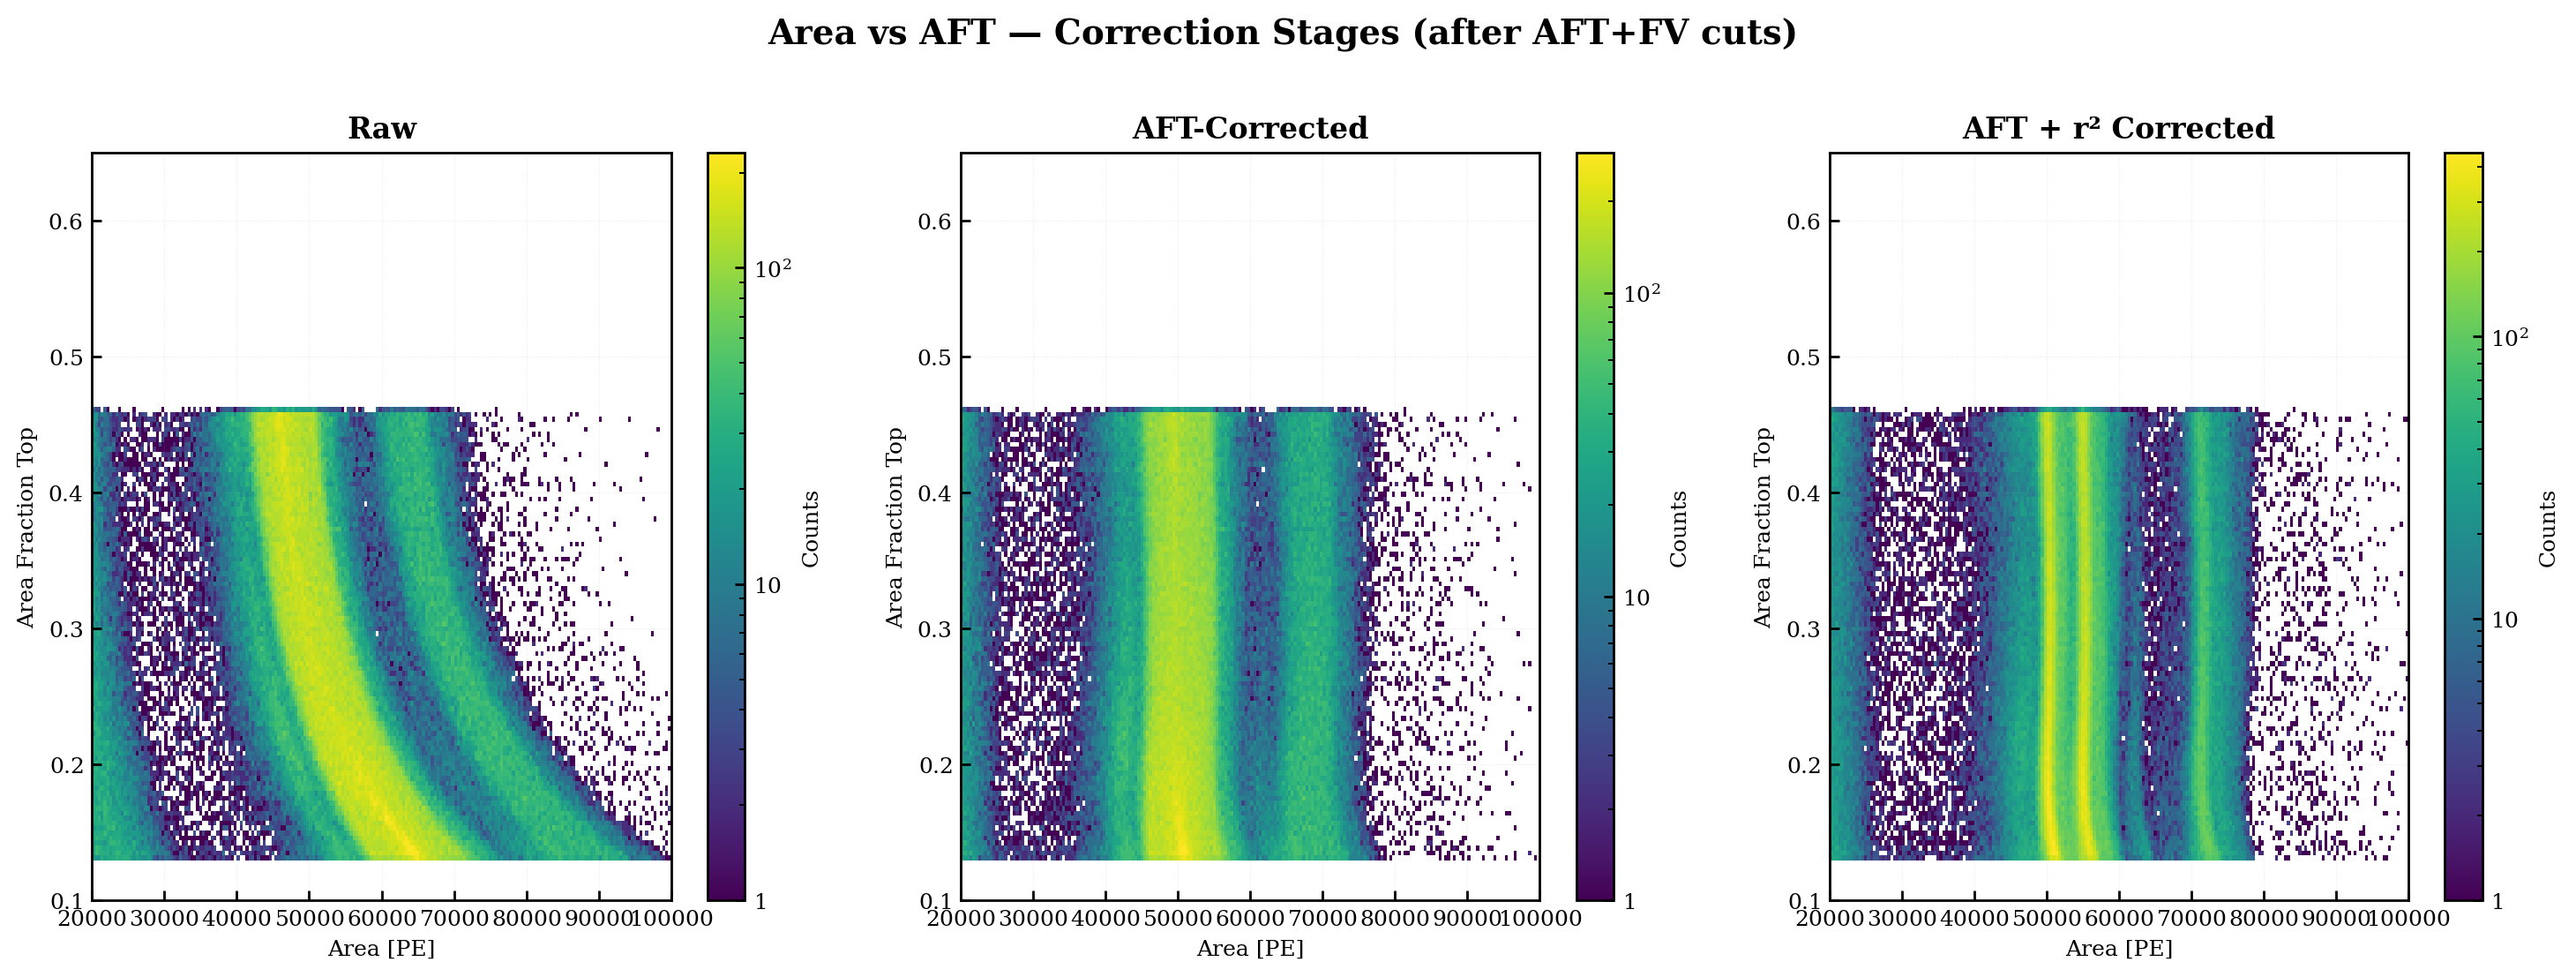

In [ ]:
# ═══════════════════════════════════════════════════════════════
# BEFORE/AFTER COMPARISON — all correction stages
# ═══════════════════════════════════════════════════════════════

stages = [
    ('Raw',                    'area'),
    ('AFT-Corrected',          'area_aft_corrected'),
    ('AFT + r² Corrected',     'area_2_corrected'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (label, col) in zip(axes, stages):
    if col in d_cor_aft.columns:
        h = ax.hist2d(d_cor_aft[col], d_cor_aft['area_fraction_top'],
                      bins=[200, 150],
                      range=[[20e3, 100e3], [0.1, 0.65]],
                      cmin=1, norm=matplotlib.colors.LogNorm())
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('Area [PE]')
        ax.set_ylabel('Area Fraction Top')
        ax.set_title(label, fontweight='bold', pad=15, fontsize=12)
        ax.grid(True, alpha=0.2)

fig.suptitle('Area vs AFT — Correction Stages (after AFT+FV cuts)', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

---
## Rate Calculation

Use all events after applying all fiducial cuts and corrections.

Events for rate analysis (after all cuts + corrections): 1,509,672
Before 2026-06-08: 269,559 events
After  2026-06-08: 1,240,113 events
Peak energies (MeV):
  Rn-222      5.49 MeV  →  before: 52,000 PE  |  after: 50,700 PE
  Po-218      6.00 MeV  →  before: 56,830 PE  |  after: 55,409 PE
  Rn-220      6.29 MeV  →  before: 59,577 PE  |  after: 58,087 PE
  Po-216      6.78 MeV  →  before: 64,218 PE  |  after: 62,613 PE
  Po-214      7.69 MeV  →  before: 72,837 PE  |  after: 71,016 PE


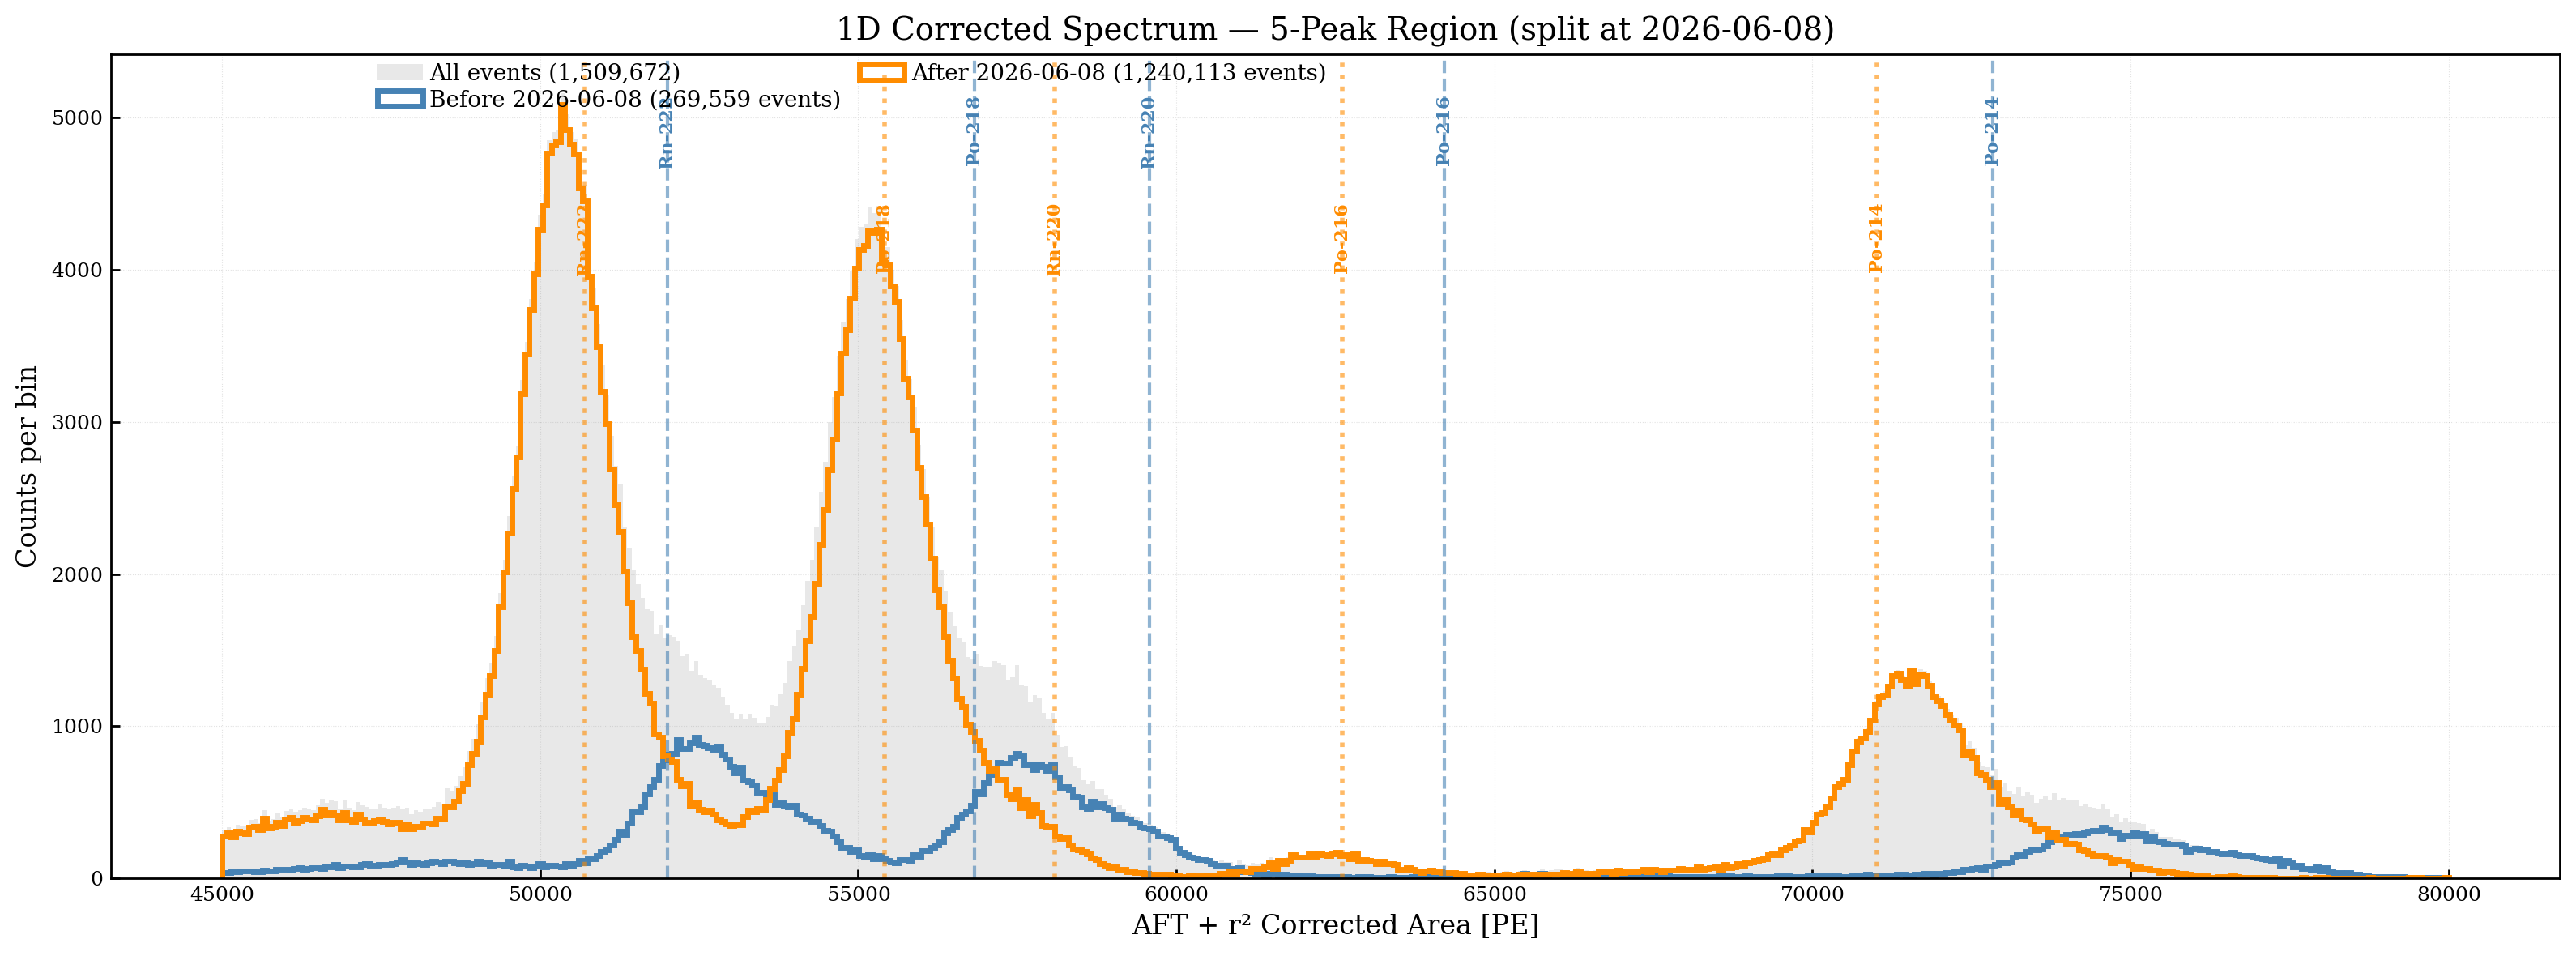


Spectrum range: 45000 – 80000 PE
Bin width: 70.0 PE
Max bin count: 5161
Total counts in histogram: 428,183

Detected peak positions (for reference):
  50355 PE (height: 5161)
  55325 PE (height: 4419)
  51895 PE (height: 1664)
  56865 PE (height: 1478)
  71565 PE (height: 1386)
  53645 PE (height: 1139)
  58055 PE (height: 1086)
  72895 PE (height: 718)
  48535 PE (height: 591)
  73945 PE (height: 529)

Initial guesses for 5-Gaussian fit:
  Rn-222      μ₀ = 52,000 PE
  Po-218      μ₀ = 56,830 PE
  Rn-220      μ₀ = 59,577 PE
  Po-216      μ₀ = 64,218 PE
  Po-214      μ₀ = 72,837 PE


In [ ]:
# ═══════════════════════════════════════════════════════════════
# 1D CORRECTED SPECTRUM — wide range for multi-peak fit
# ═══════════════════════════════════════════════════════════════
# Use ALL events after cuts and corrections.
# Split by date boundary to check for rate changes.

CUTOFF_DATE = '2026-06-08'

rn_events = d_cor_aft.copy()
print(f'Events for rate analysis (after all cuts + corrections): {len(rn_events):,}')

# ── Split by date ──
boundary_ns = np.datetime64(CUTOFF_DATE).astype('datetime64[ns]').astype('int64')
mask_before = rn_events['time'] < boundary_ns
mask_after  = rn_events['time'] >= boundary_ns
print(f'Before {CUTOFF_DATE}: {mask_before.sum():,} events')
print(f'After  {CUTOFF_DATE}: {mask_after.sum():,} events')

# ── Peak positions from known alpha energies ──
# Energies in MeV (NIST/ENSDF):
E_RN222 = 5.59   # Rn-222
E_PO218 = 6.00   # Po-218
E_RN220 = 6.29   # Rn-220
E_PO216 = 6.78   # Po-216
E_PO214 = 7.69   # Po-214

PEAK_NAMES   = ['Rn-222', 'Po-218', 'Rn-220', 'Po-216', 'Po-214']
PEAK_ENERGIES = np.array([E_RN222, E_PO218, E_RN220, E_PO216, E_PO214])

# ── Rn-222 anchor positions for before & after (tune these!) ──
RN222_PEAK_POS_BEFORE = 52000
RN222_PEAK_POS_AFTER  = 50700

# Scale all peaks by energy ratio E / E_Rn222
GUESS_MU_BEFORE = (RN222_PEAK_POS_BEFORE * PEAK_ENERGIES / E_RN222).astype(int)
GUESS_MU_AFTER  = (RN222_PEAK_POS_AFTER  * PEAK_ENERGIES / E_RN222).astype(int)

# Use 'before' guesses for the overview plot annotations
GUESS_MU   = GUESS_MU_BEFORE
GUESS_SIGMA = 800
N_PEAKS     = len(PEAK_NAMES)

print(f'Peak energies (MeV):')
for name, e in zip(PEAK_NAMES, PEAK_ENERGIES):
    print(f'  {name:10s}  {e:.2f} MeV  →  before: {GUESS_MU_BEFORE[PEAK_NAMES.index(name)]:,} PE  |  after: {GUESS_MU_AFTER[PEAK_NAMES.index(name)]:,} PE')

# ── Histogram (split by date) ──
fig, ax = plt.subplots(figsize=(16, 6))

hist_range = [45e3, 80e3]
hist_bins = 500

# All events (light filled background)
ax.hist(
    rn_events['area_2_corrected'],
    bins=hist_bins, range=hist_range,
    color='lightgray', alpha=0.5,
    label=f'All events ({len(rn_events):,})'
)

# Before 2026-04-22 (steelblue step)
ax.hist(
    rn_events.loc[mask_before, 'area_2_corrected'],
    bins=hist_bins, range=hist_range,
    histtype='step', color='steelblue', lw=2.5,
    label=f'Before {CUTOFF_DATE} ({mask_before.sum():,} events)'
)

# After 2026-04-22 (darkorange step)
ax.hist(
    rn_events.loc[mask_after, 'area_2_corrected'],
    bins=hist_bins, range=hist_range,
    histtype='step', color='darkorange', lw=2.5,
    label=f'After {CUTOFF_DATE} ({mask_after.sum():,} events)'
)

# Mark guess positions — steelblue=before, darkorange=after
for mu, name in zip(GUESS_MU_BEFORE, PEAK_NAMES):
    ax.axvline(x=mu, color='steelblue', ls='--', lw=1.5, alpha=0.6)
    ax.annotate(name, xy=(mu, ax.get_ylim()[1]*0.95), fontsize=8,
                color='steelblue', ha='center', fontweight='bold',
                rotation=90, va='top')
for mu, name in zip(GUESS_MU_AFTER, PEAK_NAMES):
    ax.axvline(x=mu, color='darkorange', ls=':', lw=2, alpha=0.6)
    ax.annotate(name, xy=(mu, ax.get_ylim()[1]*0.82), fontsize=8,
                color='darkorange', ha='center', fontweight='bold',
                rotation=90, va='top')

ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Counts per bin', fontsize=12)
#ax.set_yscale('log')
ax.set_title(f'1D Corrected Spectrum — 5-Peak Region (split at {CUTOFF_DATE})', pad=15, fontsize=14)
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
safe_tight(fig)
plt.show()

# ── np.histogram for find_peaks (use all events) ──
counts_rn, edges_rn = np.histogram(
    rn_events['area_2_corrected'],
    bins=hist_bins, range=hist_range
)
bin_centers_rn = 0.5 * (edges_rn[:-1] + edges_rn[1:])
bin_width_rn = edges_rn[1] - edges_rn[0]

# Find peak positions for initial guesses
peaks_idx, peaks_props = find_peaks(counts_rn, height=counts_rn.max()*0.02, distance=15)
peak_positions = bin_centers_rn[peaks_idx]
peak_heights = counts_rn[peaks_idx]

print(f'\nSpectrum range: {edges_rn[0]:.0f} – {edges_rn[-1]:.0f} PE')
print(f'Bin width: {bin_width_rn:.1f} PE')
print(f'Max bin count: {counts_rn.max():.0f}')
print(f'Total counts in histogram: {counts_rn.sum():,.0f}')
print(f'\nDetected peak positions (for reference):')
for pos, height in sorted(zip(peak_positions, peak_heights), key=lambda x: x[1], reverse=True)[:10]:
    print(f'  {pos:.0f} PE (height: {height:.0f})')

print(f'\nInitial guesses for {N_PEAKS}-Gaussian fit:')
for name, mu in zip(PEAK_NAMES, GUESS_MU):
    print(f'  {name:10s}  μ₀ = {mu:,} PE')

Fitting 5 Gaussians + background for before and after 2026-06-08...


  BEFORE 2026-06-08  —  5-GAUSSIAN FIT RESULTS
Peak             μ [PE]     σ [PE]    Amplitude      σ/μ
-------------------------------------------------------------------------------------
Rn-222         52813 ±    30    1123 ±   27       805 ±     26   2.13%
Po-218         57470 ±   163     818 ±   79       699 ±     94   1.42%
Rn-220         59197 ±   418     899 ±  172       296 ±     85   1.52%
Po-216         65218 ±   342     444 ±  326        10 ±      7   0.68%
Po-214         73837 ±    79    1121 ±   63       205 ±     13   1.52%
bg                     —           —      10.4 ±    1.2

  AFTER  2026-06-08  —  5-GAUSSIAN FIT RESULTS
Peak             μ [PE]     σ [PE]    Amplitude      σ/μ
-------------------------------------------------------------------------------------
Rn-222         50418 ±    11     849 ±    9      4318 ±     70   1.68%
Po-218         55248 ±    21     822 ±   16      3953 ±     69   1.

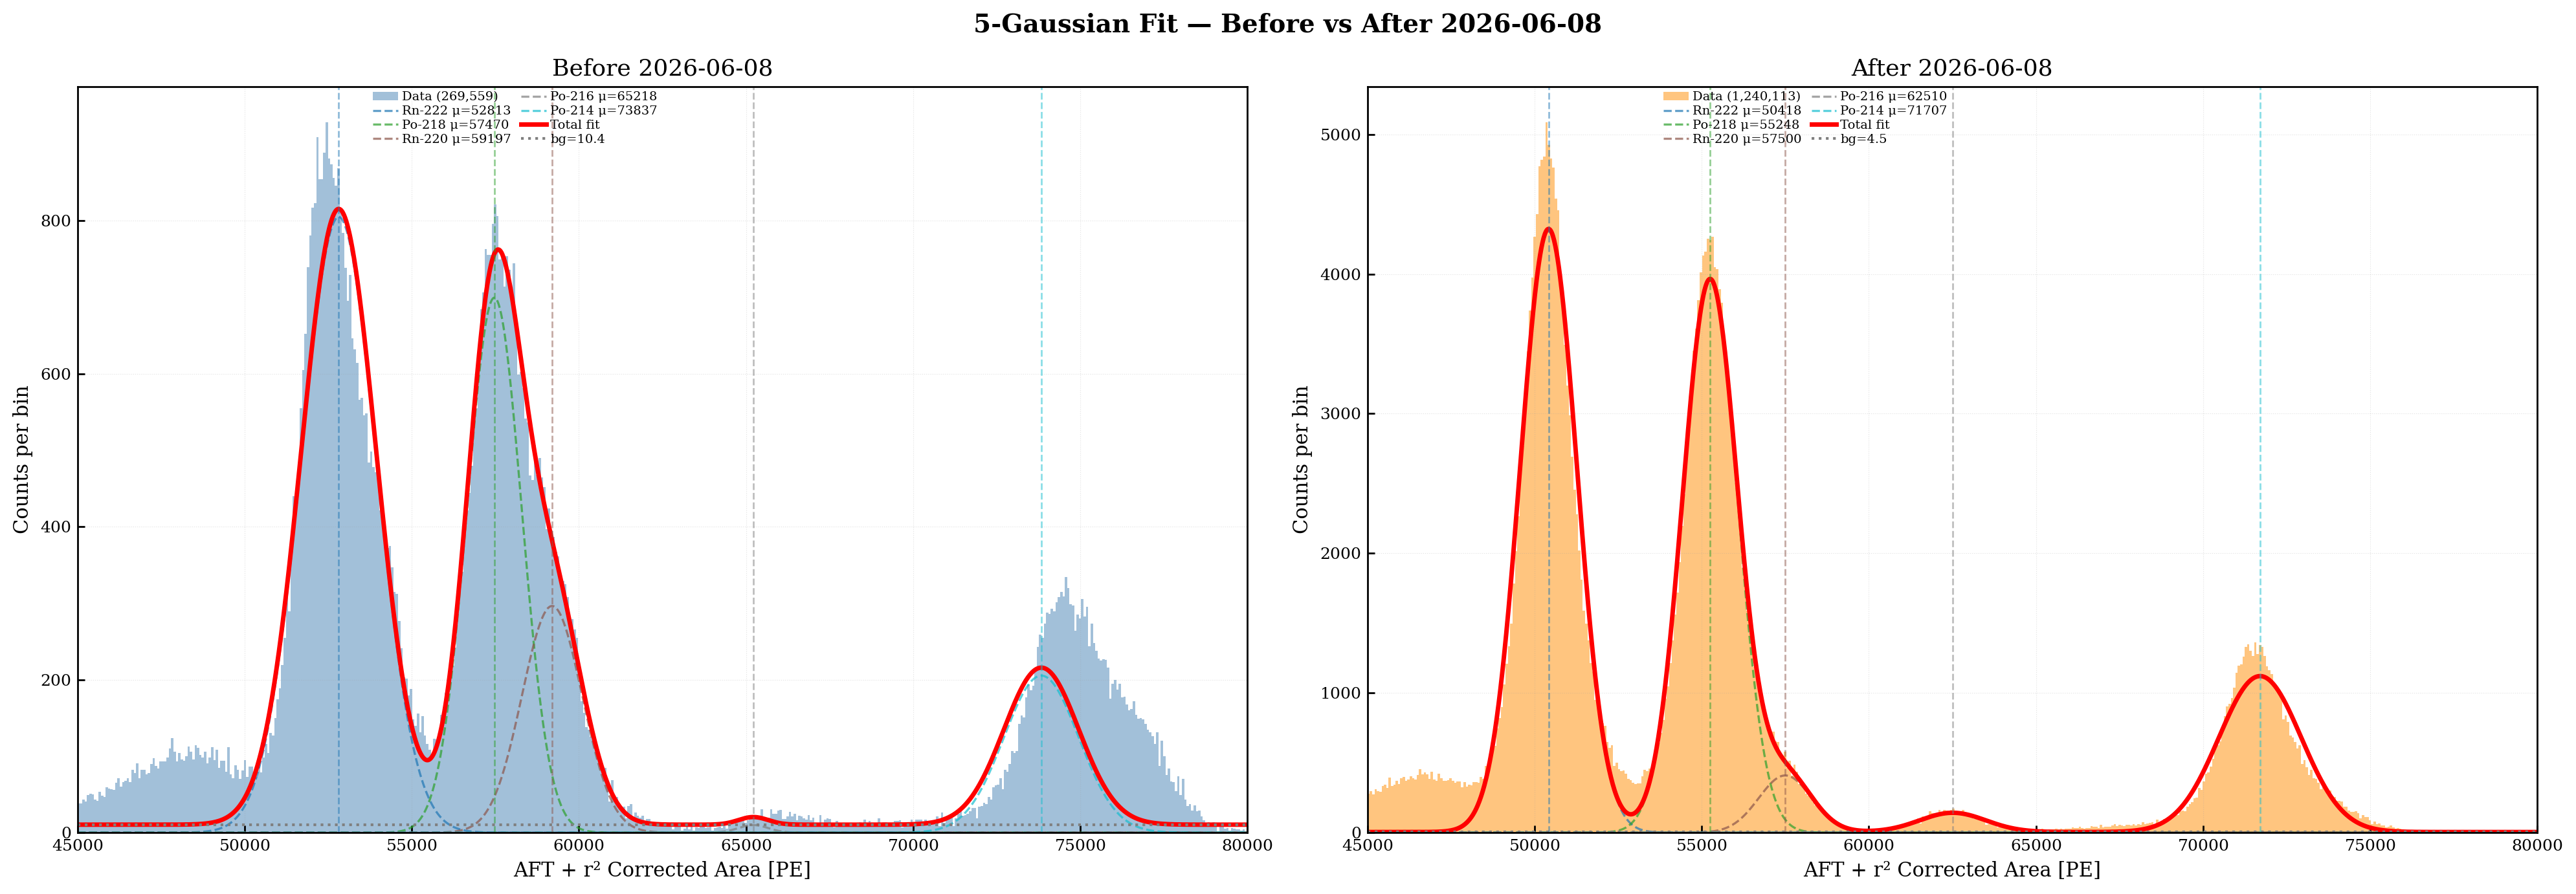


  Rn-222 EVENTS  (±2σ window)
Before 2026-06-08: [50567, 55059] PE  32,196 events  livetime=31.47 d  rate=11.8429 ± 0.0660 mHz
After  2026-06-08: [48719, 52116] PE  125,600 events  livetime=18.27 d  rate=79.5480 ± 0.2245 mHz


In [ ]:
# ═══════════════════════════════════════════════════════════════
# MULTI-GAUSSIAN FIT — before & after cutoff separately
# ═══════════════════════════════════════════════════════════════

def multi_gaussian(x, *params):
    """Sum of N_PEAKS Gaussians + constant background.
    params = [amp0, mu0, sig0, ..., bg]"""
    bg = params[-1]
    result = bg * np.ones_like(x)
    for i in range(N_PEAKS):
        amp = params[3*i]
        mu  = params[3*i + 1]
        sig = params[3*i + 2]
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

def fit_spectrum(events, label, guess_mu, fit_min=50000):
    """Fit multi-Gaussian to binned spectrum. Returns (p_fit, p_err, ok)."""
    counts, edges = np.histogram(events['area_2_corrected'], bins=500, range=[45e3, 80e3])
    centers = 0.5 * (edges[:-1] + edges[1:])

    mask_fit = (centers >= fit_min) & (centers <= 80e3)
    x_fit = centers[mask_fit]
    y_fit = counts[mask_fit]
    y_err = np.sqrt(np.maximum(y_fit, 1))

    p0 = []
    bounds_lower = []
    bounds_upper = []
    for mu0 in guess_mu:
        idx = np.argmin(np.abs(x_fit - mu0))
        amp0 = max(y_fit[idx] * 0.5, 10)
        p0.extend([amp0, mu0, GUESS_SIGMA])
        bounds_lower.extend([0, mu0 - 1000, 200])
        bounds_upper.extend([np.inf, mu0 + 1000, 3000])
    p0.append(1.0)
    bounds_lower.append(0)
    bounds_upper.append(np.inf)

    try:
        p_fit, p_cov = curve_fit(
            multi_gaussian, x_fit, y_fit, p0=p0, sigma=y_err,
            bounds=(bounds_lower, bounds_upper), maxfev=50000
        )
        p_err = np.sqrt(np.diag(p_cov))
        return p_fit, p_err, True
    except Exception as e:
        print(f'  {label} bounded fit failed: {e}')
        try:
            p_fit, p_cov = curve_fit(
                multi_gaussian, x_fit, y_fit, p0=p0, sigma=y_err, maxfev=50000
            )
            p_err = np.sqrt(np.diag(p_cov))
            return p_fit, p_err, True
        except Exception as e2:
            print(f'  {label} unbounded fit also failed: {e2}')
            return None, None, False

# ── Fit range (lower bound to exclude ~48k contaminant) ──
FIT_MIN_BEFORE = 50000
FIT_MIN_AFTER  = 48000

# ── Separate datasets ──
events_before = rn_events[mask_before]
events_after  = rn_events[mask_after]

print(f'Fitting {N_PEAKS} Gaussians + background for before and after {CUTOFF_DATE}...\n')

p_before, p_err_before, ok_before = fit_spectrum(events_before, f'Before {CUTOFF_DATE}', GUESS_MU_BEFORE, FIT_MIN_BEFORE)
p_after,  p_err_after,  ok_after  = fit_spectrum(events_after,  f'After {CUTOFF_DATE}',  GUESS_MU_AFTER,  FIT_MIN_AFTER)

# ── Print fit results ──
for label, p, p_err, ok in [
    (f'BEFORE {CUTOFF_DATE}', p_before, p_err_before, ok_before),
    (f'AFTER  {CUTOFF_DATE}', p_after,  p_err_after,  ok_after),
]:
    if not ok:
        print(f'\n{label}: Fit failed — skipping')
        continue
    print(f'\n{"="*85}')
    print(f'  {label}  —  {N_PEAKS}-GAUSSIAN FIT RESULTS')
    print(f'{"="*85}')
    print(f'{"Peak":10s} {"μ [PE]":>12s} {"σ [PE]":>10s} {"Amplitude":>12s} {"σ/μ":>8s}')
    print(f'{"-"*85}')
    for i in range(N_PEAKS):
        amp, mu, sig = p[3*i], p[3*i+1], p[3*i+2]
        ae, mue, se  = p_err[3*i], p_err[3*i+1], p_err[3*i+2]
        print(f'{PEAK_NAMES[i]:10s}  {mu:8.0f} ± {mue:5.0f}  '
              f'{sig:6.0f} ± {se:4.0f}  '
              f'{amp:8.0f} ± {ae:6.0f}  {100*sig/mu:5.2f}%')
    bg_fit, bg_err = p[-1], p_err[-1]
    print(f'{"bg":10s}  {"—":>12s}  {"—":>10s}  {bg_fit:8.1f} ± {bg_err:6.1f}')
    print(f'{"="*85}')

# ── Side-by-side fit plot ──
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
x_fine = np.linspace(45e3, 80e3, 2000)
peak_colors = plt.cm.tab10(np.linspace(0, 1, N_PEAKS))

for ax, p, p_err, events, label, color, ok in [
    (axes[0], p_before, p_err_before, events_before, f'Before {CUTOFF_DATE}', 'steelblue', ok_before),
    (axes[1], p_after,  p_err_after,  events_after,  f'After {CUTOFF_DATE}',  'darkorange', ok_after),
]:
    ax.hist(events['area_2_corrected'], bins=500, range=[45e3, 80e3],
            color=color, alpha=0.5, label=f'Data ({len(events):,})')
    if ok:
        for i in range(N_PEAKS):
            amp, mu, sig = p[3*i], p[3*i+1], p[3*i+2]
            g = amp * np.exp(-0.5 * ((x_fine - mu) / sig)**2)
            ax.plot(x_fine, g, '--', color=peak_colors[i], lw=1.2, alpha=0.7,
                    label=f'{PEAK_NAMES[i]} μ={mu:.0f}')
        y_total = multi_gaussian(x_fine, *p)
        ax.plot(x_fine, y_total, 'r-', lw=2.5, label='Total fit')
        ax.axhline(y=p[-1], color='gray', ls=':', lw=1.5, label=f'bg={p[-1]:.1f}')
        # Vertical dashed lines at fitted peak positions
        for i in range(N_PEAKS):
            mu_fit = p[3*i + 1]
            ax.axvline(x=mu_fit, color=peak_colors[i], ls='--', lw=1, alpha=0.5)
    ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=11)
    ax.set_ylabel('Counts per bin', fontsize=11)
    ax.set_xlim(45e3, 80e3)
    ax.set_title(label, pad=15, fontsize=13)
    ax.legend(fontsize=7, ncol=2, loc='upper right')
    ax.grid(True, alpha=0.3)

fig.suptitle(f'{N_PEAKS}-Gaussian Fit — Before vs After {CUTOFF_DATE}', fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

# ═══════════════════════════════════════════════════════════════
# Rn-222 COUNTING — ±2σ window
# ═══════════════════════════════════════════════════════════════
N_SIGMA_RN = 2

print(f'\n{"="*75}')
print(f'  Rn-222 EVENTS  (±{N_SIGMA_RN}σ window)')
print(f'{"="*75}')

for label, p, p_err, ok, events in [
    (f'Before {CUTOFF_DATE}', p_before, p_err_before, ok_before, events_before),
    (f'After  {CUTOFF_DATE}', p_after,  p_err_after,  ok_after,  events_after),
]:
    if not ok:
        print(f'{label}: fit failed — cannot count')
        continue
    mu_rn  = p[1]       # Rn-222 is peak index 0
    sig_rn = p[2]
    lo = mu_rn - N_SIGMA_RN * sig_rn
    hi = mu_rn + N_SIGMA_RN * sig_rn
    n_rn = ((events['area_2_corrected'] >= lo) & (events['area_2_corrected'] <= hi)).sum()

    lt_s = (events['time'].max() - events['time'].min()) / 1e9
    lt_d = lt_s / 86400
    rate_mhz = n_rn / lt_s * 1e3
    rate_err_mhz = np.sqrt(n_rn) / lt_s * 1e3

    print(f'{label}: [{lo:.0f}, {hi:.0f}] PE  {n_rn:,} events  '
          f'livetime={lt_d:.2f} d  rate={rate_mhz:.4f} ± {rate_err_mhz:.4f} mHz')
print(f'{"="*75}')


Rn-222      ±2σ  before: [50567, 55059] PE  |  after: [48719, 52116] PE  |  total events: 157,796
Po-218      ±2σ  before: [55833, 59106] PE  |  after: [53603, 56893] PE  |  total events: 137,949
Rn-220      ±2σ  before: [57399, 60996] PE  |  after: [55916, 59085] PE  |  total events: 55,379
Po-216      ±2σ  before: [64330, 66106] PE  |  after: [60528, 64493] PE  |  total events: 5,499
Po-214      ±2σ  before: [71596, 76078] PE  |  after: [69245, 74169] PE  |  total events: 59,605


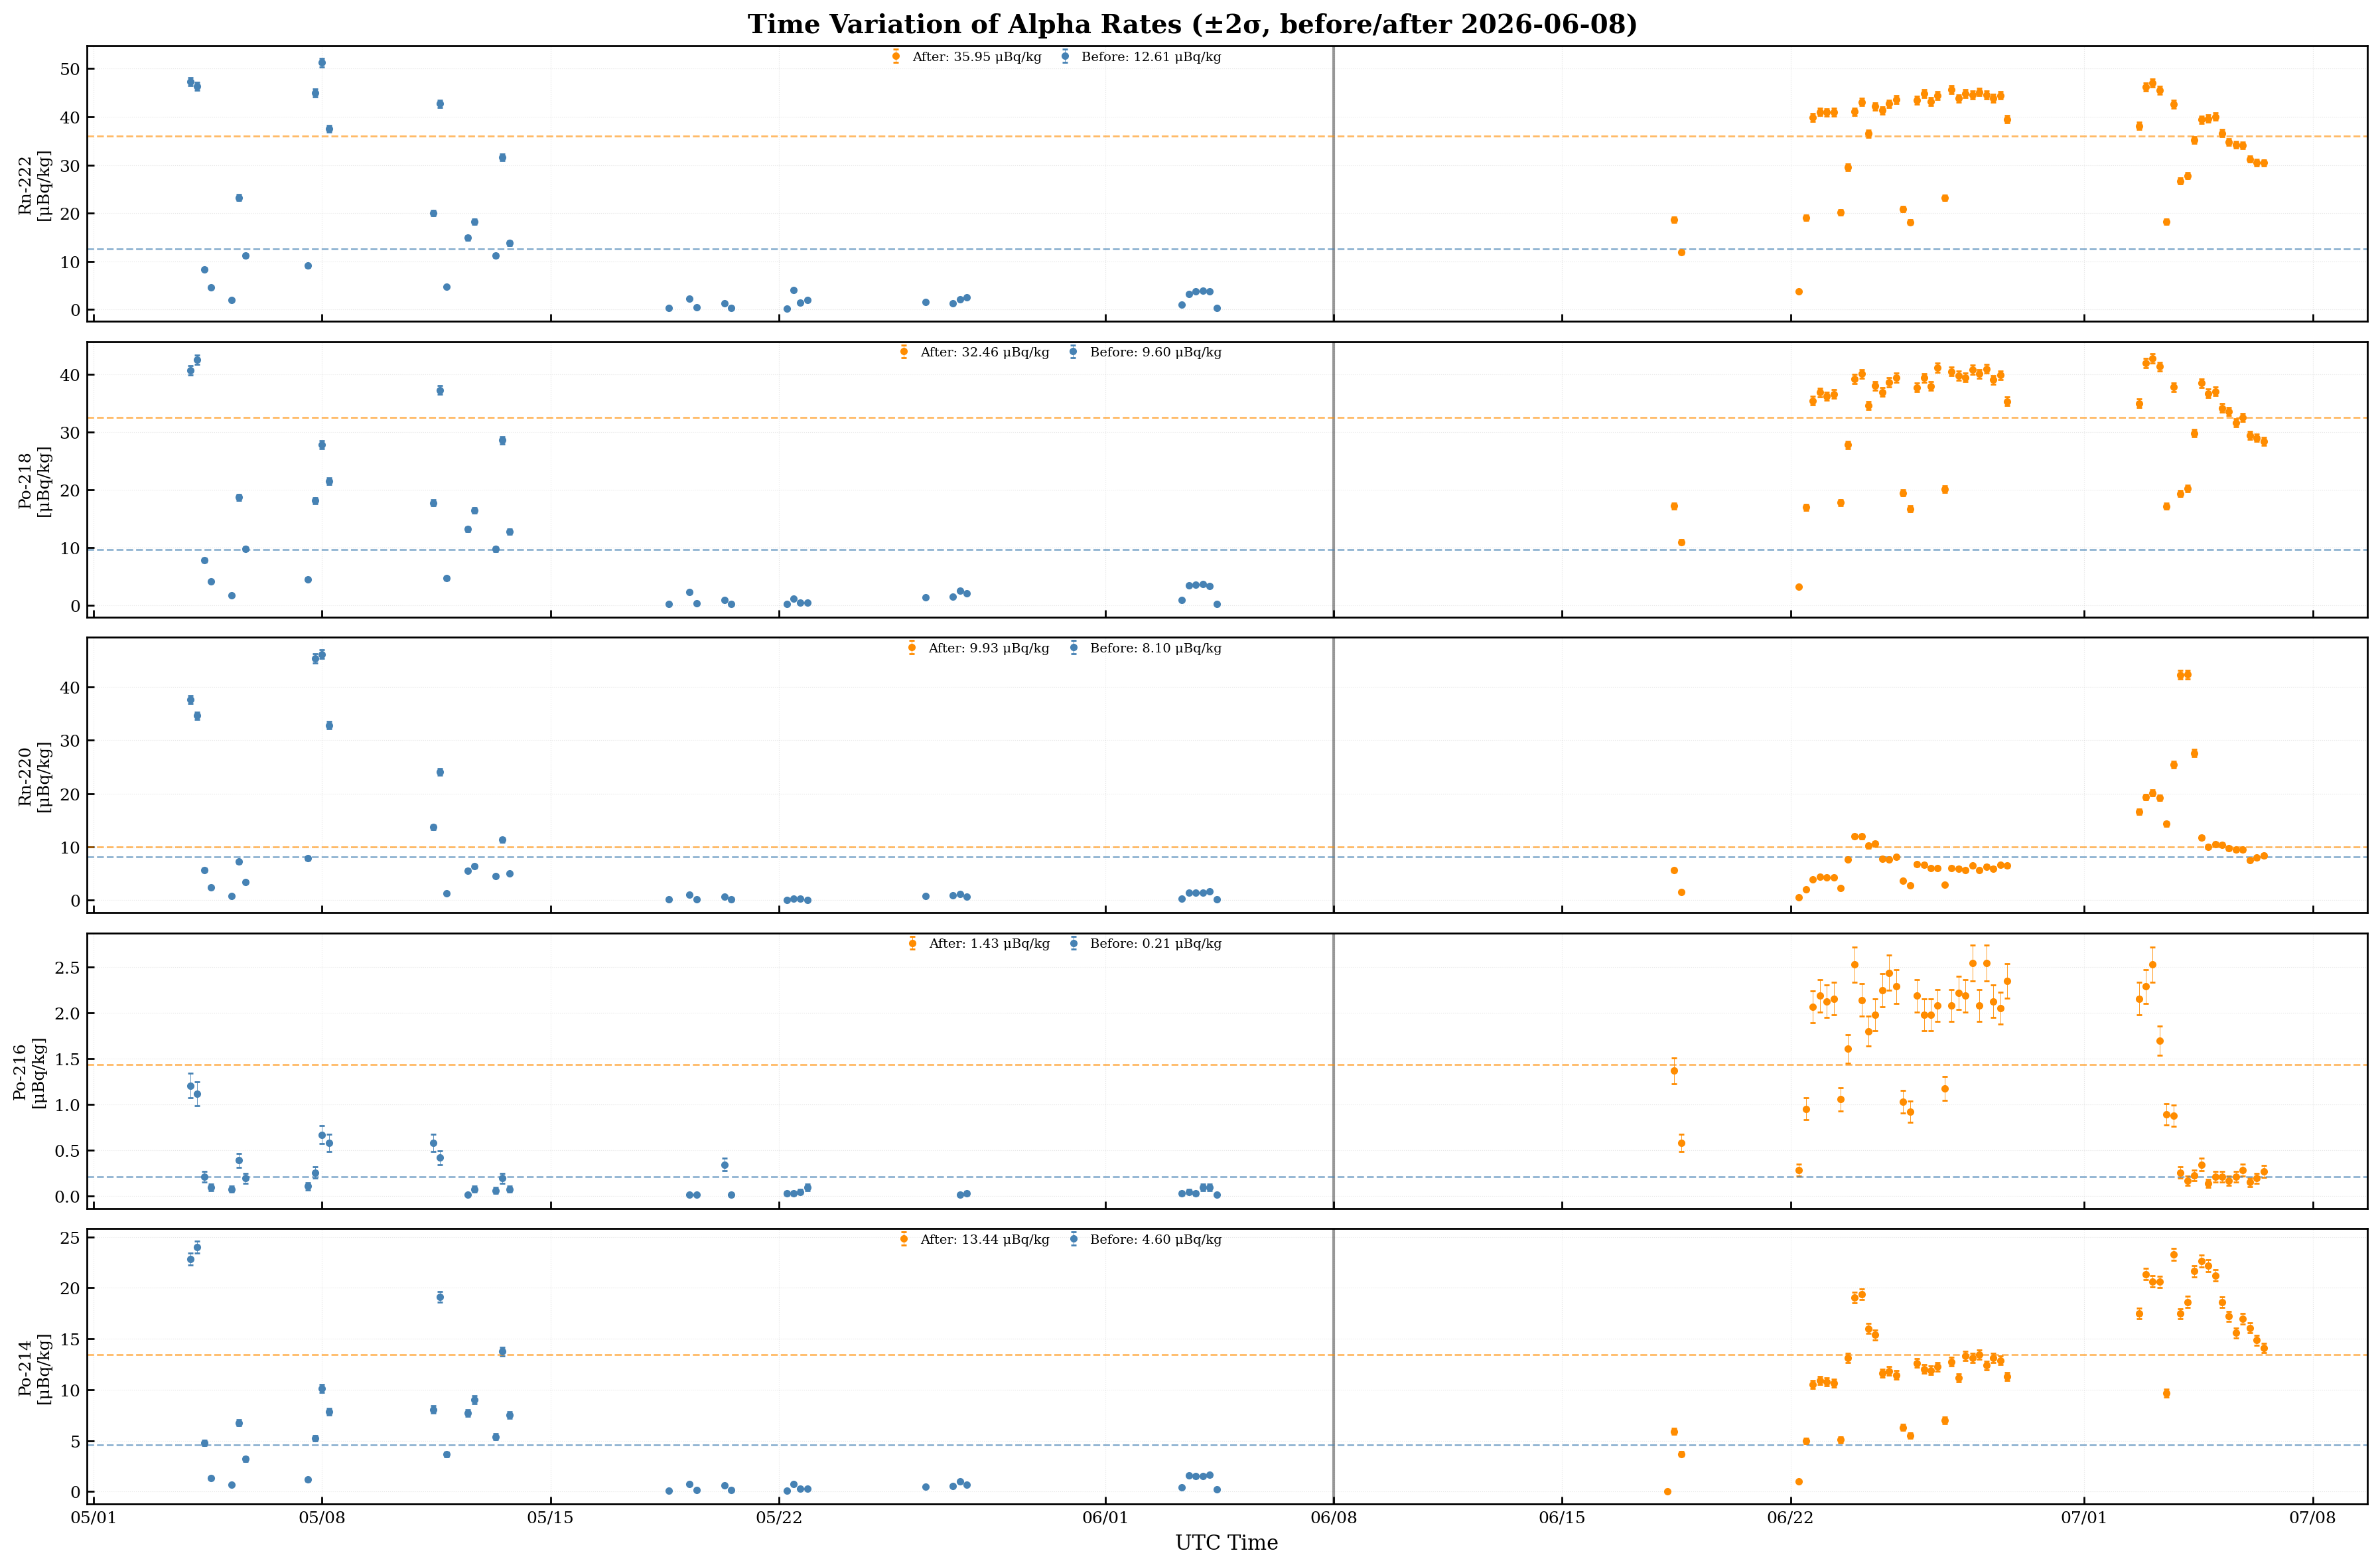


  TIME VARIATION SUMMARY  (±2σ, 300 bins × 5.1 h)
  Time range: 2026-05-03 23:05 → 2026-07-06 11:56 UTC
Isotope        Before mean      After mean   Ratio A/B
-------------------------------------------------------------------------------------
Rn-222           12.61 μBq/kg       35.95 μBq/kg      2.8508
Po-218            9.60 μBq/kg       32.46 μBq/kg      3.3809
Rn-220            8.10 μBq/kg        9.93 μBq/kg      1.2247
Po-216            0.21 μBq/kg        1.43 μBq/kg      6.7596
Po-214            4.60 μBq/kg       13.44 μBq/kg      2.9238


In [ ]:
# ═══════════════════════════════════════════════════════════════
# TIME VARIATION — all isotopes rate vs time (±2σ window)
# ═══════════════════════════════════════════════════════════════
# 5 parallel subplots, before & after on each.

from datetime import datetime, timezone

FMASS = 3660.0       # kg
N_TIME_BINS = 300
N_SIGMA_ISO = 2

if not ok_before or not ok_after:
    print('Skipping time variation — one or both fits failed.')
else:
    # ── Global time range for consistent binning ──
    t_all_ns = rn_events['time'].values
    t_start_ns = t_all_ns.min()
    t_end_ns   = t_all_ns.max()
    time_edges_ns = np.linspace(t_start_ns, t_end_ns, N_TIME_BINS + 1)
    time_centers_ns = 0.5 * (time_edges_ns[:-1] + time_edges_ns[1:])
    bin_width_s = (time_edges_ns[1] - time_edges_ns[0]) / 1e9

    t_centers_dt = [datetime.fromtimestamp(tc / 1e9, tz=timezone.utc)
                    for tc in time_centers_ns]

    def count_per_bin(events, lo, hi, edges):
        mask = ((events['area_2_corrected'] >= lo) & (events['area_2_corrected'] <= hi))
        t_sel = events.loc[mask, 'time'].values
        counts, _ = np.histogram(t_sel, bins=edges)
        return counts

    # ── Compute for all isotopes ──
    results = {}  # results[name] = {rate_before, rate_after, err_before, err_after, lo/lo, ...}

    for i, name in enumerate(PEAK_NAMES):
        # before fit
        mu_b, sig_b = p_before[3*i + 1], p_before[3*i + 2]
        lo_b = mu_b - N_SIGMA_ISO * sig_b
        hi_b = mu_b + N_SIGMA_ISO * sig_b

        # after fit
        mu_a, sig_a = p_after[3*i + 1], p_after[3*i + 2]
        lo_a = mu_a - N_SIGMA_ISO * sig_a
        hi_a = mu_a + N_SIGMA_ISO * sig_a

        c_b = count_per_bin(events_before, lo_b, hi_b, time_edges_ns)
        c_a = count_per_bin(events_after,  lo_a, hi_a, time_edges_ns)

        results[name] = {
            'rate_before': c_b / (bin_width_s * FMASS) * 1e6,
            'rate_after':  c_a / (bin_width_s * FMASS) * 1e6,
            'err_before':  np.sqrt(np.maximum(c_b, 1)) / (bin_width_s * FMASS) * 1e6,
            'err_after':   np.sqrt(np.maximum(c_a, 1)) / (bin_width_s * FMASS) * 1e6,
            'lo_before': lo_b, 'hi_before': hi_b,
            'lo_after':  lo_a, 'hi_after':  hi_a,
        }

        n_total = ((events_before['area_2_corrected'] >= lo_b) & (events_before['area_2_corrected'] <= hi_b)).sum() + \
                  ((events_after['area_2_corrected']  >= lo_a) & (events_after['area_2_corrected'] <= hi_a)).sum()
        print(f'{name:10s}  ±{N_SIGMA_ISO}σ  before: [{lo_b:.0f}, {hi_b:.0f}] PE  |  '
              f'after: [{lo_a:.0f}, {hi_a:.0f}] PE  |  total events: {n_total:,}')

    # ═══════════════════════════════════════════════════════════
    # 5 parallel subplots
    # ═══════════════════════════════════════════════════════════
    import matplotlib.dates as mdates

    fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.4 * N_PEAKS), sharex=True)

    for ax, name in zip(axes, PEAK_NAMES):
        r = results[name]
        r_b, r_a = r['rate_before'], r['rate_after']
        e_b, e_a = r['err_before'], r['err_after']

        # Cutoff line
        ax.axvline(x=datetime.fromtimestamp(boundary_ns/1e9, tz=timezone.utc),
                   color='black', ls='-', lw=1.5, alpha=0.4)

        # Mean values (compute first for legend labels)
        nz_b = r_b > 0
        nz_a = r_a > 0
        mean_b = r_b[nz_b].mean()
        mean_a = r_a[nz_a].mean()

        # After (behind)
        ax.errorbar(np.array(t_centers_dt)[nz_a], r_a[nz_a], yerr=e_a[nz_a],
                    fmt='o', color='darkorange', markersize=3, capsize=1.5, lw=0.3,
                    label=f'After: {mean_a:.2f} μBq/kg')

        # Before (on top)
        ax.errorbar(np.array(t_centers_dt)[nz_b], r_b[nz_b], yerr=e_b[nz_b],
                    fmt='o', color='steelblue', markersize=3, capsize=1.5, lw=0.3,
                    label=f'Before: {mean_b:.2f} μBq/kg')

        # Mean lines
        ax.axhline(y=mean_b, color='steelblue', ls='--', lw=1, alpha=0.6)
        ax.axhline(y=mean_a, color='darkorange', ls='--', lw=1, alpha=0.6)

        ax.set_ylabel(f'{name}\n[μBq/kg]', fontsize=9)
        ax.legend(fontsize=7, loc='upper right', ncol=2)
        ax.grid(True, alpha=0.25)

    # X-axis formatting on bottom subplot
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
    axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
    axes[-1].set_xlabel('UTC Time', fontsize=11)
    fig.autofmt_xdate(rotation=0, ha='center')

    fig.suptitle(f'Time Variation of Alpha Rates (±{N_SIGMA_ISO}σ, before/after {CUTOFF_DATE})',
                 fontsize=14, fontweight='bold')
    safe_tight(fig)
    plt.show()

    # ── Summary table ──
    print(f'\n{"="*85}')
    print(f'  TIME VARIATION SUMMARY  (±{N_SIGMA_ISO}σ, {N_TIME_BINS} bins × {bin_width_s/3600:.1f} h)')
    print(f'  Time range: {t_centers_dt[0].strftime("%Y-%m-%d %H:%M")} → '
          f'{t_centers_dt[-1].strftime("%Y-%m-%d %H:%M")} UTC')
    print(f'{"="*85}')
    print(f'{"Isotope":10s}  {"Before mean":>14s}  {"After mean":>14s}  {"Ratio A/B":>10s}')
    print(f'{"-"*85}')
    for name in PEAK_NAMES:
        r = results[name]
        mb = r['rate_before'][r['rate_before'] > 0].mean()
        ma = r['rate_after'][r['rate_after'] > 0].mean()
        ratio = ma / mb if mb > 0 else float('nan')
        print(f'{name:10s}  {mb:10.2f} μBq/kg  {ma:10.2f} μBq/kg  {ratio:10.4f}')
    print(f'{"="*85}')


Provides of multi-output plugins overlap, deregister old plugins <class 'straxen.plugins.merged_s2s.merged_s2s.MergedS2s'>.


You specified _auto_append_rucio_local=True and you are not on dali compute nodes, so we will add the following rucio local path: /project/lgrandi/rucio/


Checking data availability:   0%|          | 0/2 [00:00<?, ?it/s]

Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin
Option diffusion_constant not taken by any registered plugin
Option som_files not taken by any registered plugin


Loaded 675 runs
After filtering runs >= 2026-05-01: 580 runs
Saved 2900 rows (580 runs × 5 isotopes) → /project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_rn_rates_0707.csv


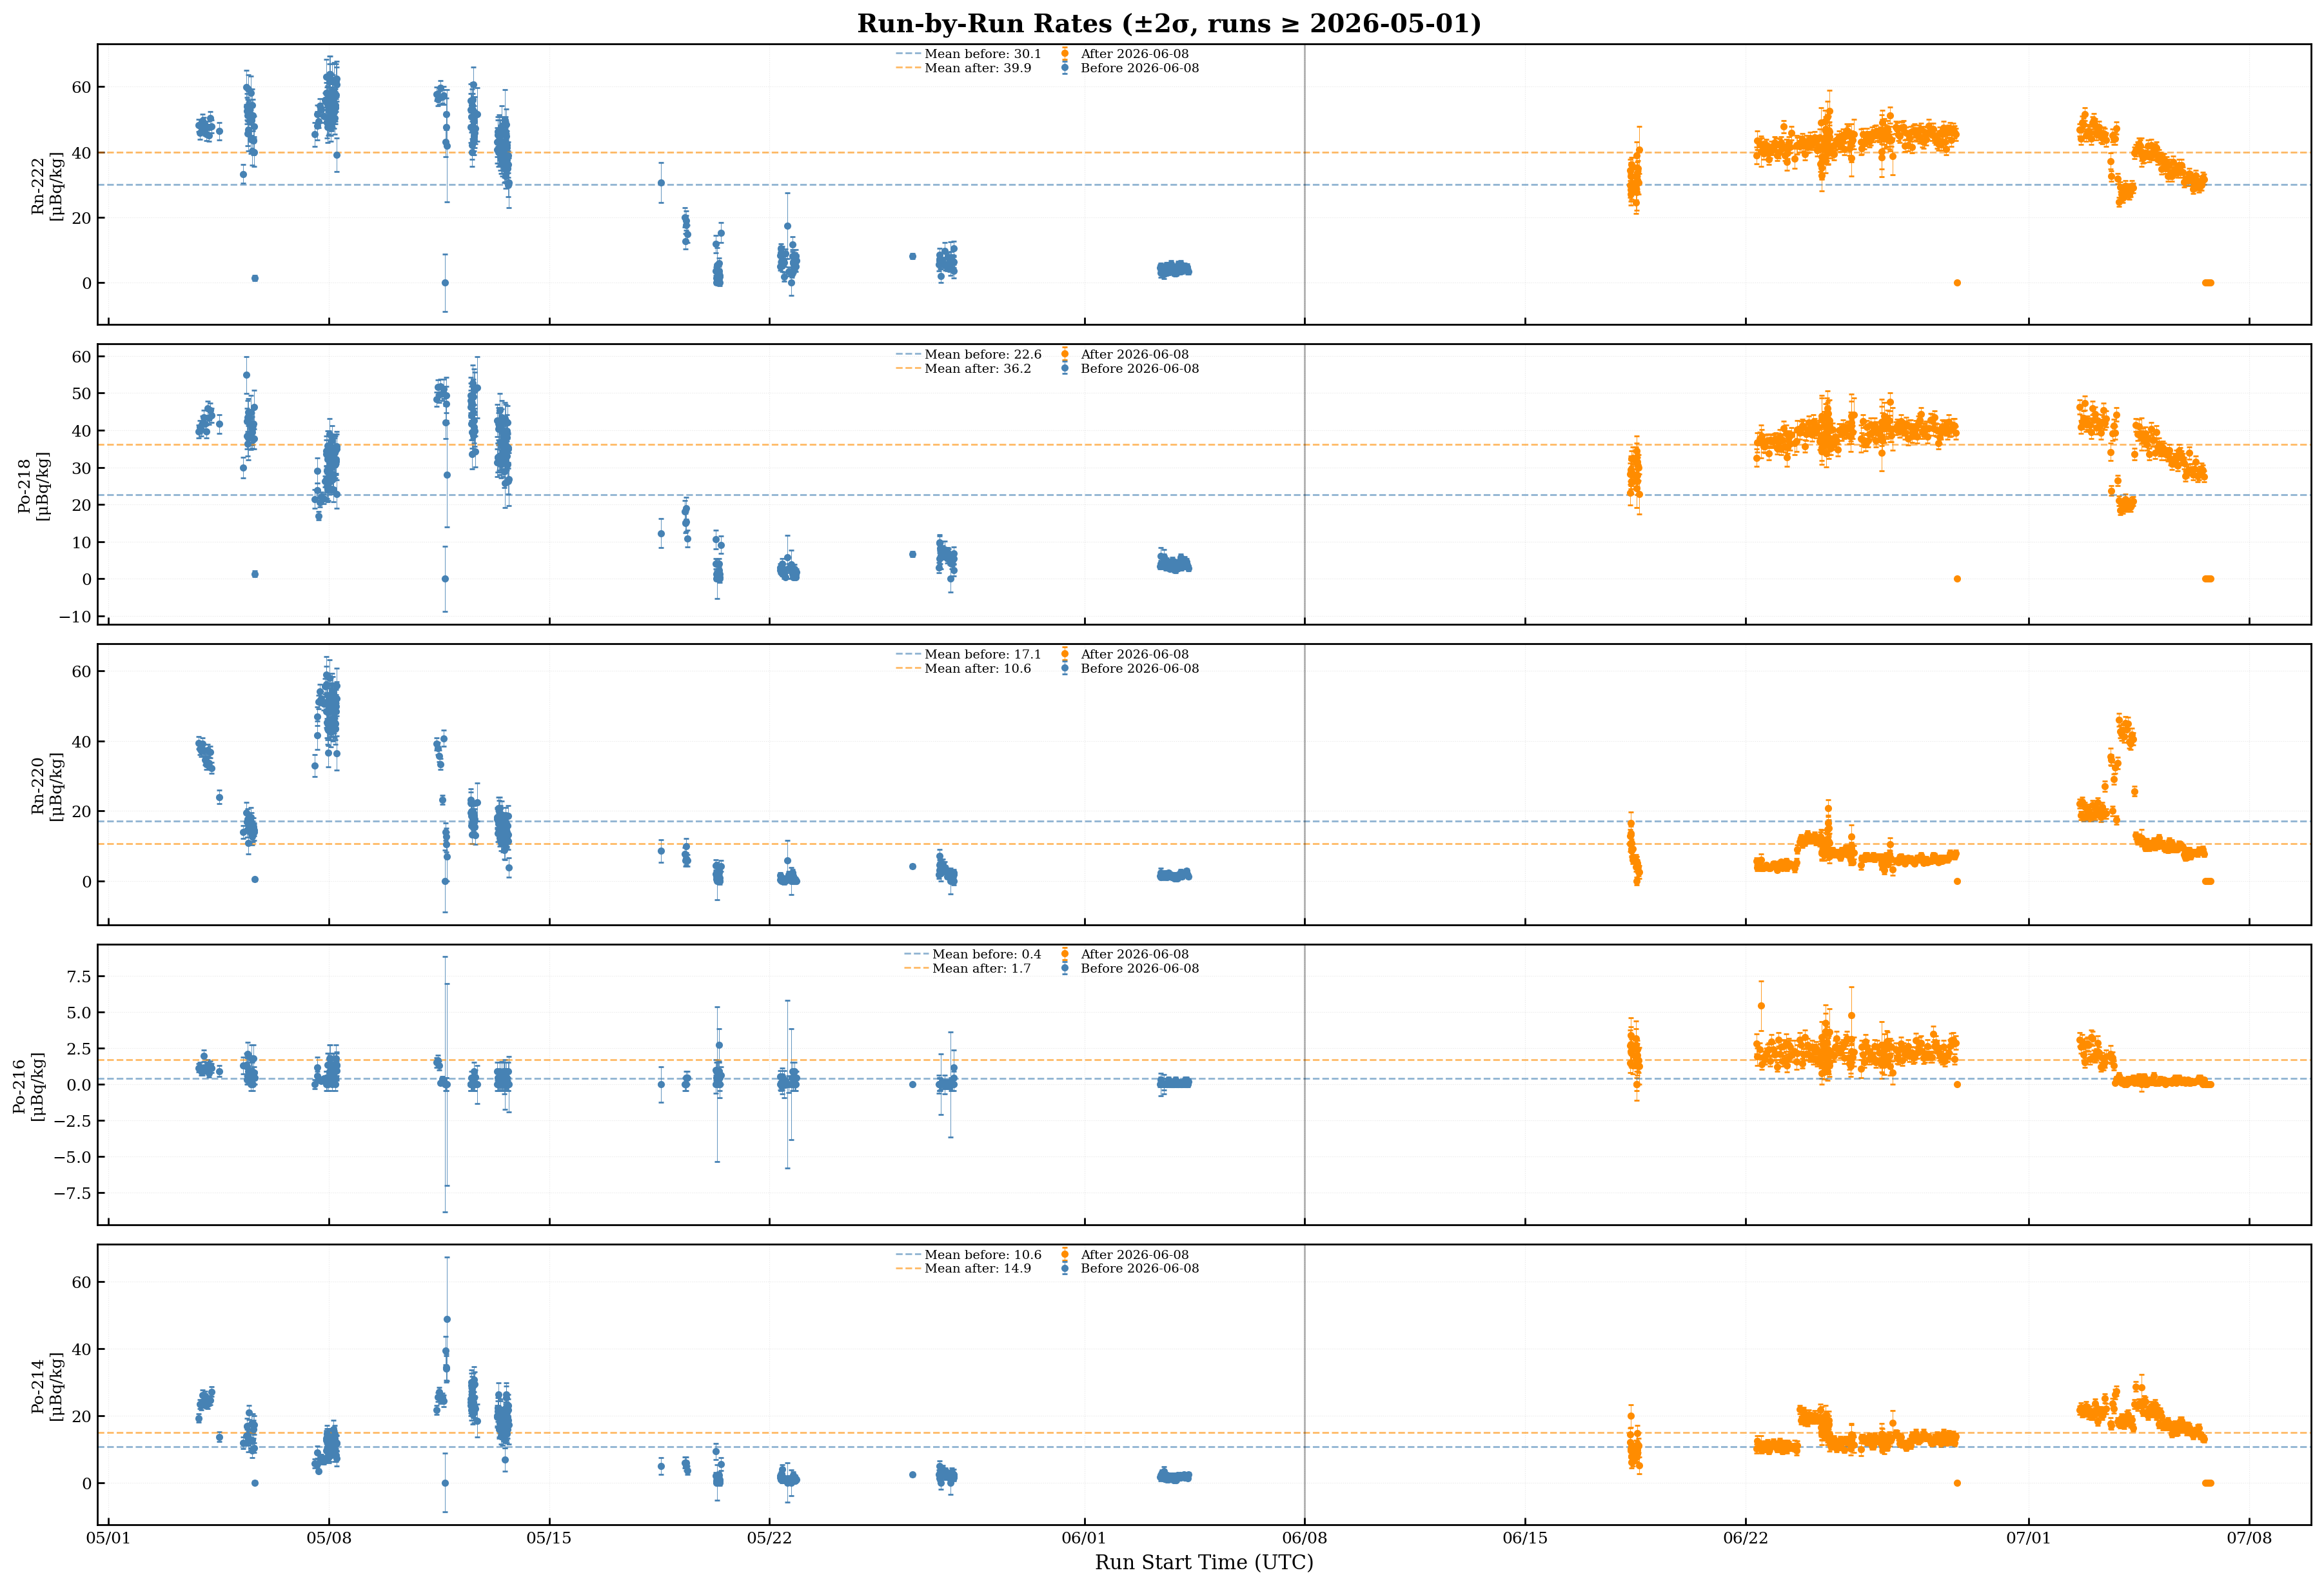


  RUN-BY-RUN RATE SUMMARY  (±2σ, 580 runs ≥ 2026-05-01)
  Rn-222     before: 283 runs  32,171 events  livetime=3.4 d  mean=30.1 ± 22.2 μBq/kg
  Rn-222     after : 297 runs  125,579 events  livetime=9.9 d  mean=39.9 ± 8.2 μBq/kg
  Po-218     before: 283 runs  24,506 events  livetime=3.4 d  mean=22.6 ± 17.4 μBq/kg
  Po-218     after : 297 runs  113,414 events  livetime=9.9 d  mean=36.2 ± 7.8 μBq/kg
  Rn-220     before: 283 runs  20,687 events  livetime=3.4 d  mean=17.1 ± 18.1 μBq/kg
  Rn-220     after : 297 runs  34,680 events  livetime=9.9 d  mean=10.6 ± 8.6 μBq/kg
  Po-216     before: 283 runs     485 events  livetime=3.4 d  mean=0.4 ± 0.5 μBq/kg
  Po-216     after : 297 runs   5,013 events  livetime=9.9 d  mean=1.7 ± 1.1 μBq/kg
  Po-214     before: 283 runs  11,729 events  livetime=3.4 d  mean=10.6 ± 9.5 μBq/kg
  Po-214     after : 297 runs  47,859 events  livetime=9.9 d  mean=14.9 ± 4.8 μBq/kg


In [ ]:
# ═══════════════════════════════════════════════════════════════
# RUN-BY-RUN FIT + RATE — ALL 5 ISOTOPES (per-run multi-Gaussian)
# ═══════════════════════════════════════════════════════════════
# Instead of using the global before/after fit for all runs,
# fit each run individually to catch spectrum shifts.
# Falls back to global fit if per-run fit fails (low stats).

# ── Get run list ──
import cutax
import strax
import straxen

st = straxen.contexts.xenonnt_online(
    output_folder='/scratch/midway3/jietang/strax_data'
)
st.storage.append(
    strax.DataDirectory('/project/lgrandi-shared/commissioning/', readonly=True)
)

runs_sr3 = st.select_runs(
    run_mode='tpc_bkg',
    exclude_tags=['abandon', 'messy', 'timing_issue', 's1_only'],
    available=('peak_basics'),
)

print(f'Loaded {len(runs_sr3)} runs')

# ── Select runs after MIN_RUN_DATE ──
MIN_RUN_DATE = '2026-05-01'
min_run_s = pd.Timestamp(MIN_RUN_DATE, tz='UTC').timestamp()
runs_sr3['start_s'] = runs_sr3['start'].apply(lambda x: x.timestamp())
runs_sr3 = runs_sr3[runs_sr3['start_s'] >= min_run_s].copy()
print(f'After filtering runs >= {MIN_RUN_DATE}: {len(runs_sr3)} runs')

# ── Parameters ──
N_SIGMA_RUN = 2
FMASS = 3660.0  # kg
cutoff_s = np.datetime64(CUTOFF_DATE).astype('datetime64[s]').astype('int64')

# ── Per-run fitting function ──
def fit_run_spectrum(events, guess_mu, fit_min, label=''):
    """Fit multi-Gaussian to a single run's spectrum.

    Returns (p_fit, ok, status).
    status: 'success_tight', 'success_medium', 'success_wide',
            'fallback_global', 'too_few_events', 'fit_failed'
    """
    n_ev = len(events)
    if n_ev < 50:
        return None, False, f'too_few_events({n_ev})'

    # Adaptive binning — fewer bins for low-stat runs
    n_bins = min(300, max(80, n_ev // 5))

    counts, edges = np.histogram(
        events['area_2_corrected'], bins=n_bins, range=[45e3, 80e3]
    )
    centers = 0.5 * (edges[:-1] + edges[1:])

    mask_fit = (centers >= fit_min) & (centers <= 80e3)
    x_fit = centers[mask_fit]
    y_fit = counts[mask_fit]
    y_err = np.sqrt(np.maximum(y_fit, 1))

    # Try progressively wider mu bounds
    for width, tag in [(400, 'tight'), (700, 'medium'), (1200, 'wide')]:
        p0 = []
        bounds_lower = []
        bounds_upper = []
        for mu0 in guess_mu:
            idx = np.argmin(np.abs(x_fit - mu0))
            amp0 = max(y_fit[idx] * 0.4, 3)
            p0.extend([amp0, mu0, GUESS_SIGMA])
            bounds_lower.extend([0, mu0 - width, 100])
            bounds_upper.extend([np.inf, mu0 + width, 3500])
        p0.append(1.0)           # background initial
        bounds_lower.append(0)
        bounds_upper.append(np.inf)

        try:
            p_fit, p_cov = curve_fit(
                multi_gaussian, x_fit, y_fit, p0=p0, sigma=y_err,
                bounds=(bounds_lower, bounds_upper), maxfev=30000
            )
            # Sanity checks — reject if any mu hit the bound or sigma is crazy
            ok_sane = True
            for i in range(N_PEAKS):
                mu_f  = p_fit[3*i + 1]
                sig_f = p_fit[3*i + 2]
                if abs(mu_f - guess_mu[i]) > width * 0.95:
                    ok_sane = False
                if sig_f < 50 or sig_f > 4000:
                    ok_sane = False
            if ok_sane:
                return p_fit, True, f'success_{tag}'
        except Exception:
            continue

    return None, False, 'fit_failed'


# ── Main loop: per-run fit + counting ──
results_run = []
fit_stats = {'success_tight': 0, 'success_medium': 0, 'success_wide': 0,
             'fallback_global': 0, 'too_few_events': 0, 'fit_failed': 0}
overlap_runs = []  # runs where Po-218/Rn-220 ±2σ windows overlap

n_total = len(runs_sr3)
for idx, (_, run) in enumerate(runs_sr3.iterrows()):
    run_name   = run['name']
    run_start  = run['start_s']
    run_end    = float(run['end'].timestamp())
    livetime_s = run.get('duration', run_end - run_start)

    # ── Event selection ──
    t0_ns = int(run_start * 1e9)
    t1_ns = int(run_end   * 1e9)
    mask_run = (rn_events['time'] >= t0_ns) & (rn_events['time'] < t1_ns)
    events_run = rn_events[mask_run]

    # ── Determine period + initial guesses ──
    if run_start < cutoff_s:
        guess_mu = GUESS_MU_BEFORE
        fit_min  = 50000
        p_global = p_before
        period   = 'before'
    else:
        guess_mu = GUESS_MU_AFTER
        fit_min  = 48000
        p_global = p_after
        period   = 'after'

    # ── Per-run fit (with fallback to global) ──
    p_fit, ok_fit, status = fit_run_spectrum(
        events_run, guess_mu, fit_min, label=run_name
    )

    if not ok_fit:
        # Fall back to global fit
        if p_global is not None:
            p_fit = p_global
            status = 'fallback_global'
        else:
            # No global fit either — skip this run
            continue

    fit_stats[status] = fit_stats.get(status, 0) + 1

    # ── Overlap check: Po-218 (idx 1) vs Rn-220 (idx 2) ──
    mu_po218  = p_fit[3*1 + 1]
    sig_po218 = p_fit[3*1 + 2]
    mu_rn220  = p_fit[3*2 + 1]
    sig_rn220 = p_fit[3*2 + 2]

    overlap_po218_rn220 = (mu_po218 + N_SIGMA_RUN * sig_po218) > (mu_rn220 - N_SIGMA_RUN * sig_rn220)
    if overlap_po218_rn220:
        overlap_runs.append(run_name)

    # ── Count events for each isotope ──
    for i, name in enumerate(PEAK_NAMES):
        mu  = p_fit[3*i + 1]
        sig = p_fit[3*i + 2]
        lo = mu - N_SIGMA_RUN * sig
        hi = mu + N_SIGMA_RUN * sig

        mask_iso = ((events_run['area_2_corrected'] >= lo) &
                    (events_run['area_2_corrected'] <= hi))
        n = mask_iso.sum()

        rate     = n / livetime_s * 1e6 / FMASS          # μBq/kg
        rate_err = np.sqrt(max(n, 1)) / livetime_s * 1e6 / FMASS

        results_run.append({
            'run':           run_name,
            'start_s':       run_start,
            'end_s':         run_end,
            'livetime_s':    livetime_s,
            'isotope':       name,
            'n_events':      n,
            'rate_ukgb':     rate,
            'rate_err_ukgb': rate_err,
            'period':        period,
            'fit_status':    status,
            'fit_mu':        mu,
            'fit_sigma':     sig,
            'overlap_warn':  (name in ['Po-218', 'Rn-220']) and overlap_po218_rn220,
        })

    # Progress
    if (idx + 1) % 20 == 0 or idx == 0:
        print(f'  [{idx+1}/{n_total}] {run_name}  {len(events_run)} evts  '
              f'fit: {status}  Po-218/Rn-220 overlap: {overlap_po218_rn220}')

df_rates = pd.DataFrame(results_run)

# ── Fit status summary ──
print(f'\n{"="*60}')
print(f'  PER-RUN FIT STATUS')
print(f'{"="*60}')
for k, v in fit_stats.items():
    if v > 0:
        print(f'  {k:20s}: {v:4d} runs')
print(f'{"="*60}')

# ── Overlap report ──
print(f'\n{"="*60}')
print(f'  Po-218 / Rn-220 ±{N_SIGMA_RUN}σ OVERLAP CHECK')
print(f'{"="*60}')
if overlap_runs:
    print(f'  ⚠ OVERLAPPING in {len(overlap_runs)}/{n_total} runs — '
          f'events may be double-counted!')
    print(f'  Run list: {", ".join(overlap_runs[:20])}')
    if len(overlap_runs) > 20:
        print(f'  ... and {len(overlap_runs) - 20} more')
else:
    print(f'  ✓ No overlap detected — all runs OK')
print(f'{"="*60}')

# ── Save ──
outpath = '/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_rn_rates_0707.csv'

df_rates.to_csv(outpath, index=False)
print(f'\nSaved {len(df_rates)} rows ({len(runs_sr3)} runs × {N_PEAKS} isotopes) → {outpath}')

# ── 5-panel plot, one per isotope ──
from datetime import datetime, timezone

fig, axes = plt.subplots(N_PEAKS, 1, figsize=(18, 2.5 * N_PEAKS), sharex=True)

for ax, name in zip(axes, PEAK_NAMES):
    df_iso = df_rates[df_rates['isotope'] == name]

    mask_b = df_iso['period'] == 'before'
    mask_a = df_iso['period'] == 'after'

    start_dt = [datetime.fromtimestamp(s, tz=timezone.utc) for s in df_iso['start_s']]

    # Points with per-run fit (circle) vs fallback (cross)
    mask_fit_ok = df_iso['fit_status'].str.startswith('success')
    mask_fb     = ~mask_fit_ok

    # After — per-run fit OK
    nz = mask_a & mask_fit_ok & (df_iso['rate_ukgb'] > 0)
    if nz.sum() > 0:
        ax.errorbar(np.array(start_dt)[nz], df_iso.loc[nz, 'rate_ukgb'].values,
                    yerr=df_iso.loc[nz, 'rate_err_ukgb'].values,
                    fmt='o', color='darkorange', markersize=3.5, capsize=1.5, lw=0.3,
                    label=f'After {CUTOFF_DATE} (fit ok)')
    # After — fallback
    nz_fb = mask_a & mask_fb & (df_iso['rate_ukgb'] > 0)
    if nz_fb.sum() > 0:
        ax.errorbar(np.array(start_dt)[nz_fb], df_iso.loc[nz_fb, 'rate_ukgb'].values,
                    yerr=df_iso.loc[nz_fb, 'rate_err_ukgb'].values,
                    fmt='x', color='darkorange', markersize=4, capsize=1.5, lw=0.3, alpha=0.5)

    # Before — per-run fit OK
    nz = mask_b & mask_fit_ok & (df_iso['rate_ukgb'] > 0)
    if nz.sum() > 0:
        ax.errorbar(np.array(start_dt)[nz], df_iso.loc[nz, 'rate_ukgb'].values,
                    yerr=df_iso.loc[nz, 'rate_err_ukgb'].values,
                    fmt='o', color='steelblue', markersize=3.5, capsize=1.5, lw=0.3,
                    label=f'Before {CUTOFF_DATE} (fit ok)')
    # Before — fallback
    nz_fb = mask_b & mask_fb & (df_iso['rate_ukgb'] > 0)
    if nz_fb.sum() > 0:
        ax.errorbar(np.array(start_dt)[nz_fb], df_iso.loc[nz_fb, 'rate_ukgb'].values,
                    yerr=df_iso.loc[nz_fb, 'rate_err_ukgb'].values,
                    fmt='x', color='steelblue', markersize=4, capsize=1.5, lw=0.3, alpha=0.5)

    # Mean lines
    all_b = mask_b & (df_iso['rate_ukgb'] > 0)
    all_a = mask_a & (df_iso['rate_ukgb'] > 0)
    if all_b.sum() > 0:
        mb = df_iso.loc[all_b, 'rate_ukgb'].mean()
        ax.axhline(y=mb, color='steelblue', ls='--', lw=1.2, alpha=0.6,
                   label=f'Mean before: {mb:.1f} μBq/kg')
    if all_a.sum() > 0:
        ma = df_iso.loc[all_a, 'rate_ukgb'].mean()
        ax.axhline(y=ma, color='darkorange', ls='--', lw=1.2, alpha=0.6,
                   label=f'Mean after: {ma:.1f} μBq/kg')

    # Overlap warning annotation on Po-218 and Rn-220 panels
    if name in ['Po-218', 'Rn-220'] and overlap_runs:
        ax.text(0.98, 0.92, f'⚠ Overlap in {len(overlap_runs)} runs',
                transform=ax.transAxes, fontsize=7, color='red',
                ha='right', va='top', fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))

    # Cutoff line
    cutoff_dt = datetime.fromtimestamp(cutoff_s, tz=timezone.utc)
    ax.axvline(x=cutoff_dt, color='black', ls='-', lw=1, alpha=0.3)

    ax.set_ylabel(f'{name}\n[μBq/kg]', fontsize=9)
    ax.legend(fontsize=6.5, loc='upper right', ncol=2)
    ax.grid(True, alpha=0.25)

import matplotlib.dates as mdates
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('Run Start Time (UTC)', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle(f'Run-by-Run Rates with Per-Run Fit  (±{N_SIGMA_RUN}σ, runs ≥ {MIN_RUN_DATE})',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

# ── Summary ──
print(f'\n{"="*80}')
print(f'  RUN-BY-RUN RATE SUMMARY  (±{N_SIGMA_RUN}σ, {len(runs_sr3)} runs ≥ {MIN_RUN_DATE})')
print(f'{"="*80}')
print(f'{"Isotope":10s}  {"Period":7s}  {"Runs":>5s}  {"Events":>8s}  {"Livetime":>10s}  {"Mean":>10s}  {"Std":>10s}')
print(f'{"-"*80}')
for name in PEAK_NAMES:
    df_iso = df_rates[df_rates['isotope'] == name]
    for period in ['before', 'after']:
        df_p = df_iso[df_iso['period'] == period]
        if len(df_p) == 0:
            continue
        total_ev = df_p['n_events'].sum()
        total_lt = df_p['livetime_s'].sum()
        print(f'  {name:10s}  {period:7s}  {len(df_p):5d}  {total_ev:8,}  '
              f'{total_lt/86400:8.1f} d  '
              f'{df_p["rate_ukgb"].mean():8.1f}  {df_p["rate_ukgb"].std():8.1f}  μBq/kg')
print(f'{"="*80}')


Merged: 1875 S1-only + 2900 S1+S2 = 4775 rows
Saved → /project2/lgrandi/jietang/sr3_commissioning/sr3_full_rn_rates_0707.csv


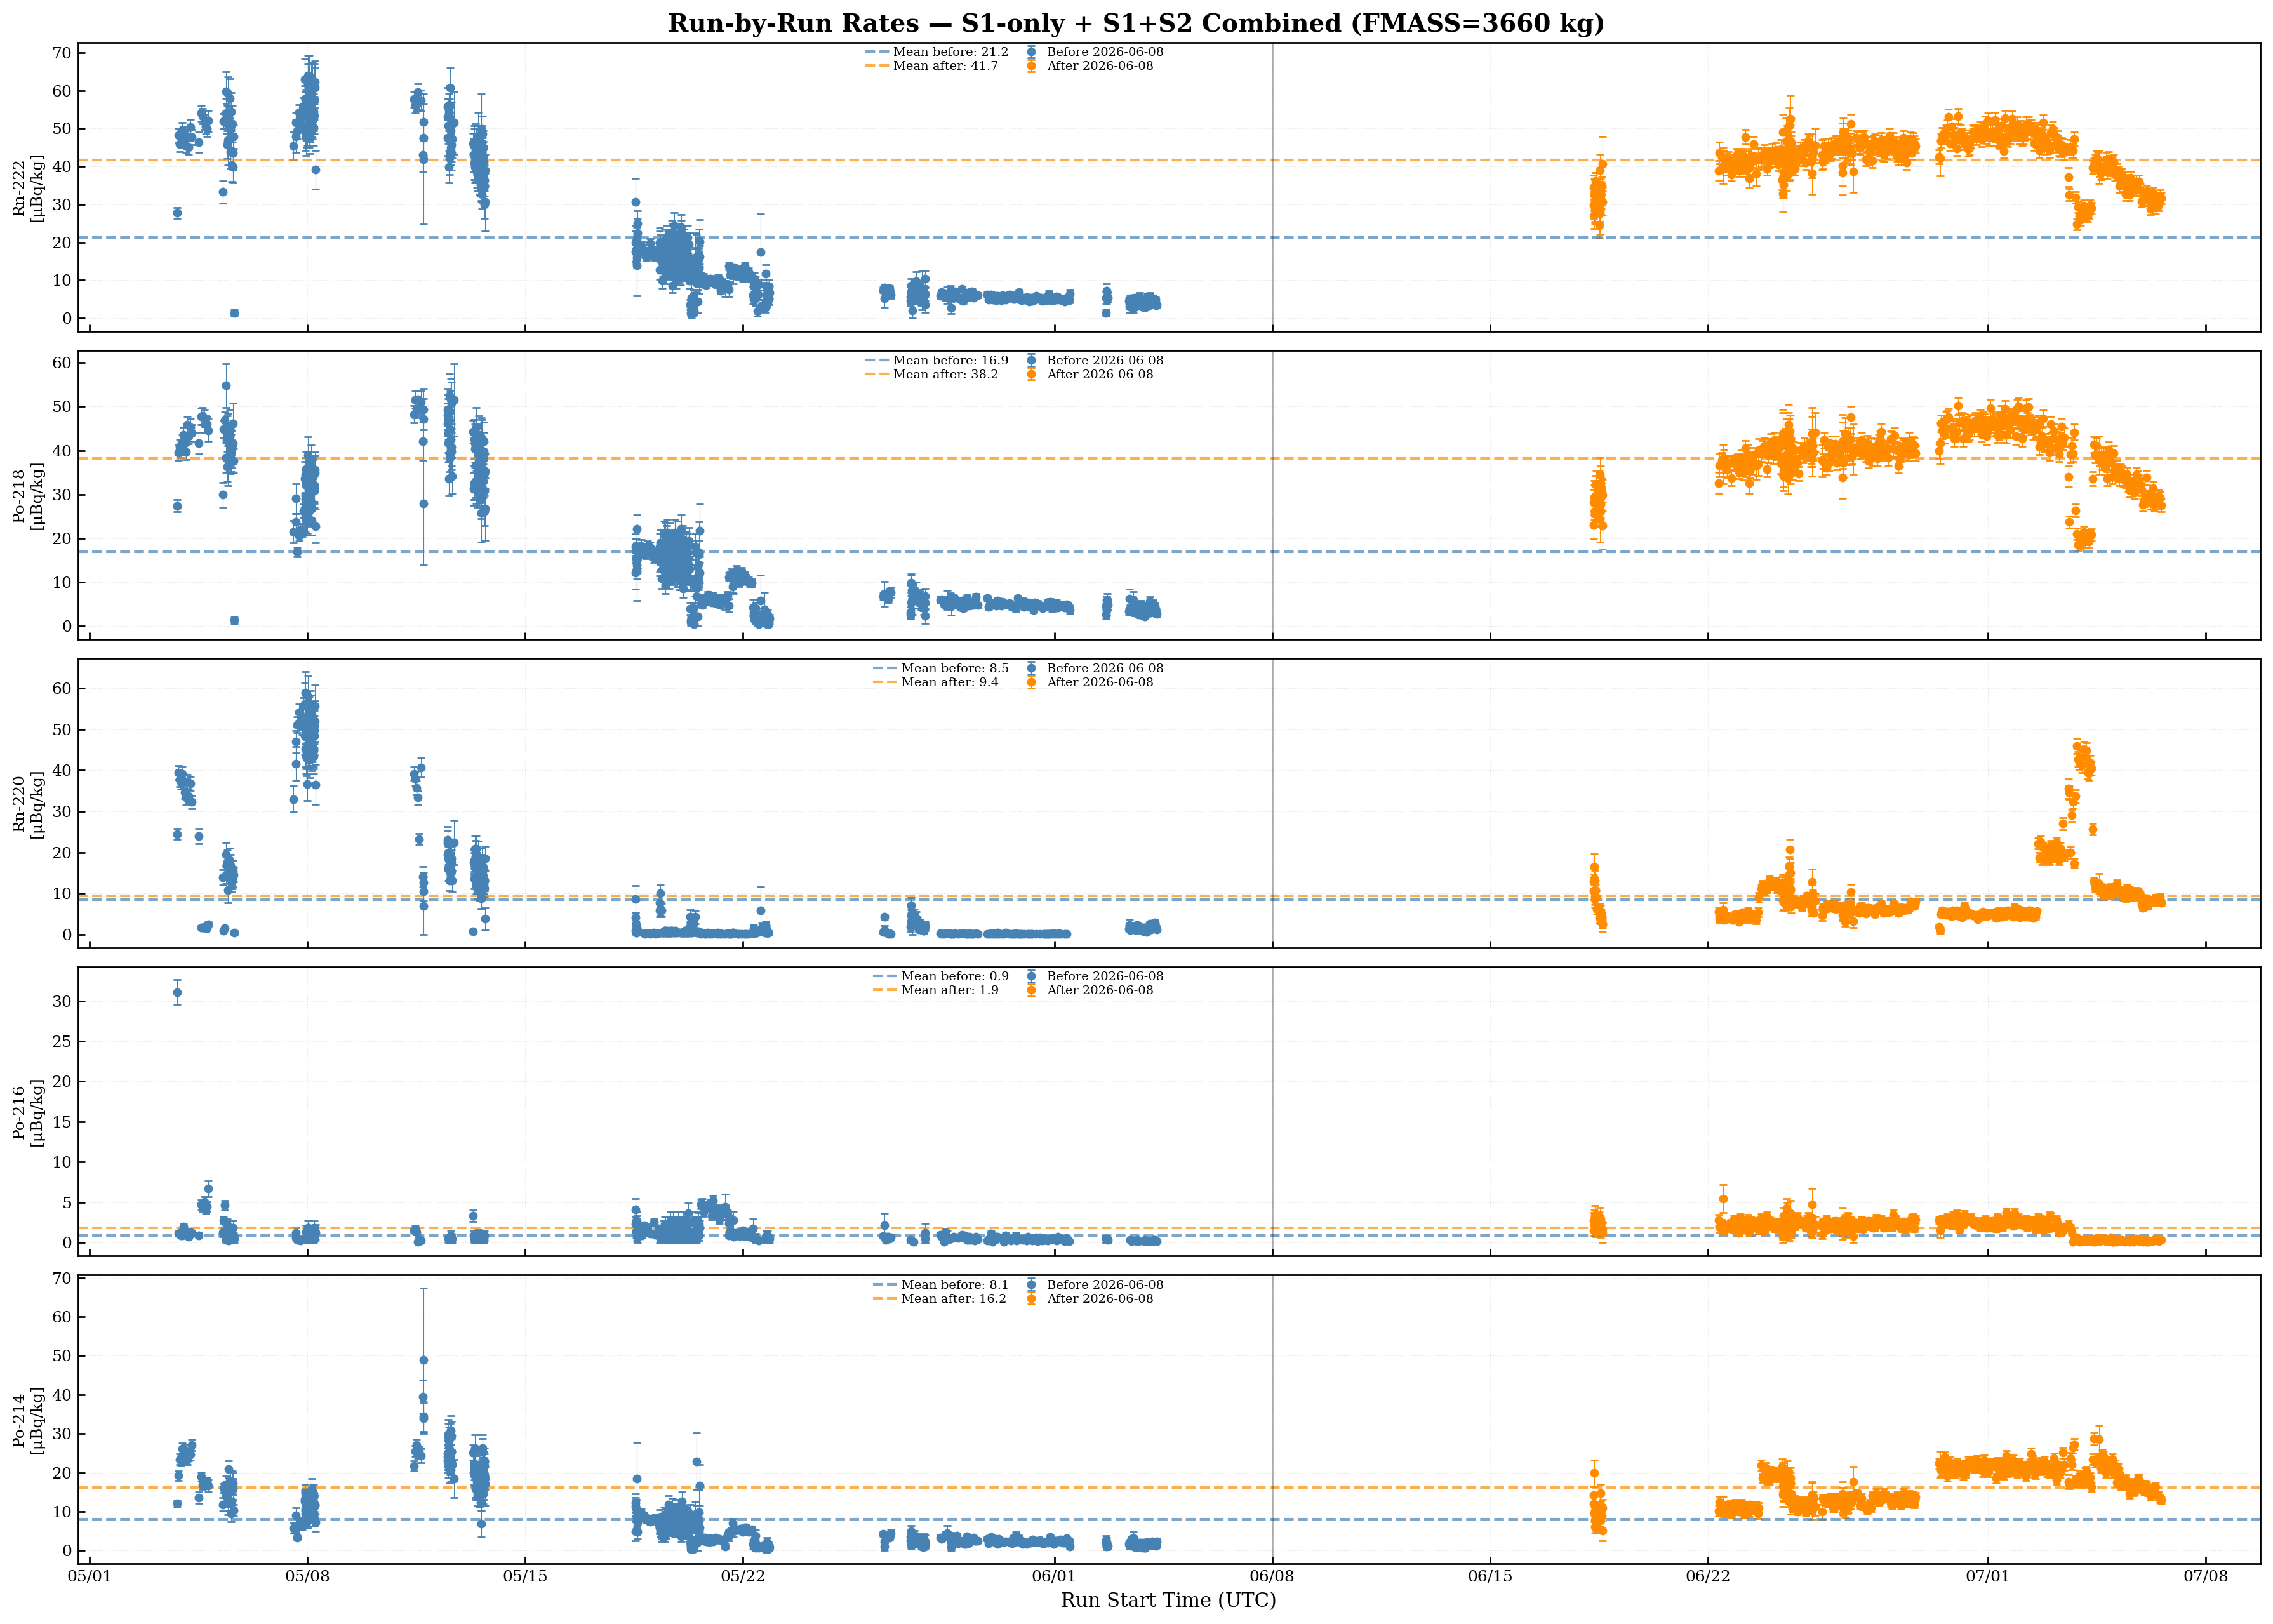


  FULL DATASET RATE SUMMARY (all isotopes)
  Rn-222     before:  582 runs   57,064 events  livetime=10.4 d  mean=21.2 ± 18.8 μBq/kg
  Rn-222     after :  373 runs  173,651 events  livetime=13.1 d  mean=41.7 ± 8.1 μBq/kg
  Po-218     before:  582 runs   46,747 events  livetime=10.4 d  mean=16.9 ± 14.5 μBq/kg
  Po-218     after :  373 runs  158,870 events  livetime=13.1 d  mean=38.2 ± 8.0 μBq/kg
  Rn-220     before:  582 runs   21,511 events  livetime=10.4 d  mean=8.5 ± 15.2 μBq/kg
  Rn-220     after :  373 runs   39,632 events  livetime=13.1 d  mean=9.4 ± 8.0 μBq/kg
  Po-216     before:  582 runs    3,797 events  livetime=10.4 d  mean=0.9 ± 1.6 μBq/kg
  Po-216     after :  373 runs    7,524 events  livetime=13.1 d  mean=1.9 ± 1.0 μBq/kg
  Po-214     before:  582 runs   22,140 events  livetime=10.4 d  mean=8.1 ± 7.5 μBq/kg
  Po-214     after :  373 runs   69,181 events  livetime=13.1 d  mean=16.2 ± 5.1 μBq/kg


In [ ]:
# ═══════════════════════════════════════════════════════════════
# MERGE S1-only + S1-S2 RATES → Full Dataset
# ═══════════════════════════════════════════════════════════════
# 5-panel plot (one per isotope), before/after colours only.

# ── Load both CSVs ──
path_s1only = '/project2/lgrandi/jietang/sr3_commissioning/sr3_s1only_rn_rates_0707.csv'
path_s1s2   = '/project2/lgrandi/jietang/sr3_commissioning/sr3_s1s2_rn_rates_0707.csv'

df_s1only = pd.read_csv(path_s1only)
df_s1s2   = pd.read_csv(path_s1s2)

df_s1only['source'] = 'S1-only'
df_s1s2['source']   = 'S1+S2'

# ── Merge ──
df_full = pd.concat([df_s1only, df_s1s2], ignore_index=True)
df_full = df_full.sort_values('start_s').reset_index(drop=True)

# Save merged
outpath = '/project2/lgrandi/jietang/sr3_commissioning/sr3_full_rn_rates_0707.csv'
df_full.to_csv(outpath, index=False)
print(f'Merged: {len(df_s1only)} S1-only + {len(df_s1s2)} S1+S2 = {len(df_full)} rows')
print(f'Saved → {outpath}')

# ── 5-panel plot ──
from datetime import datetime, timezone

iso_list = [n for n in PEAK_NAMES if n in df_full['isotope'].unique()]
fig, axes = plt.subplots(len(iso_list), 1, figsize=(18, 2.6 * len(iso_list)), sharex=True)

cutoff_dt = pd.Timestamp(CUTOFF_DATE, tz='UTC')

for ax, name in zip(axes, iso_list):
    df_iso = df_full[df_full['isotope'] == name]

    start_dt = [datetime.fromtimestamp(s, tz=timezone.utc) for s in df_iso['start_s']]
    mask_b = df_iso['period'] == 'before'
    mask_a = df_iso['period'] == 'after'

    # Before (steelblue)
    nz_b = mask_b & (df_iso['rate_ukgb'] > 0)
    ax.errorbar(np.array(start_dt)[nz_b], df_iso.loc[nz_b, 'rate_ukgb'].values,
                yerr=df_iso.loc[nz_b, 'rate_err_ukgb'].values,
                fmt='o', color='steelblue', markersize=4, capsize=2, lw=0.4,
                label=f'Before {CUTOFF_DATE}')

    # After (darkorange)
    nz_a = mask_a & (df_iso['rate_ukgb'] > 0)
    ax.errorbar(np.array(start_dt)[nz_a], df_iso.loc[nz_a, 'rate_ukgb'].values,
                yerr=df_iso.loc[nz_a, 'rate_err_ukgb'].values,
                fmt='o', color='darkorange', markersize=4, capsize=2, lw=0.4,
                label=f'After {CUTOFF_DATE}')

    # Mean lines (computed on all data, not just y>0)
    mean_b = df_iso.loc[mask_b, 'rate_ukgb'].mean()
    mean_a = df_iso.loc[mask_a, 'rate_ukgb'].mean()
    ax.axhline(y=mean_b, color='steelblue', ls='--', lw=1.5, alpha=0.7,
               label=f'Mean before: {mean_b:.1f}')
    ax.axhline(y=mean_a, color='darkorange', ls='--', lw=1.5, alpha=0.7,
               label=f'Mean after: {mean_a:.1f}')

    # Cutoff line
    ax.axvline(x=cutoff_dt, color='black', ls='-', lw=1, alpha=0.3)

    ax.set_ylabel(f'{name}\n[μBq/kg]', fontsize=9)
    ax.legend(fontsize=7, loc='upper right', ncol=2)
    ax.grid(True, alpha=0.25)

import matplotlib.dates as mdates
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%d', tz=timezone.utc))
axes[-1].xaxis.set_major_locator(mdates.AutoDateLocator())
axes[-1].set_xlabel('Run Start Time (UTC)', fontsize=11)
fig.autofmt_xdate(rotation=0, ha='center')
fig.suptitle('Run-by-Run Rates — S1-only + S1+S2 Combined (FMASS=3660 kg)',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

# ── Summary ──
print(f'\n{"="*75}')
print(f'  FULL DATASET RATE SUMMARY (all isotopes)')
print(f'{"="*75}')
for name in iso_list:
    df_iso = df_full[df_full['isotope'] == name]
    for period in ['before', 'after']:
        df_p = df_iso[df_iso['period'] == period]
        if len(df_p) == 0:
            continue
        total_ev = df_p['n_events'].sum()
        total_lt = df_p['livetime_s'].sum()
        print(f'  {name:10s} {period:6s}: {len(df_p):4d} runs  '
              f'{total_ev:7,} events  '
              f'livetime={total_lt/86400:.1f} d  '
              f'mean={df_p["rate_ukgb"].mean():.1f} ± {df_p["rate_ukgb"].std():.1f} μBq/kg')
print(f'{"="*75}')


---
## Analysis Summary

**Data:** S1-only alpha candidates from SR3 commissioning runs.

**Pre-correction cuts:**
1. Pulse width [40, 200] ns — S1 pulse shape selection
2. r² < 3800 cm² — TPC wall rejection

**Corrections (in order):**
1. **Area vs AFT** — Two-step: (a) initial fit with manual exp_bump_model boundaries, (b) refine selection to vertical band (±1σ) in area_aft_corrected, re-fit centerline, normalize to AFT=0.30 → `area_aft_corrected`. Rn band tagged as vertical cut in corrected space → `in_rn_band`
2. **AFT vs r²** — r²(AFT) degree-N polynomial fitted on Rn-band events, r² corrected to reference AFT → `r2_aft_corrected`
3. **r² vs Area** — band selected with linear boundaries (k=-120) in r2_aft_corrected vs area_aft_corrected space, degree-5 polynomial fit (r²<60), area corrected to r²=0 → `area_2_corrected`

**Post-correction cuts:**
- AFT fiducial [0.12, 0.55] — BiPo + gas band rejection
- FV cut [AFT 0.17–0.43, r² < 40 cm²] — tight fiducial volume

**Rate measurement:**
- Multi-Gaussian fit to AFT+r²-corrected 1D spectrum using ALL events after cuts
- 6 peaks: Rn-222, Po-218, Rn-220, Po-216, Po-214, Po-212
- Events counted within ±3σ window per peak

**Key DataFrames:**
- `df_cut` — after pre-correction cuts (full AFT range)
- `d_cor` — with all correction columns (`area_aft_corrected`, `r2_aft_corrected`, `area_2_corrected`, `in_rn_band`)
- `d_cor_aft` — after post-correction AFT+FV cuts, used for rate calculation